In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from IPython.display import display

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.filterwarnings("ignore")

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)
pd.set_option('display.width', 100000)

In [ ]:
dataframe = pd.read_csv('/content/Loandgb.csv', sep=",")
df = dataframe.copy()
df.head()

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status
0,0,37,35000,RENT,0,EDUCATION,B,6000,"11,49","0,17",N,14,0
1,1,22,56000,OWN,6,MEDICAL,C,4000,"13,35","0,07",N,2,0
2,2,29,28800,OWN,8,PERSONAL,A,6000,"8,9","0,21",N,10,0
3,3,30,70000,RENT,14,VENTURE,B,12000,"11,11","0,17",N,5,0
4,4,22,60000,RENT,2,MEDICAL,A,6000,"6,92","0,1",N,3,0


In [ ]:
df["loan_status"] = df["loan_status"].astype("int")

In [ ]:
df.columns

Index(['id', 'person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length', 'loan_status'], dtype='object')



# Keşifçi Veri Analizi - Exploratory Data Analysis (EDA)

In [ ]:
def check_df(dataframe, head=5):
    display("##################### Shape #####################")
    display(dataframe.shape)
    display("##################### Info #####################")
    display(dataframe.info())
    display("##################### NA #####################")
    display(dataframe.isnull().sum())
    display("##################### Describe #####################")
    display(dataframe.describe([0.01, 0.05, 0.1, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).T)

In [ ]:
check_df(df, 5)

'##################### Shape #####################'

(58645, 13)

'##################### Info #####################'

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58645 entries, 0 to 58644
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   id                          58645 non-null  int64 
 1   person_age                  58645 non-null  int64 
 2   person_income               58645 non-null  int64 
 3   person_home_ownership       58645 non-null  object
 4   person_emp_length           58645 non-null  int64 
 5   loan_intent                 58645 non-null  object
 6   loan_grade                  58645 non-null  object
 7   loan_amnt                   58645 non-null  int64 
 8   loan_int_rate               58645 non-null  object
 9   loan_percent_income         58645 non-null  object
 10  cb_person_default_on_file   58645 non-null  object
 11  cb_person_cred_hist_length  58645 non-null  int64 
 12  loan_status                 58645 non-null  int64 
dtypes: int64(7), object(6)
memory usage: 5.8+ MB


None

'##################### NA #####################'

,0
id,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,0
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,0
loan_percent_income,0


'##################### Describe #####################'

,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max
id,58645.000,29322.000,16929.498,0.000,586.440,2932.200,5864.400,14661.000,29322.000,43983.000,52779.600,55711.800,58057.560,58644.000
person_age,58645.000,27.551,6.033,20.000,21.000,22.000,22.000,23.000,26.000,30.000,36.000,39.000,49.000,123.000
person_income,58645.000,64046.173,37931.107,4200.000,21600.000,28800.000,31200.000,42000.000,58000.000,75600.000,100000.000,120000.000,175000.000,1900000.000
person_emp_length,58645.000,4.701,3.960,0.000,0.000,0.000,0.000,2.000,4.000,7.000,10.000,12.000,17.000,123.000
loan_amnt,58645.000,9217.557,5563.807,500.000,1286.000,2500.000,3000.000,5000.000,8000.000,12000.000,16000.000,20000.000,25000.000,35000.000
cb_person_cred_hist_length,58645.000,5.814,4.029,2.000,2.000,2.000,2.000,3.000,4.000,8.000,11.000,14.000,17.000,30.000
loan_status,58645.000,0.142,0.349,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000,1.000,1.000


In [ ]:
def grab_col_names(dataframe, cat_th=10,  car_th=20):
    """
    Veri setindeki kategorik, numerik ve kategorik fakat kardinal değişkenlerin isimlerini verir.

    Parameters
    ----------
    dataframe: dataframe
        değişken isimleri alınmak istenen dataframe'dir.
    cat_th: int, float
        numerik fakat kategorik olan değişkenler için sınıf eşik değeri
    car_th: int, float
        kategorik fakat kardinal değişkenler için sınıf eşik değeri

    Returns
    -------
    cat_cols: list
        Kategorik değişken listesi
    num_cols: list
        Numerik değişken listesi
    cat_but_car: list
        Kategorik görünümlü kardinal değişken listesi

    Notes
    ------
    cat_cols + num_cols + cat_but_car = toplam değişken sayısı
    num_but_cat cat_cols'un içerisinde.

    """
    # cat_cols, cat_but_car
    cat_cols = [col for col in dataframe.columns if str(dataframe[col].dtypes) in ["category", "object", "bool"]]

    num_but_cat = [col for col in dataframe.columns if dataframe[col].nunique() < cat_th and dataframe[col].dtypes in ["int", "float"]]

    cat_but_car = [col for col in dataframe.columns if
                   dataframe[col].nunique() > car_th and str(dataframe[col].dtypes) in ["category", "object"]]

    cat_cols = cat_cols + num_but_cat
    cat_cols = [col for col in cat_cols if col not in cat_but_car]

    num_cols = [col for col in dataframe.columns if dataframe[col].dtypes in ["int", "float"]]
    num_cols = [col for col in num_cols if col not in cat_cols]

    print(f"Observations: {dataframe.shape[0]}")
    print(f"Variables: {dataframe.shape[1]}")
    print(f'cat_cols: {len(cat_cols)}')
    print(f'num_cols: {len(num_cols)}')
    print(f'cat_but_car: {len(cat_but_car)}')
    print(f'num_but_cat: {len(num_but_cat)}')

    return cat_cols, num_cols, cat_but_car, num_but_cat

In [ ]:
cat_cols, num_cols, cat_but_car, num_but_cat = grab_col_names(df)

Observations: 58645
Variables: 13
cat_cols: 5
num_cols: 6
cat_but_car: 2
num_but_cat: 1


In [ ]:
display(cat_cols)

['person_home_ownership',
 'loan_intent',
 'loan_grade',
 'cb_person_default_on_file',
 'loan_status']

In [ ]:
display(num_cols)

['id',
 'person_age',
 'person_income',
 'person_emp_length',
 'loan_amnt',
 'cb_person_cred_hist_length']

In [ ]:
display(cat_but_car)

['loan_int_rate', 'loan_percent_income']

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58645 entries, 0 to 58644
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   id                          58645 non-null  int64 
 1   person_age                  58645 non-null  int64 
 2   person_income               58645 non-null  int64 
 3   person_home_ownership       58645 non-null  object
 4   person_emp_length           58645 non-null  int64 
 5   loan_intent                 58645 non-null  object
 6   loan_grade                  58645 non-null  object
 7   loan_amnt                   58645 non-null  int64 
 8   loan_int_rate               58645 non-null  object
 9   loan_percent_income         58645 non-null  object
 10  cb_person_default_on_file   58645 non-null  object
 11  cb_person_cred_hist_length  58645 non-null  int64 
 12  loan_status                 58645 non-null  int64 
dtypes: int64(7), object(6)
memory usage: 5.8+ MB


In [ ]:

def convert_column_types(dataframe, cat_cols, num_cols, cat_but_car, num_but_cat):
    """
    num_but_cat olanları kategorik tipe,
    cat_but_car olanları numerik tipe,
    object olanları kategorik tipe çevirir.
    """

    for col in cat_cols:
       df[col] = df[col].astype("category")


    # numerik görünümlü ama aslında kategorik olanlar → category
    for col in num_but_cat:
        dataframe[col] = dataframe[col].astype("category")

    # kategorik görünümlü ama kardinal olanlar → numerik (int veya float seçimi)
    for col in cat_but_car:
         df[col] = (df[col].astype(str).str.replace(',', '.', regex=False).str.replace('%', '', regex=False))
         df[col] = pd.to_numeric(df[col], errors="coerce")



    return dataframe


In [ ]:
df = convert_column_types(df, cat_cols, num_cols, cat_but_car, num_but_cat)

df.dtypes


,0
id,int64
person_age,int64
person_income,int64
person_home_ownership,category
person_emp_length,int64
loan_intent,category
loan_grade,category
loan_amnt,int64
loan_int_rate,float64
loan_percent_income,float64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58645 entries, 0 to 58644
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   id                          58645 non-null  int64   
 1   person_age                  58645 non-null  int64   
 2   person_income               58645 non-null  int64   
 3   person_home_ownership       58645 non-null  category
 4   person_emp_length           58645 non-null  int64   
 5   loan_intent                 58645 non-null  category
 6   loan_grade                  58645 non-null  category
 7   loan_amnt                   58645 non-null  int64   
 8   loan_int_rate               58645 non-null  float64 
 9   loan_percent_income         58645 non-null  float64 
 10  cb_person_default_on_file   58645 non-null  category
 11  cb_person_cred_hist_length  58645 non-null  int64   
 12  loan_status                 58645 non-null  category
dtypes: category(5), 

In [ ]:
df["loan_status"].value_counts()*100 / df.shape[0]

,count
loan_status,
0,85.762
1,14.238



# KREDİ PORTFÖYÜ RİSK-FAİZ ANALİZİ
# Platform Tipi Tespiti (Banka vs P2P)


In [ ]:
print("="*80)
print("KREDİ PORTFÖYÜ RİSK-FAİZ ANALİZİ")
print("="*80)
print(f"\n📊 Veri Seti Özeti:")
print(f"• Toplam Kredi Sayısı: {len(df):,}")
print(f"• Toplam Portföy Büyüklüğü: ${df['loan_amnt'].sum():,.0f}")
print(f"• Ortalama Kredi Tutarı: ${df['loan_amnt'].mean():,.2f}")

KREDİ PORTFÖYÜ RİSK-FAİZ ANALİZİ

📊 Veri Seti Özeti:
• Toplam Kredi Sayısı: 58,645
• Toplam Portföy Büyüklüğü: $540,563,602
• Ortalama Kredi Tutarı: $9,217.56


In [ ]:
print("\n" + "="*80)
print("FAİZ ORANLARI ANALİZİ")
print("="*80)

# Genel faiz istatistikleri
print(f"\n📈 Faiz Oranı İstatistikleri:")
print(f"• Ortalama Faiz: %{df['loan_int_rate'].mean():.2f}")
print(f"• Medyan Faiz: %{df['loan_int_rate'].median():.2f}")
print(f"• Minimum Faiz: %{df['loan_int_rate'].min():.2f}")
print(f"• Maximum Faiz: %{df['loan_int_rate'].max():.2f}")
print(f"• Standart Sapma: %{df['loan_int_rate'].std():.2f}")


FAİZ ORANLARI ANALİZİ

📈 Faiz Oranı İstatistikleri:
• Ortalama Faiz: %10.68
• Medyan Faiz: %10.75
• Minimum Faiz: %5.42
• Maximum Faiz: %23.22
• Standart Sapma: %3.03


In [ ]:
df["loan_status"] = df["loan_status"].astype("int")

print("\n" + "="*80)
print("DEFAULT (NPL) ANALİZİ")
print("="*80)

default_rate = df['loan_status'].mean() * 100
print(f"\n⚠️ Default (NPL) Oranları:")
print(f"• Toplam Default Oranı: %{default_rate:.2f}")
print(f"• Başarılı Geri Ödeme: %{100-default_rate:.2f}")
print(f"• Batık Kredi Sayısı: {df['loan_status'].sum():,}")
print(f"• Batık Kredi Tutarı: ${df[df['loan_status']==1]['loan_amnt'].sum():,.0f}")


DEFAULT (NPL) ANALİZİ

⚠️ Default (NPL) Oranları:
• Toplam Default Oranı: %14.24
• Başarılı Geri Ödeme: %85.76
• Batık Kredi Sayısı: 8,350
• Batık Kredi Tutarı: $93,497,220


In [ ]:
df.head()

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status
0,0,37,35000,RENT,0,EDUCATION,B,6000,11.490,0.170,N,14,0
1,1,22,56000,OWN,6,MEDICAL,C,4000,13.350,0.070,N,2,0
2,2,29,28800,OWN,8,PERSONAL,A,6000,8.900,0.210,N,10,0
3,3,30,70000,RENT,14,VENTURE,B,12000,11.110,0.170,N,5,0
4,4,22,60000,RENT,2,MEDICAL,A,6000,6.920,0.100,N,3,0


In [ ]:
grade_analysis = df.groupby('loan_grade').agg({
    'loan_status': ['count', 'mean'],
    'loan_int_rate': 'mean',
    'loan_amnt': 'mean'
}).round(2)

grade_analysis.head()

loan_status       loan_int_rate loan_amnt
                 count  mean          mean      mean
loan_grade                                          
A                20984 0.050         7.340  8447.100
B                20400 0.100        11.030  9622.490
C                11036 0.140        13.510  9009.890
D                 5034 0.590        15.400 10521.470
E                 1009 0.630        16.930 12176.310

In [ ]:
# ============================================
# BÖLÜM 4: GRADE BAZLI RİSK-FAİZ ANALİZİ
# ============================================

print("\n" + "="*80)
print("GRADE BAZLI RİSK-FAİZ-GETİRİ ANALİZİ")
print("="*80)

# Grade bazlı analiz
grade_analysis = df.groupby('loan_grade').agg({
    'loan_status': ['count', 'mean'],
    'loan_int_rate': 'mean',
    'loan_amnt': 'mean'
}).round(2)

grade_analysis.columns = ['Kredi_Sayısı', 'Default_Oranı', 'Ort_Faiz', 'Ort_Kredi']
grade_analysis['Default_Oranı'] = grade_analysis['Default_Oranı'] * 100

# Net getiri hesaplama
grade_analysis['Net_Getiri'] = (
    grade_analysis['Ort_Faiz'] * (1 - grade_analysis['Default_Oranı']/100) -
    grade_analysis['Default_Oranı']
)

grade_analysis["Net_Tutar_$"] = grade_analysis["Net_Getiri"]/100 * grade_analysis["Ort_Kredi"]


# Karlılık durumu
grade_analysis['Durum'] = grade_analysis['Net_Getiri'].apply(
    lambda x: '✅ KARLI' if x > 0 else '❌ ZARARLI'
)

print("\n" + grade_analysis.to_string())


GRADE BAZLI RİSK-FAİZ-GETİRİ ANALİZİ

            Kredi_Sayısı  Default_Oranı  Ort_Faiz  Ort_Kredi  Net_Getiri  Net_Tutar_$      Durum
loan_grade                                                                                      
A                  20984          5.000     7.340   8447.100       1.973      166.661    ✅ KARLI
B                  20400         10.000    11.030   9622.490      -0.073       -7.024  ❌ ZARARLI
C                  11036         14.000    13.510   9009.890      -2.381     -214.562  ❌ ZARARLI
D                   5034         59.000    15.400  10521.470     -52.686    -5543.342  ❌ ZARARLI
E                   1009         63.000    16.930  12176.310     -56.736    -6908.339  ❌ ZARARLI
F                    149         61.000    18.610  12833.890     -53.742    -6897.202  ❌ ZARARLI
G                     33         82.000    20.330  12559.090     -78.341    -9838.866  ❌ ZARARLI


In [ ]:
grade_analysis.head()

,Kredi_Sayısı,Default_Oranı,Ort_Faiz,Ort_Kredi,Net_Getiri,Net_Tutar_$,Durum
loan_grade,,,,,,,
A,20984,5.000,7.340,8447.100,1.973,166.661,✅ KARLI
B,20400,10.000,11.030,9622.490,-0.073,-7.024,❌ ZARARLI
C,11036,14.000,13.510,9009.890,-2.381,-214.562,❌ ZARARLI
D,5034,59.000,15.400,10521.470,-52.686,-5543.342,❌ ZARARLI
E,1009,63.000,16.930,12176.310,-56.736,-6908.339,❌ ZARARLI


In [ ]:
df.head()

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status
0,0,37,35000,RENT,0,EDUCATION,B,6000,11.490,0.170,N,14,0
1,1,22,56000,OWN,6,MEDICAL,C,4000,13.350,0.070,N,2,0
2,2,29,28800,OWN,8,PERSONAL,A,6000,8.900,0.210,N,10,0
3,3,30,70000,RENT,14,VENTURE,B,12000,11.110,0.170,N,5,0
4,4,22,60000,RENT,2,MEDICAL,A,6000,6.920,0.100,N,3,0


In [ ]:
print("\n" + "="*80)
print("PORTFÖY NET GETİRİ ANALİZİ")
print("="*80)

# Portföy seviyesinde hesaplamalar
portfolio_avg_rate = df['loan_int_rate'].mean()
portfolio_default_rate = df['loan_status'].mean() * 100

# Net getiri formülü: Faiz * (1 - Default Rate) - Default Rate * (LGD)
portfolio_net_return = portfolio_avg_rate * (1 - portfolio_default_rate/100) - portfolio_default_rate

# Başa baş faiz oranı
breakeven_rate = portfolio_default_rate / (1 - portfolio_default_rate/100)

print(f"\n💰 Portföy Getiri Analizi:")
print(f"• Ortalama Faiz Oranı: %{portfolio_avg_rate:.2f}")
print(f"• Default Oranı: %{portfolio_default_rate:.2f}")
print(f"• Net Getiri: %{portfolio_net_return:.2f}")
print(f"• Başa Baş Faiz Oranı: %{breakeven_rate:.2f}")

if portfolio_net_return > 0:
    print(f"\n✅ SONUÇ: Portföy KARLI (Net getiri: %{portfolio_net_return:.2f})")
else:
    print(f"\n❌ SONUÇ: Portföy ZARARLI (Net zarar: %{abs(portfolio_net_return):.2f})")
    print(f"   → Faizleri minimum %{breakeven_rate:.2f} yapmalısınız!")


PORTFÖY NET GETİRİ ANALİZİ

💰 Portföy Getiri Analizi:
• Ortalama Faiz Oranı: %10.68
• Default Oranı: %14.24
• Net Getiri: %-5.08
• Başa Baş Faiz Oranı: %16.60

❌ SONUÇ: Portföy ZARARLI (Net zarar: %5.08)
   → Faizleri minimum %16.60 yapmalısınız!


In [ ]:
# BÖLÜM 6: PLATFORM TİPİ TESPİTİ
# ============================================

print("\n" + "="*80)
print("PLATFORM TİPİ ANALİZİ: BANKA MI? P2P Mİ?")
print("="*80)

# Platform tipi göstergeleri
indicators = {
    'P2P_indicators': 0,
    'Bank_indicators': 0,
    'reasons': []
}

# 1. Default oranı kontrolü
if default_rate > 10:
    indicators['P2P_indicators'] += 1
    indicators['reasons'].append(f"• Yüksek default oranı (%{default_rate:.1f}) → P2P platformları için tipik")
else:
    indicators['Bank_indicators'] += 1
    indicators['reasons'].append(f"• Düşük default oranı (%{default_rate:.1f}) → Geleneksel banka için tipik")

# 2. Faiz oranı aralığı
interest_range = df['loan_int_rate'].max() - df['loan_int_rate'].min()
if interest_range > 15:
    indicators['P2P_indicators'] += 1
    indicators['reasons'].append(f"• Geniş faiz aralığı (%{interest_range:.1f}) → Risk-based pricing (P2P)")
else:
    indicators['Bank_indicators'] += 1
    indicators['reasons'].append(f"• Dar faiz aralığı (%{interest_range:.1f}) → Standart banka fiyatlaması")

# 3. Grade sistemi varlığı
unique_grades = df['loan_grade'].nunique()
if unique_grades == 7 and set(df['loan_grade'].unique()) == {'A','B','C','D','E','F','G'}:
    indicators['P2P_indicators'] += 1
    indicators['reasons'].append("• A-G grade sistemi → LendingClub/Prosper tarzı P2P")

# 4. Kredi amaçları
purposes = df['loan_intent'].unique()
if 'MEDICAL' in purposes:
    indicators['P2P_indicators'] += 1
    indicators['reasons'].append("• Medical loans → ABD P2P platformları için tipik")

# 5. Ortalama kredi tutarı
avg_loan = df['loan_amnt'].mean()
if 5000 < avg_loan < 20000:
    indicators['P2P_indicators'] += 1
    indicators['reasons'].append(f"• Ortalama kredi ${avg_loan:.0f} → P2P personal loan aralığı")

# 6. Subprime segment büyüklüğü
subprime_ratio = len(df[df['loan_grade'].isin(['E','F','G'])]) / len(df) * 100
if subprime_ratio > 15:
    indicators['P2P_indicators'] += 1
    indicators['reasons'].append(f"• Yüksek subprime oranı (%{subprime_ratio:.1f}) → P2P risk iştahı")

print("\n📊 Platform Tipi Göstergeleri:")
print(f"• P2P Platform Göstergeleri: {indicators['P2P_indicators']}/6")
print(f"• Geleneksel Banka Göstergeleri: {indicators['Bank_indicators']}/6")

print("\n🔍 Tespit Edilen Özellikler:")
for reason in indicators['reasons']:
    print(reason)

# Sonuç
print("\n" + "="*50)
if indicators['P2P_indicators'] > indicators['Bank_indicators']:
    print("🎯 SONUÇ: Bu büyük ihtimalle bir P2P LENDING PLATFORMU!")
    print("   (LendingClub, Prosper veya benzeri)")
else:
    print("🎯 SONUÇ: Bu büyük ihtimalle GELENEKSEL BANKA kredileri!")


PLATFORM TİPİ ANALİZİ: BANKA MI? P2P Mİ?

📊 Platform Tipi Göstergeleri:
• P2P Platform Göstergeleri: 5/6
• Geleneksel Banka Göstergeleri: 0/6

🔍 Tespit Edilen Özellikler:
• Yüksek default oranı (%14.2) → P2P platformları için tipik
• Geniş faiz aralığı (%17.8) → Risk-based pricing (P2P)
• A-G grade sistemi → LendingClub/Prosper tarzı P2P
• Medical loans → ABD P2P platformları için tipik
• Ortalama kredi $9218 → P2P personal loan aralığı

🎯 SONUÇ: Bu büyük ihtimalle bir P2P LENDING PLATFORMU!
   (LendingClub, Prosper veya benzeri)


In [ ]:
# ============================================
# BÖLÜM 5: PORTFÖY NET GETİRİ ANALİZİ
# ============================================

# print("\n" + "="*80)
# print("PORTFÖY NET GETİRİ ANALİZİ")
# print("="*80)

print("\n" + "="*80)
print("PORTFOLIO NET RETURN ANALYSIS")
print("="*80)


# Portföy seviyesinde hesaplamalar
portfolio_avg_rate = df['loan_int_rate'].mean()
portfolio_default_rate = df['loan_status'].mean() * 100

# Net getiri formülü: Faiz * (1 - Default Rate) - Default Rate * (LGD)
# Assuming LGD (Loss Given Default) is 100% for simplicity in this net return calculation
portfolio_net_return = portfolio_avg_rate * (1 - portfolio_default_rate/100) - portfolio_default_rate

# Başa baş faiz oranı
breakeven_rate = portfolio_default_rate / (1 - portfolio_default_rate/100) if portfolio_default_rate < 100 else float('inf')


# print(f"\n💰 Portföy Getiri Analizi:")
# print(f"• Ortalama Faiz Oranı: %{portfolio_avg_rate:.2f}")
# print(f"• Default Oranı: %{portfolio_default_rate:.2f}")
# print(f"• Net Getiri: %{portfolio_net_return:.2f}")
# print(f"• Başa Baş Faiz Oranı: %{breakeven_rate:.2f}")

print(f"\n💰 Portfolio Return Analysis:")
print(f"• Average Interest Rate: %{portfolio_avg_rate:.2f}")
print(f"• Default Rate: %{portfolio_default_rate:.2f}")
print(f"• Net Return: %{portfolio_net_return:.2f}")
print(f"• Breakeven Interest Rate: %{breakeven_rate:.2f}")


# if portfolio_net_return > 0:
#     print(f"\n✅ SONUÇ: Portföy KARLI (Net getiri: %{portfolio_net_return:.2f})")
# else:
#     print(f"\n❌ SONUÇ: Portföy ZARARLI (Net zarar: %{abs(portfolio_net_return):.2f})")
#     print(f"   → Faizleri minimum %{breakeven_rate:.2f} yapmalısınız!")

if portfolio_net_return > 0:
    print(f"\n✅ RESULT: Portfolio PROFITABLE (Net return: %{portfolio_net_return:.2f})")
else:
    print(f"\n❌ RESULT: Portfolio LOSING MONEY (Net loss: %{abs(portfolio_net_return):.2f})")
    print(f"   → You should increase interest rates to minimum %{breakeven_rate:.2f}!")


PORTFOLIO NET RETURN ANALYSIS

💰 Portfolio Return Analysis:
• Average Interest Rate: %10.68
• Default Rate: %14.24
• Net Return: %-5.08
• Breakeven Interest Rate: %16.60

❌ RESULT: Portfolio LOSING MONEY (Net loss: %5.08)
   → You should increase interest rates to minimum %16.60!



GENERATING VISUALIZATIONS...


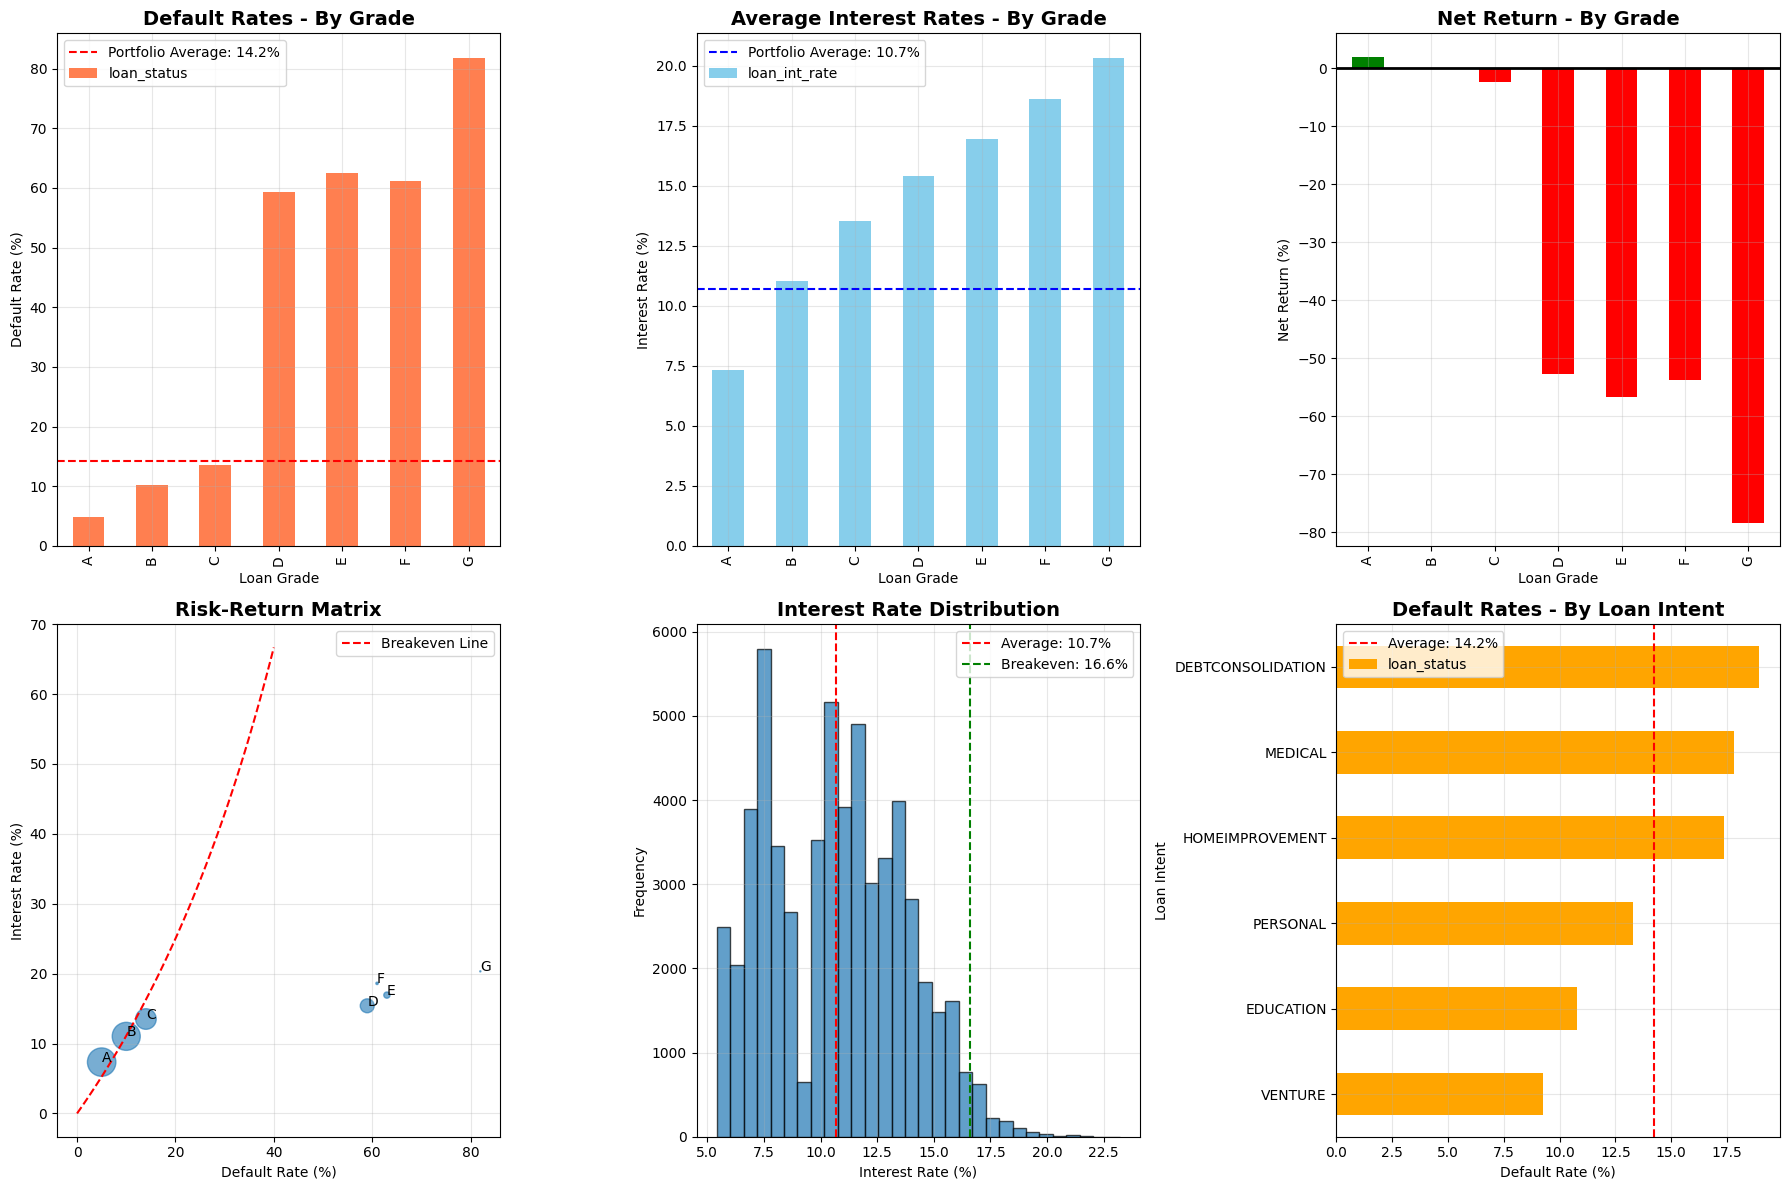

In [ ]:
# ============================================
# BÖLÜM 7: GÖRSELLEŞTIRMELER
# ============================================

# print("\n" + "="*80)
# print("GRAFİKLER OLUŞTURULUYOR...")
# print("="*80)

print("\n" + "="*80)
print("GENERATING VISUALIZATIONS...")
print("="*80)

# Grade bazlı analiz
grade_analysis = df.groupby('loan_grade').agg({
    'loan_status': ['count', 'mean'],
    'loan_int_rate': 'mean',
    'loan_amnt': 'mean'
}).round(2)

grade_analysis.columns = ['Kredi_Sayısı', 'Default_Oranı', 'Ort_Faiz', 'Ort_Kredi']
grade_analysis['Default_Oranı'] = grade_analysis['Default_Oranı'] * 100

# Net getiri hesaplama
grade_analysis['Net_Getiri'] = (
    grade_analysis['Ort_Faiz'] * (1 - grade_analysis['Default_Oranı']/100) -
    grade_analysis['Default_Oranı'] # Assuming LGD is 100%
)

# Karlılık durumu
grade_analysis['Durum'] = grade_analysis['Net_Getiri'].apply(
    lambda x: '✅ PROFITABLE' if x > 0 else '❌ LOSING MONEY'
)


# 1. Risk-Faiz Matrisi
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Grafik 1: Grade bazlı default oranları
ax1 = axes[0, 0]
grade_defaults = df.groupby('loan_grade')['loan_status'].mean() * 100
grade_defaults.plot(kind='bar', ax=ax1, color='coral')
# ax1.set_title('Default Oranları - Grade Bazlı', fontsize=14, fontweight='bold')
ax1.set_title('Default Rates - By Grade', fontsize=14, fontweight='bold')
ax1.set_xlabel('Loan Grade')
# ax1.set_ylabel('Default Oranı (%)')
ax1.set_ylabel('Default Rate (%)')
# ax1.axhline(y=default_rate, color='red', linestyle='--', label=f'Portföy Ortalaması: {default_rate:.1f}%')
ax1.axhline(y=default_rate, color='red', linestyle='--', label=f'Portfolio Average: {default_rate:.1f}%')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Grafik 2: Grade bazlı faiz oranları
ax2 = axes[0, 1]
grade_interest = df.groupby('loan_grade')['loan_int_rate'].mean()
grade_interest.plot(kind='bar', ax=ax2, color='skyblue')
# ax2.set_title('Ortalama Faiz Oranları - Grade Bazlı', fontsize=14, fontweight='bold')
ax2.set_title('Average Interest Rates - By Grade', fontsize=14, fontweight='bold')
ax2.set_xlabel('Loan Grade')
# ax2.set_ylabel('Faiz Oranı (%)')
ax2.set_ylabel('Interest Rate (%)')
# ax2.axhline(y=portfolio_avg_rate, color='blue', linestyle='--', label=f'Portföy Ortalaması: {portfolio_avg_rate:.1f}%')
ax2.axhline(y=portfolio_avg_rate, color='blue', linestyle='--', label=f'Portfolio Average: {portfolio_avg_rate:.1f}%')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Grafik 3: Net Getiri - Grade Bazlı
ax3 = axes[0, 2]
net_returns = grade_analysis['Net_Getiri']
colors = ['green' if x > 0 else 'red' for x in net_returns]
net_returns.plot(kind='bar', ax=ax3, color=colors)
# ax3.set_title('Net Getiri - Grade Bazlı', fontsize=14, fontweight='bold')
ax3.set_title('Net Return - By Grade', fontsize=14, fontweight='bold')
ax3.set_xlabel('Loan Grade')
# ax3.set_ylabel('Net Getiri (%)')
ax3.set_ylabel('Net Return (%)')
ax3.axhline(y=0, color='black', linestyle='-', linewidth=2)
ax3.grid(True, alpha=0.3)

# Grafik 4: Risk-Return Scatter
ax4 = axes[1, 0]
ax4.scatter(grade_analysis['Default_Oranı'], grade_analysis['Ort_Faiz'],
           s=grade_analysis['Kredi_Sayısı']/50, alpha=0.6) # Use Kredi_Sayısı for size
for idx, row in grade_analysis.iterrows():
    ax4.annotate(idx, (row['Default_Oranı'], row['Ort_Faiz']))
# ax4.set_title('Risk-Return Matrisi', fontsize=14, fontweight='bold')
ax4.set_title('Risk-Return Matrix', fontsize=14, fontweight='bold')
# ax4.set_xlabel('Default Oranı (%)')
ax4.set_xlabel('Default Rate (%)')
# ax4.set_ylabel('Faiz Oranı (%)')
ax4.set_ylabel('Interest Rate (%)')
# Başa baş çizgisi
x_range = np.linspace(0, 40, 100)
y_breakeven = x_range / (1 - x_range/100)
# ax4.plot(x_range, y_breakeven, 'r--', label='Başa Baş Çizgisi')
ax4.plot(x_range, y_breakeven, 'r--', label='Breakeven Line')
ax4.legend()
ax4.grid(True, alpha=0.3)

# Grafik 5: Faiz Dağılımı
ax5 = axes[1, 1]
ax5.hist(df['loan_int_rate'], bins=30, edgecolor='black', alpha=0.7)
# ax5.axvline(portfolio_avg_rate, color='red', linestyle='--', label=f'Ortalama: {portfolio_avg_rate:.1f}%')
ax5.axvline(portfolio_avg_rate, color='red', linestyle='--', label=f'Average: {portfolio_avg_rate:.1f}%')
# ax5.axvline(breakeven_rate, color='green', linestyle='--', label=f'Başa Baş: {breakeven_rate:.1f}%')
ax5.axvline(breakeven_rate, color='green', linestyle='--', label=f'Breakeven: {breakeven_rate:.1f}%')
# ax5.set_title('Faiz Oranı Dağılımı', fontsize=14, fontweight='bold')
ax5.set_title('Interest Rate Distribution', fontsize=14, fontweight='bold')
# ax5.set_xlabel('Faiz Oranı (%)')
ax5.set_xlabel('Interest Rate (%)')
# ax5.set_ylabel('Frekans')
ax5.set_ylabel('Frequency')
ax5.legend()
ax5.grid(True, alpha=0.3)

# Grafik 6: Loan Intent Analizi
ax6 = axes[1, 2]
intent_default = df.groupby('loan_intent')['loan_status'].mean() * 100
intent_default.sort_values().plot(kind='barh', ax=ax6, color='orange')
# ax6.set_title('Default Oranları - Kredi Amacına Göre', fontsize=14, fontweight='bold')
ax6.set_title('Default Rates - By Loan Intent', fontsize=14, fontweight='bold')
# ax6.set_xlabel('Default Oranı (%)')
ax6.set_xlabel('Default Rate (%)')
# ax6.set_ylabel('Kredi Amacı')
ax6.set_ylabel('Loan Intent')
# ax6.axvline(x=default_rate, color='red', linestyle='--', label=f'Ortalama: {default_rate:.1f}%')
ax6.axvline(x=default_rate, color='red', linestyle='--', label=f'Average: {default_rate:.1f}%')
ax6.legend()
ax6.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# BÖLÜM 8: DETAYLI SENARYO ANALİZİ
# ============================================


# print("\n" + "="*80)
# print("SENARYO ANALİZİ: FAİZ DEĞİŞİMİNİN ETKİSİ")
# print("="*80)

print("\n" + "="*80)
print("SCENARIO ANALYSIS: IMPACT OF INTEREST RATE CHANGES")
print("="*80)

# Başa baş noktasını hesapla
# breakeven_rate = portfolio_default_rate / (1 - portfolio_default_rate/100)
# print(f"\n💡 Başa Baş Faiz Oranı: %{breakeven_rate:.2f}")
# print(f"📊 Mevcut Faiz Oranı: %{portfolio_avg_rate:.2f}")
# print(f"⚠️ Aradaki Fark: %{breakeven_rate - portfolio_avg_rate:.2f} puan artırmalısınız!\n")

print(f"\n💡 Breakeven Interest Rate: %{breakeven_rate:.2f}")
print(f"📊 Current Average Interest Rate: %{portfolio_avg_rate:.2f}")
print(f"⚠️ Difference: You need to increase rates by %{breakeven_rate - portfolio_avg_rate:.2f} percentage points!\n")


# Genişletilmiş faiz senaryoları (başa baş ve ötesini içerecek şekilde)
# print("📊 Farklı Faiz Oranlarında Net Getiri:")
# print("-" * 60)
# print("Faiz Oranı | Net Getiri | Durum           | Açıklama")
# print("-" * 60)

print("📊 Net Return at Different Interest Rate Levels:")
print("-" * 60)
print("Interest Rate | Net Return | Status          | Explanation")
print("-" * 60)


# Daha geniş aralıkta senaryolar
rate_adjustments = [-3, -2, -1, 0, 1, 2, 3, 5, 6, 7, 8, 10]
results = []

for rate_adjustment in rate_adjustments:
    new_rate = portfolio_avg_rate + rate_adjustment
    new_net_return = new_rate * (1 - portfolio_default_rate/100) - portfolio_default_rate

    # Durum belirleme
    # if new_net_return < -5:
    #     status = "❌ Ağır Zarar"
    #     explanation = "Kritik durum!"
    # elif new_net_return < -2:
    #     status = "❌ Zararlı"
    #     explanation = "Zarar devam ediyor"
    # elif new_net_return < 0:
    #     status = "⚠️ Hafif Zarar"
    #     explanation = "Başa baş yakın"
    # elif new_net_return < 2:
    #     status = "✅ Düşük Kar"
    #     explanation = "Başa baş üstü"
    # elif new_net_return < 5:
    #     status = "✅ İyi Kar"
    #     explanation = "Sağlıklı getiri"
    # else:
    #     status = "💚 Yüksek Kar"
    #     explanation = "Mükemmel getiri"

    if new_net_return < -5:
        status = "❌ Significant Loss"
        explanation = "Critical situation!"
    elif new_net_return < -2:
        status = "❌ Losing Money"
        explanation = "Losses continue"
    elif new_net_return < 0:
        status = "⚠️ Slight Loss"
        explanation = "Near breakeven"
    elif new_net_return < 2:
        status = "✅ Low Profit"
        explanation = "Above breakeven"
    elif new_net_return < 5:
        status = "✅ Good Profit"
        explanation = "Healthy return"
    else:
        status = "💚 High Profit"
        explanation = "Excellent return"


    # Başa baş noktasına yakınlık kontrolü
    # if abs(new_rate - breakeven_rate) < 0.5:
    #     explanation = "📍 BAŞA BAŞ NOKTASI!"

    if abs(new_rate - breakeven_rate) < 0.5:
        explanation = "📍 BREAKEVEN POINT!"


    results.append({
        'Faiz': new_rate,
        'Net_Getiri': new_net_return,
        'Durum': status,
        'Açıklama': explanation
    })

    # print(f"%{new_rate:6.2f}    | %{new_net_return:8.2f}  | {status:14} | {explanation}")
    print(f"%{new_rate:6.2f}    | %{new_net_return:8.2f}  | {status:17} | {explanation}")


# Başa baş noktasını ekstra göster
# print("-" * 60)
# print(f"%{breakeven_rate:6.2f}    | %{0:8.2f}  | 🎯 BAŞA BAŞ     | Kar/Zarar sınırı")
# print("-" * 60)

print("-" * 60)
print(f"%{breakeven_rate:6.2f}    | %{0:8.2f}  | 🎯 BREAKEVEN      | Profit/Loss boundary")
print("-" * 60)

# Hedef kar için gereken faiz
target_profit = 3  # %3 kar hedefi
required_rate_for_profit = (portfolio_default_rate + target_profit) / (1 - portfolio_default_rate/100)
# print(f"%{required_rate_for_profit:6.2f}    | %{target_profit:8.2f}  | 🎯 HEDEF KAR   | Sağlıklı karlılık")
print(f"%{required_rate_for_profit:6.2f}    | %{target_profit:8.2f}  | 🎯 TARGET PROFIT  | Healthy profitability")

print("="*80)


SCENARIO ANALYSIS: IMPACT OF INTEREST RATE CHANGES

💡 Breakeven Interest Rate: %16.60
📊 Current Average Interest Rate: %10.68
⚠️ Difference: You need to increase rates by %5.92 percentage points!

📊 Net Return at Different Interest Rate Levels:
------------------------------------------------------------
Interest Rate | Net Return | Status          | Explanation
------------------------------------------------------------
%  7.68    | %   -7.65  | ❌ Significant Loss | Critical situation!
%  8.68    | %   -6.80  | ❌ Significant Loss | Critical situation!
%  9.68    | %   -5.94  | ❌ Significant Loss | Critical situation!
% 10.68    | %   -5.08  | ❌ Significant Loss | Critical situation!
% 11.68    | %   -4.22  | ❌ Losing Money    | Losses continue
% 12.68    | %   -3.37  | ❌ Losing Money    | Losses continue
% 13.68    | %   -2.51  | ❌ Losing Money    | Losses continue
% 15.68    | %   -0.79  | ⚠️ Slight Loss    | Near breakeven
% 16.68    | %    0.07  | ✅ Low Profit      | 📍 BREAKEVEN 

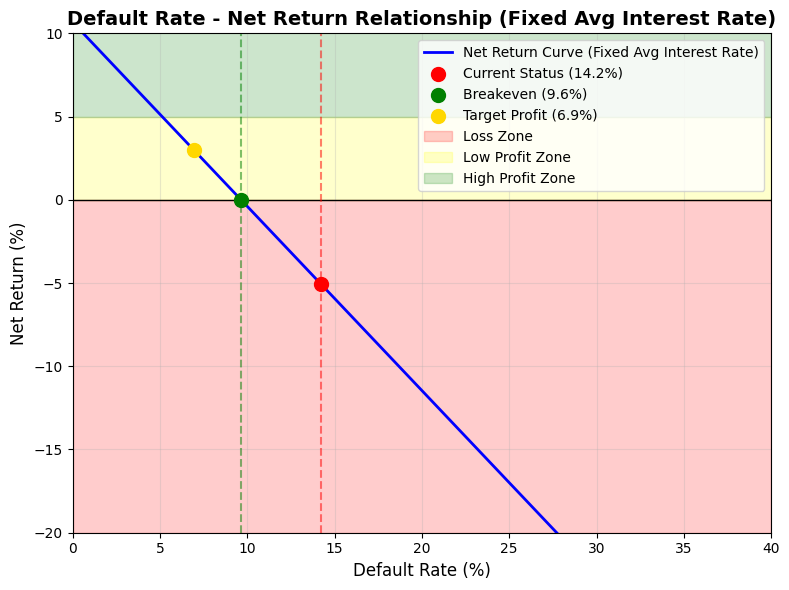

In [ ]:
# --- Default Rate - Net Return İlişkisi ---
# Başa baş default oranı (mevcut faiz oranı ile)
breakeven_default_rate = portfolio_avg_rate / (1 + portfolio_avg_rate/100) if portfolio_avg_rate > 0 else 0

# Hedef kar (%3) için gereken default oranı (mevcut faiz oranı ile)
target_profit = 3 # %3 kar hedefi
required_default_rate_for_profit = (portfolio_avg_rate - target_profit) / (1 + portfolio_avg_rate/100) if portfolio_avg_rate > target_profit else 0


plt.figure(figsize=(8, 6))
ax = plt.gca()

# Default rate aralığı (0'dan %40'a kadar)
default_rates_scenario = np.linspace(0, 40, 100)

# Net getiri hesaplama (mevcut ortalama faiz oranı sabit tutularak)
net_return_scenario = portfolio_avg_rate * (1 - default_rates_scenario/100) - default_rates_scenario

ax.plot(default_rates_scenario, net_return_scenario, 'b-', linewidth=2, label='Net Return Curve (Fixed Avg Interest Rate)')

# Kritik noktaları işaretle
ax.scatter(portfolio_default_rate,
           portfolio_avg_rate * (1 - portfolio_default_rate/100) - portfolio_default_rate,
           color='red', s=100, zorder=5, label=f'Current Status ({portfolio_default_rate:.1f}%)')

ax.scatter(breakeven_default_rate, 0, color='green', s=100, zorder=5,
           label=f'Breakeven ({breakeven_default_rate:.1f}%)')

# Hedef kar için gereken default oranı
if required_default_rate_for_profit > 0 and required_default_rate_for_profit <= 40: # Plotting range within 0-40
     ax.scatter(required_default_rate_for_profit, target_profit, color='gold', s=100, zorder=5,
                label=f'Target Profit ({required_default_rate_for_profit:.1f}%)')


# Bölgeleri renklendir
ax.axhspan(-20, 0, alpha=0.2, color='red', label='Loss Zone')
ax.axhspan(0, 5, alpha=0.2, color='yellow', label='Low Profit Zone')
ax.axhspan(5, 20, alpha=0.2, color='green', label='High Profit Zone')

# Referans çizgileri
ax.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax.axvline(x=portfolio_default_rate, color='red', linestyle='--', alpha=0.5)
ax.axvline(x=breakeven_default_rate, color='green', linestyle='--', alpha=0.5)

ax.set_xlabel('Default Rate (%)', fontsize=12)
ax.set_ylabel('Net Return (%)', fontsize=12)
ax.set_title('Default Rate - Net Return Relationship (Fixed Avg Interest Rate)', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right')
ax.set_xlim(0, 40) # Default rate from 0% to 40%
ax.set_ylim(-20, 10) # Net return from -20% to 10%

plt.tight_layout()
plt.show()

In [ ]:
# Default Rate - Net Return Comparison Table
# Grafikten okunan key değerler için tablo oluştur

# Tablo için seçili default rate değerleri (grafikten)
selected_default_rates = [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 25, 30, 35, 40]

# Net return hesaplama (grafikte kullanılan formül)
table_results = []
for dr in selected_default_rates:
    net_return = portfolio_avg_rate * (1 - dr/100) - dr

    # Status belirleme
    if net_return > 5:
        status = "High Profit"
        color = "🟢"
    elif net_return > 0:
        status = "Low Profit"
        color = "🟡"
    else:
        status = "Loss"
        color = "🔴"

    table_results.append({
        'Default_Rate_Pct': dr,
        'Net_Return_Pct': round(net_return, 2),
        'Status': status,
        'Zone': color
    })

# DataFrame oluştur
df_table = pd.DataFrame(table_results)

# Tabloyu yazdır
print("="*60)
print("DEFAULT RATE - NET RETURN COMPARISON TABLE")
print("="*60)
print(f"{'Default Rate (%)':<15} {'Net Return (%)':<15} {'Status':<12} {'Zone':<6}")
print("-"*60)

for idx, row in df_table.iterrows():
    print(f"{row['Default_Rate_Pct']:<15} {row['Net_Return_Pct']:<15} {row['Status']:<12} {row['Zone']:<6}")

print("-"*60)
print(f"Current Portfolio: {portfolio_default_rate:.1f}% default rate = {portfolio_avg_rate * (1 - portfolio_default_rate/100) - portfolio_default_rate:.2f}% net return")
print(f"Breakeven Point: {breakeven_default_rate:.1f}% default rate = 0.00% net return")
if required_default_rate_for_profit > 0:
    print(f"Target Profit Point: {required_default_rate_for_profit:.1f}% default rate = {target_profit:.2f}% net return")
print("="*60)

# Bonus: Critical points tablosu
critical_points = pd.DataFrame({
    'Milestone': ['Target Profit (3%)', 'Breakeven (0%)', 'Current Status', 'High Risk (20%)', 'Extreme Risk (30%)'],
    'Default_Rate': [f"{required_default_rate_for_profit:.1f}%", f"{breakeven_default_rate:.1f}%",
                     f"{portfolio_default_rate:.1f}%", "20.0%", "30.0%"],
    'Net_Return': [f"{target_profit:.1f}%", "0.0%",
                   f"{portfolio_avg_rate * (1 - portfolio_default_rate/100) - portfolio_default_rate:.1f}%",
                   f"{portfolio_avg_rate * 0.8 - 20:.1f}%", f"{portfolio_avg_rate * 0.7 - 30:.1f}%"]
})

print("\nCRITICAL MILESTONES:")
print(critical_points.to_string(index=False))

DEFAULT RATE - NET RETURN COMPARISON TABLE
Default Rate (%) Net Return (%)  Status       Zone  
------------------------------------------------------------
0               10.68           High Profit  🟢     
2               8.46            High Profit  🟢     
4               6.25            High Profit  🟢     
6               4.04            Low Profit   🟡     
8               1.82            Low Profit   🟡     
10              -0.39           Loss         🔴     
12              -2.6            Loss         🔴     
14              -4.82           Loss         🔴     
16              -7.03           Loss         🔴     
18              -9.24           Loss         🔴     
20              -11.46          Loss         🔴     
25              -16.99          Loss         🔴     
30              -22.53          Loss         🔴     
35              -28.06          Loss         🔴     
40              -33.59          Loss         🔴     
------------------------------------------------------------
Cu

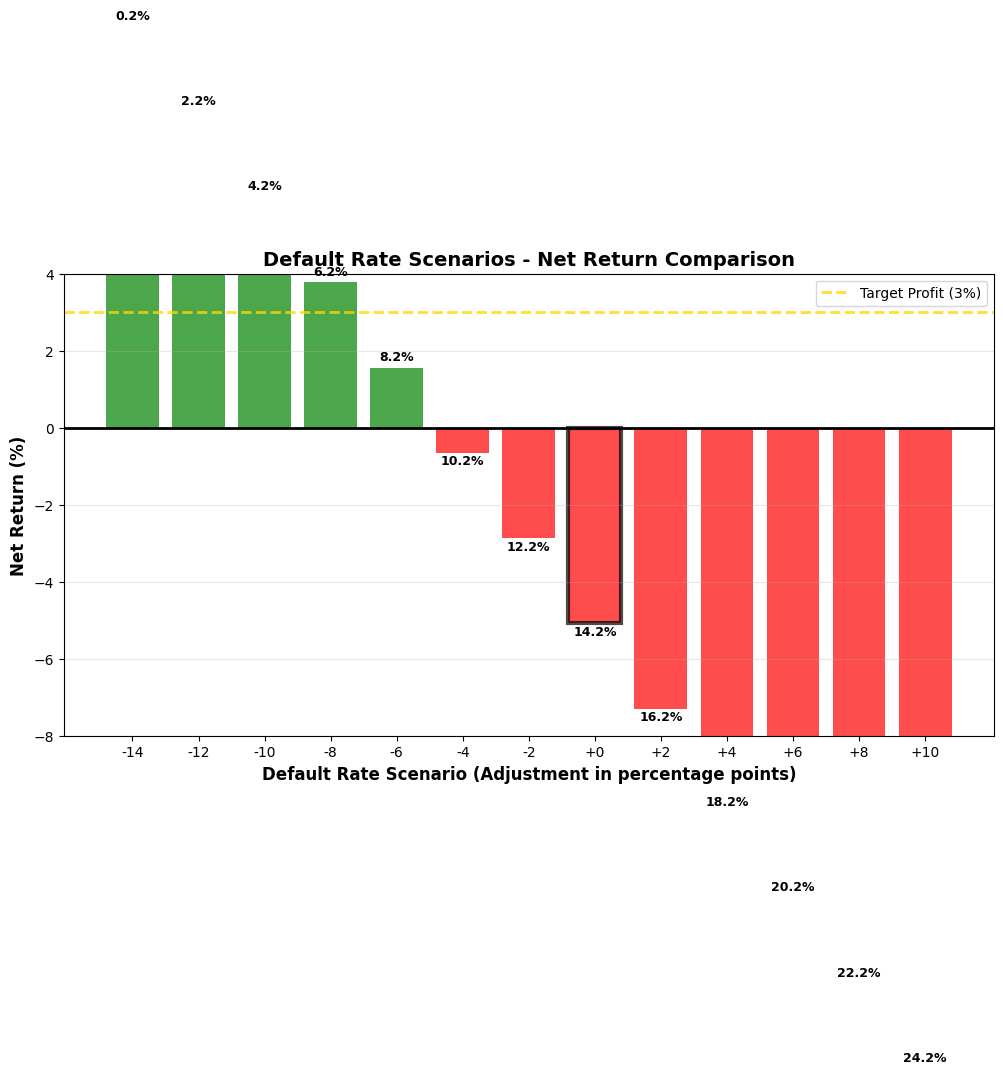

In [ ]:
# Default Rate Scenarios - Net Return Comparison (bar chart format)
# Interest Rate grafiği gibi format

# Default rate scenarios - current'tan iyileştirme odaklı
default_rate_adjustments = np.arange(-14, 11, 2)  # -14'ten +10'a, 2'şer artışla

# Senaryoları hesapla
results_dr_scenarios = []
for adj in default_rate_adjustments:
    new_default_rate = portfolio_default_rate + adj
    # Negatif default rate'i sıfıra sınırla
    new_default_rate = max(0, new_default_rate)

    net_return = portfolio_avg_rate * (1 - new_default_rate/100) - new_default_rate
    results_dr_scenarios.append({
        'Scenario_Adjustment': adj,
        'New_Default_Rate': new_default_rate,
        'Net_Return': net_return
    })

df_dr_scenarios = pd.DataFrame(results_dr_scenarios)

# Grafik oluştur - Interest Rate grafiği stili
fig, ax = plt.subplots(figsize=(12, 6))

# Renk belirleme - pozitif return yeşil, negatif kırmızı
colors = ['green' if x > 0 else 'red' for x in df_dr_scenarios['Net_Return']]
bars = ax.bar(range(len(df_dr_scenarios)), df_dr_scenarios['Net_Return'],
              color=colors, alpha=0.7)

# Çubukların üzerine default rate değerlerini yaz
for i, (dr, ret) in enumerate(zip(df_dr_scenarios['New_Default_Rate'], df_dr_scenarios['Net_Return'])):
    ax.text(i, ret + (0.2 if ret > 0 else -0.3), f'{dr:.1f}%',
            ha='center', fontsize=9, fontweight='bold')

# Reference lines
ax.axhline(y=0, color='black', linestyle='-', linewidth=2)
ax.axhline(y=target_profit, color='gold', linestyle='--', linewidth=2,
           alpha=0.8, label=f'Target Profit ({target_profit}%)')

# Y-axis limit - pozitif return'leri vurgulamak için
ax.set_ylim(-8, 4)

# Eksen ve başlık ayarları
ax.set_xlabel('Default Rate Scenario (Adjustment in percentage points)', fontsize=12, fontweight='bold')
ax.set_ylabel('Net Return (%)', fontsize=12, fontweight='bold')
ax.set_title('Default Rate Scenarios - Net Return Comparison',
             fontsize=14, fontweight='bold')

ax.grid(True, alpha=0.3, axis='y')
ax.legend()

# X ekseni etiketleri
labels = [f'{adj:+d}' for adj in default_rate_adjustments]
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, fontsize=10)

# Current position indicator
current_idx = list(default_rate_adjustments).index(0) if 0 in default_rate_adjustments else None
if current_idx is not None:
    bars[current_idx].set_edgecolor('black')
    bars[current_idx].set_linewidth(3)

plt.tight_layout()
plt.show()

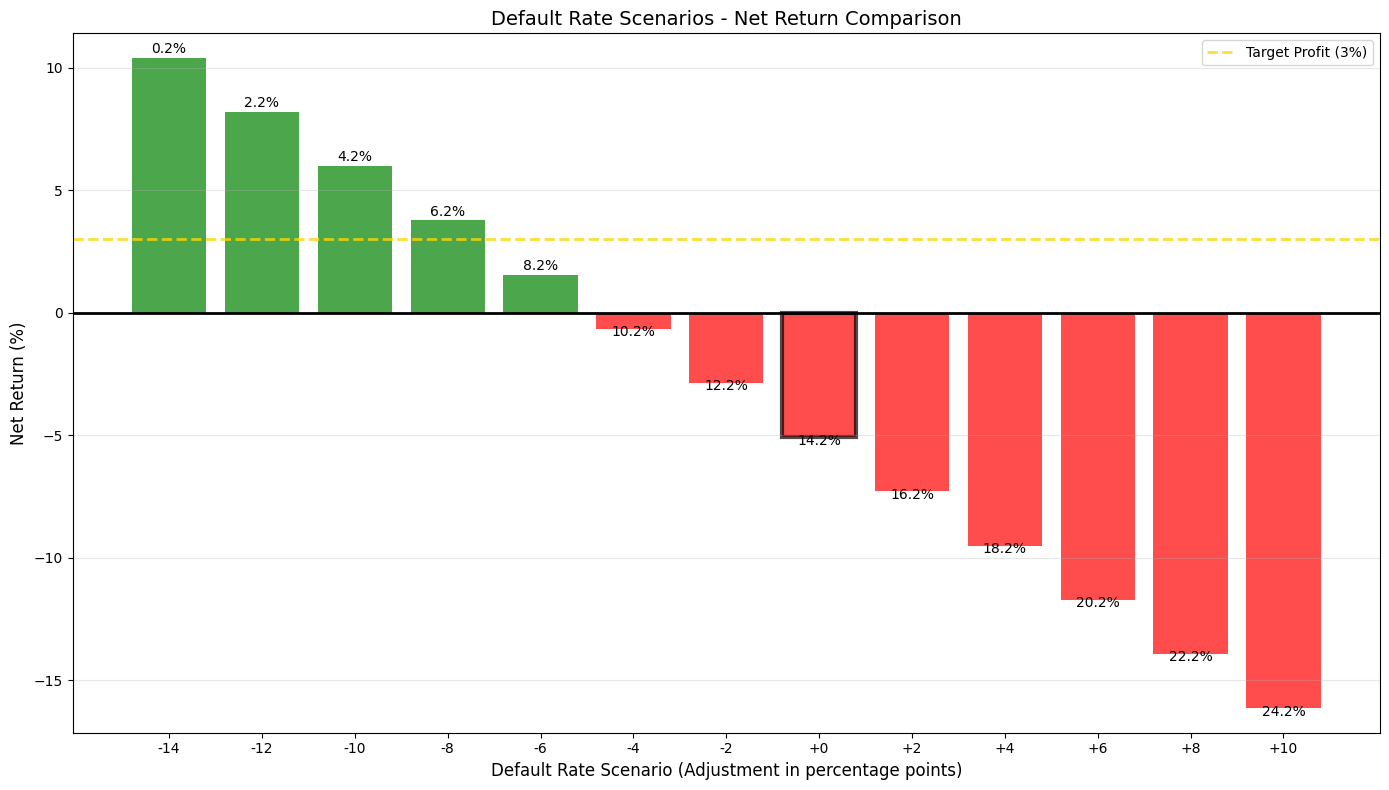

In [ ]:
# Default Rate Scenarios - Net Return Comparison (düzeltilmiş versiyon)
# Interest Rate grafiği gibi format

# Default rate scenarios - current'tan iyileştirme odaklı
default_rate_adjustments = np.arange(-14, 11, 2)  # -14'ten +10'a, 2'şer artışla

# Senaryoları hesapla
results_dr_scenarios = []
for adj in default_rate_adjustments:
    new_default_rate = portfolio_default_rate + adj
    # Negatif default rate'i sıfıra sınırla
    new_default_rate = max(0, new_default_rate)

    net_return = portfolio_avg_rate * (1 - new_default_rate/100) - new_default_rate
    results_dr_scenarios.append({
        'Scenario_Adjustment': adj,
        'New_Default_Rate': new_default_rate,
        'Net_Return': net_return
    })

df_dr_scenarios = pd.DataFrame(results_dr_scenarios)

# Grafik oluştur - düzeltilmiş boyutlar
fig, ax = plt.subplots(figsize=(14, 8))  # Daha geniş figure

# Renk belirleme - pozitif return yeşil, negatif kırmızı
colors = ['green' if x > 0 else 'red' for x in df_dr_scenarios['Net_Return']]
bars = ax.bar(range(len(df_dr_scenarios)), df_dr_scenarios['Net_Return'],
              color=colors, alpha=0.7, width=0.8)

# Çubukların üzerine default rate değerlerini yaz - normal font weight
for i, (dr, ret) in enumerate(zip(df_dr_scenarios['New_Default_Rate'], df_dr_scenarios['Net_Return'])):
    y_pos = ret + (0.2 if ret > 0 else -0.3)
    ax.text(i, y_pos, f'{dr:.1f}%', ha='center', fontsize=10)

# Reference lines
ax.axhline(y=0, color='black', linestyle='-', linewidth=2)
ax.axhline(y=target_profit, color='gold', linestyle='--', linewidth=2,
           alpha=0.8, label=f'Target Profit ({target_profit}%)')

# Y-axis limit - tüm barları gösterecek şekilde genişlet
y_min = min(df_dr_scenarios['Net_Return']) - 1
y_max = max(df_dr_scenarios['Net_Return']) + 1
ax.set_ylim(y_min, y_max)

# Eksen ve başlık ayarları - normal font weight
ax.set_xlabel('Default Rate Scenario (Adjustment in percentage points)', fontsize=12)
ax.set_ylabel('Net Return (%)', fontsize=12)
ax.set_title('Default Rate Scenarios - Net Return Comparison', fontsize=14)

ax.grid(True, alpha=0.3, axis='y')
ax.legend()

# X ekseni etiketleri
labels = [f'{adj:+d}' for adj in default_rate_adjustments]
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, fontsize=10)

# Current position indicator (0 adjustment varsa)
current_idx = list(default_rate_adjustments).index(0) if 0 in default_rate_adjustments else None
if current_idx is not None:
    bars[current_idx].set_edgecolor('black')
    bars[current_idx].set_linewidth(3)

# Margins ayarla - barların kesilmemesi için
plt.subplots_adjust(left=0.08, right=0.95, top=0.92, bottom=0.12)
plt.tight_layout()
plt.show()

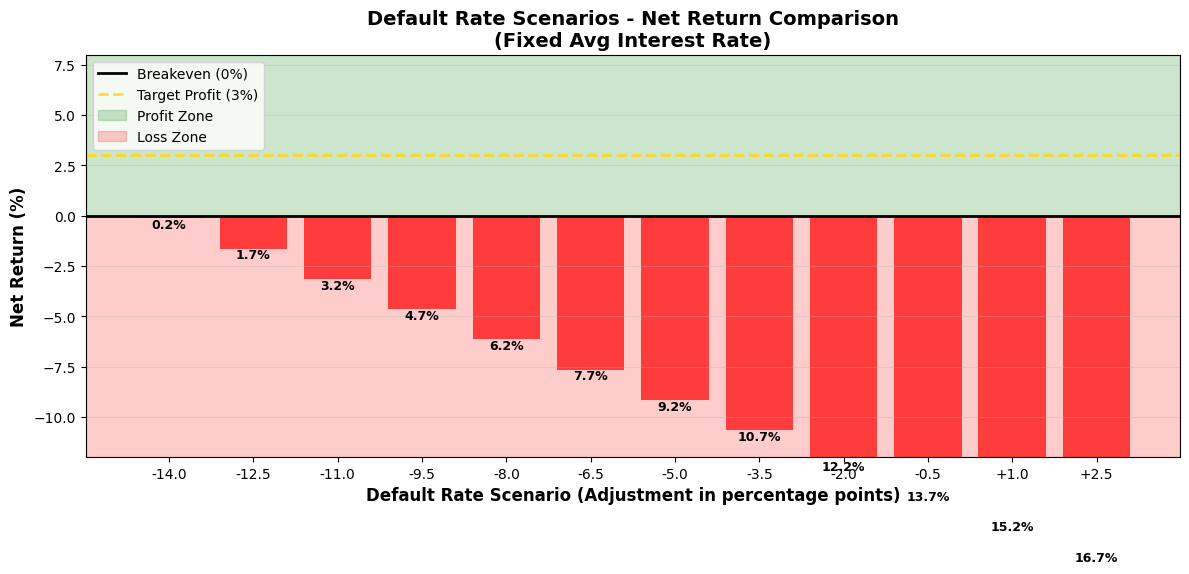

In [ ]:
# Default rate scenarios - pozitif return'leri görmek için sol tarafa odaklan
default_rate_scenarios = np.arange(-14, 3, 1.5)  # -14'ten +2'ye, 1.5'ar artışla (12 değer)

# Senaryoları hesapla
results_default_scenarios = []
for adj in default_rate_scenarios:
    new_default_rate = current_default_rate + (adj / 100)
    # Negatif default rate'i sıfıra sınırla
    new_default_rate = max(0, new_default_rate)

    net_return = avg_interest_rate * (1 - new_default_rate) - new_default_rate * 100
    results_default_scenarios.append({
        'Default_Rate': new_default_rate * 100,
        'Scenario_Adjustment': adj,
        'Net_Getiri': net_return
    })

df_results_scenarios = pd.DataFrame(results_default_scenarios)

# Grafik oluştur - Interest rate grafiğine benzer stil
fig, ax = plt.subplots(figsize=(12, 6))

colors = ['green' if x > 0 else 'red' for x in df_results_scenarios['Net_Getiri']]
bars = ax.bar(range(len(df_results_scenarios)), df_results_scenarios['Net_Getiri'],
              color=colors, alpha=0.7)

# Çubukların üzerine default oranlarını yaz
for i, (rate, ret) in enumerate(zip(df_results_scenarios['Default_Rate'], df_results_scenarios['Net_Getiri'])):
    ax.text(i, ret + (0.3 if ret > 0 else -0.5), f'{rate:.1f}%',
            ha='center', fontsize=9, fontweight='bold')

# Reference lines
ax.axhline(y=0, color='black', linestyle='-', linewidth=2, label='Breakeven (0%)')
ax.axhline(y=3, color='gold', linestyle='--', linewidth=2, alpha=0.8, label='Target Profit (3%)')

# Y-axis limitini pozitif return'leri daha çok gösterecek şekilde ayarla
ax.set_ylim(-12, 8)

# Background color zones (Interest rate grafiği gibi)
ax.axhspan(0, 8, alpha=0.2, color='green', label='Profit Zone')
ax.axhspan(-12, 0, alpha=0.2, color='red', label='Loss Zone')

# Eksen ve başlık ayarları
ax.set_xlabel('Default Rate Scenario (Adjustment in percentage points)', fontsize=12, fontweight='bold')
ax.set_ylabel('Net Return (%)', fontsize=12, fontweight='bold')
ax.set_title('Default Rate Scenarios - Net Return Comparison\n(Fixed Avg Interest Rate)',
             fontsize=14, fontweight='bold')

ax.grid(True, alpha=0.3, axis='y')
ax.legend(loc='upper left')

# X ekseni etiketleri
labels = [f'{adj:+.1f}' for adj in default_rate_scenarios]
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, fontsize=10)

plt.tight_layout()
plt.show()


GENERATING VISUALIZATIONS...


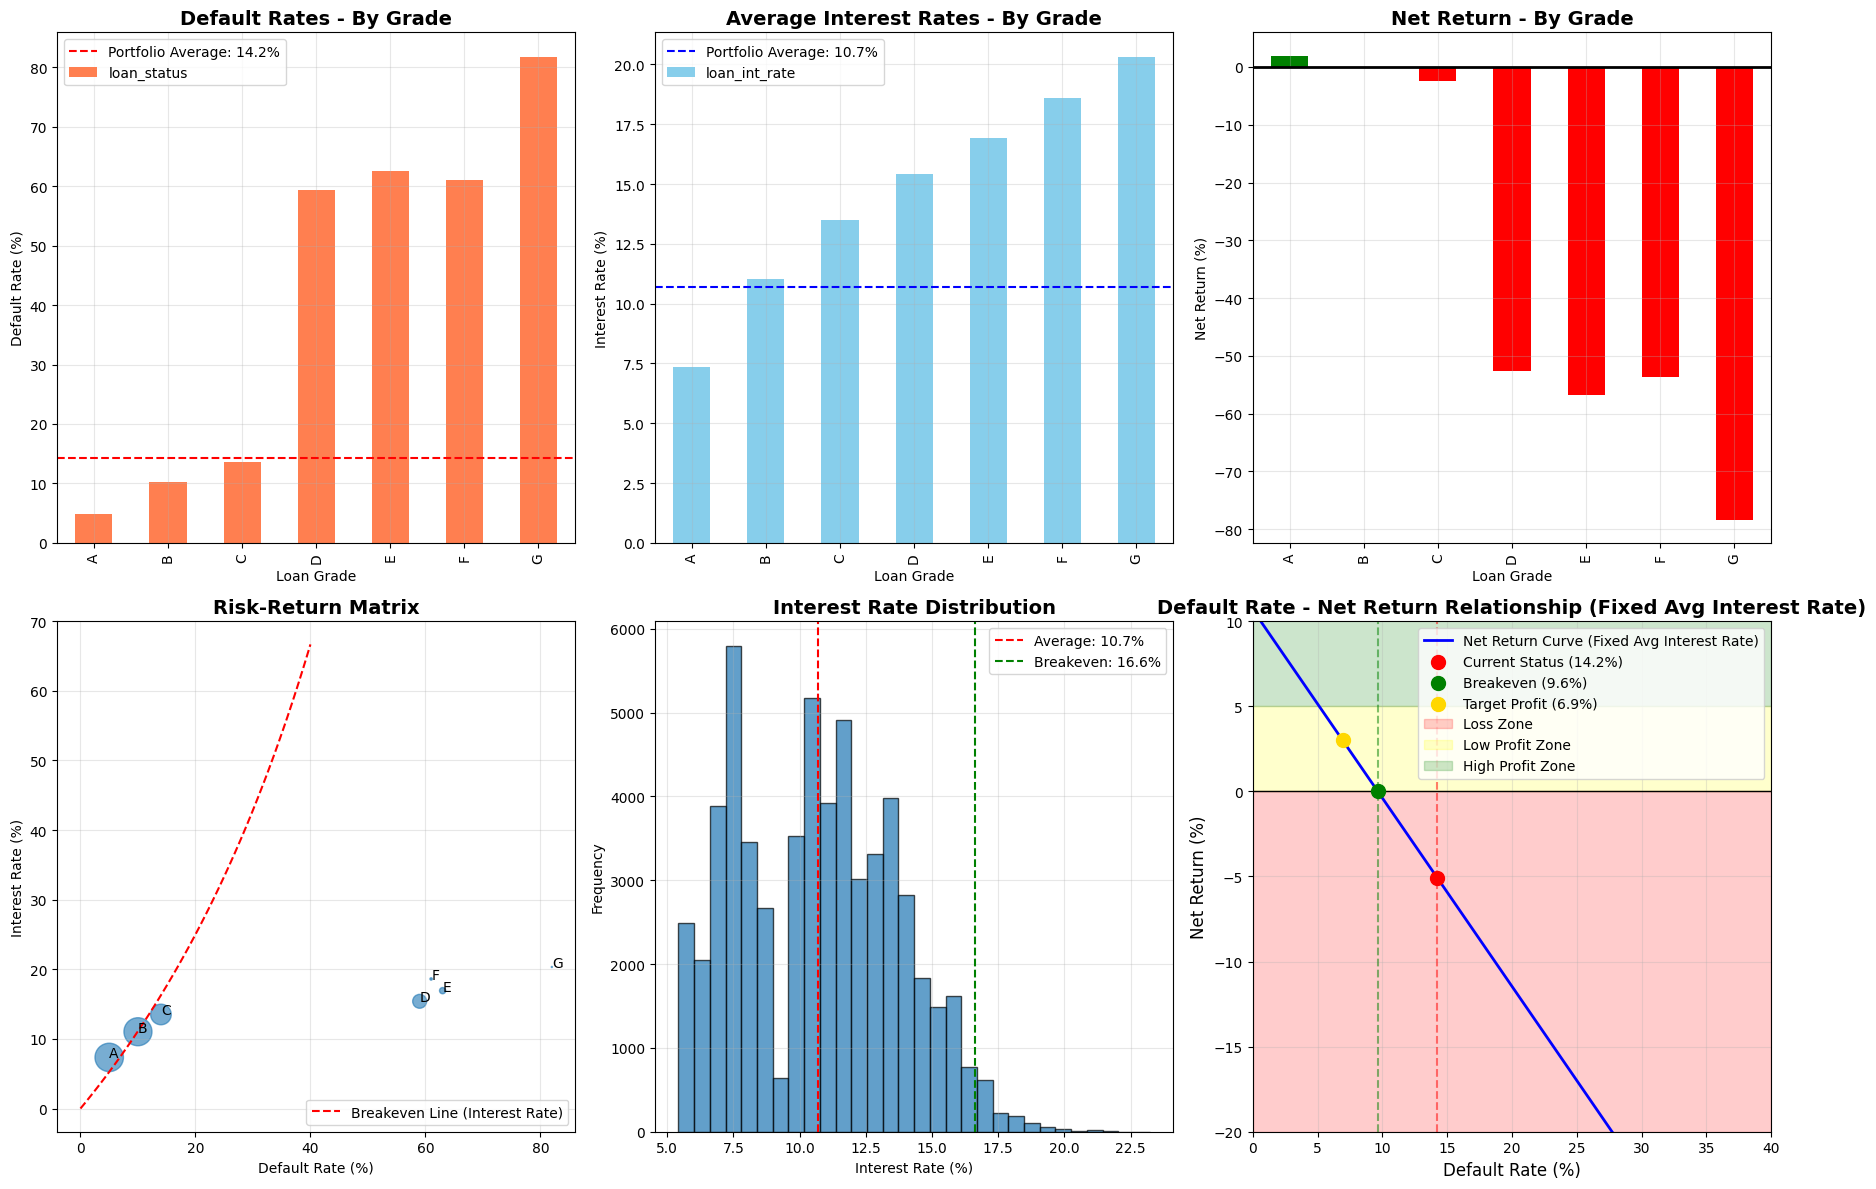


SCENARIO ANALYSIS: IMPACT OF DEFAULT RATE CHANGES (Fixed Avg Interest Rate)

💡 Breakeven Default Rate (with 10.68% avg rate): %9.65
📊 Current Default Rate: %14.24
⚠️ Difference: You need to decrease default rate by %4.59 percentage points to break even!

💰 Target Profit (3%) Required Default Rate (with 10.68% avg rate): %6.94

📊 Net Return at Different Default Rate Levels (Fixed Avg Interest Rate):
--------------------------------------------------------------------------------
Default Rate | Net Return | Status          | Explanation
--------------------------------------------------------------------------------
%        0.00 | %   10.68  | 💚 High Profit     | Excellent return
%        4.24 | %    5.99  | 💚 High Profit     | Excellent return
%        9.24 | %    0.45  | ✅ Low Profit      | 📍 BREAKEVEN POINT!
%       12.24 | %   -2.87  | ❌ Losing Money    | Losses continue
%       14.24 | %   -5.08  | ❌ Significant Loss | Critical situation!
%       16.24 | %   -7.29  | ❌ Significant

In [ ]:
# ============================================
# BÖLÜM 7: GÖRSELLEŞTIRMELER (Default Rate Analizi Eklendi)
# ============================================

print("\n" + "="*80)
print("GENERATING VISUALIZATIONS...")
print("="*80)

# Grade bazlı analiz (mevcut)
grade_analysis = df.groupby('loan_grade').agg({
    'loan_status': ['count', 'mean'],
    'loan_int_rate': 'mean',
    'loan_amnt': 'mean'
}).round(2)

grade_analysis.columns = ['Kredi_Sayısı', 'Default_Oranı', 'Ort_Faiz', 'Ort_Kredi']
grade_analysis['Default_Oranı'] = grade_analysis['Default_Oranı'] * 100

grade_analysis['Net_Getiri'] = (
    grade_analysis['Ort_Faiz'] * (1 - grade_analysis['Default_Oranı']/100) -
    grade_analysis['Default_Oranı'] # Assuming LGD is 100%
)

grade_analysis['Durum'] = grade_analysis['Net_Getiri'].apply(
    lambda x: '✅ PROFITABLE' if x > 0 else '❌ LOSING MONEY'
)

# --- Yeni Grafik: Default Rate - Net Return İlişkisi ---
# Başa baş default oranı (mevcut faiz oranı ile)
breakeven_default_rate = portfolio_avg_rate / (1 + portfolio_avg_rate/100) if portfolio_avg_rate > 0 else 0

# Hedef kar (%3) için gereken default oranı (mevcut faiz oranı ile)
# Net Return = Avg_Rate * (1 - Default_Rate/100) - Default_Rate
# target_profit = Avg_Rate - Avg_Rate * Default_Rate/100 - Default_Rate
# target_profit - Avg_Rate = - Default_Rate * (Avg_Rate/100 + 1)
# Default_Rate = (Avg_Rate - target_profit) / (1 + Avg_Rate/100)
target_profit = 3 # %3 kar hedefi
required_default_rate_for_profit = (portfolio_avg_rate - target_profit) / (1 + portfolio_avg_rate/100) if portfolio_avg_rate > target_profit else 0


fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Grafik 1: Grade bazlı default oranları (mevcut)
ax1 = axes[0, 0]
grade_defaults = df.groupby('loan_grade')['loan_status'].mean() * 100
grade_defaults.plot(kind='bar', ax=ax1, color='coral')
ax1.set_title('Default Rates - By Grade', fontsize=14, fontweight='bold')
ax1.set_xlabel('Loan Grade')
ax1.set_ylabel('Default Rate (%)')
ax1.axhline(y=default_rate, color='red', linestyle='--', label=f'Portfolio Average: {default_rate:.1f}%')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Grafik 2: Grade bazlı faiz oranları (mevcut)
ax2 = axes[0, 1]
grade_interest = df.groupby('loan_grade')['loan_int_rate'].mean()
grade_interest.plot(kind='bar', ax=ax2, color='skyblue')
ax2.set_title('Average Interest Rates - By Grade', fontsize=14, fontweight='bold')
ax2.set_xlabel('Loan Grade')
ax2.set_ylabel('Interest Rate (%)')
ax2.axhline(y=portfolio_avg_rate, color='blue', linestyle='--', label=f'Portfolio Average: {portfolio_avg_rate:.1f}%')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Grafik 3: Net Getiri - Grade Bazlı (mevcut)
ax3 = axes[0, 2]
net_returns = grade_analysis['Net_Getiri']
colors = ['green' if x > 0 else 'red' for x in net_returns]
net_returns.plot(kind='bar', ax=ax3, color=colors)
ax3.set_title('Net Return - By Grade', fontsize=14, fontweight='bold')
ax3.set_xlabel('Loan Grade')
ax3.set_ylabel('Net Return (%)')
ax3.axhline(y=0, color='black', linestyle='-', linewidth=2)
ax3.grid(True, alpha=0.3)

# Grafik 4: Risk-Return Scatter (mevcut)
ax4 = axes[1, 0]
ax4.scatter(grade_analysis['Default_Oranı'], grade_analysis['Ort_Faiz'],
           s=grade_analysis['Kredi_Sayısı']/50, alpha=0.6)
for idx, row in grade_analysis.iterrows():
    ax4.annotate(idx, (row['Default_Oranı'], row['Ort_Faiz']))
ax4.set_title('Risk-Return Matrix', fontsize=14, fontweight='bold')
ax4.set_xlabel('Default Rate (%)')
ax4.set_ylabel('Interest Rate (%)')
x_range = np.linspace(0, 40, 100)
y_breakeven = x_range / (1 - x_range/100)
ax4.plot(x_range, y_breakeven, 'r--', label='Breakeven Line (Interest Rate)')
ax4.legend()
ax4.grid(True, alpha=0.3)

# Grafik 5: Faiz Dağılımı (mevcut)
ax5 = axes[1, 1]
ax5.hist(df['loan_int_rate'], bins=30, edgecolor='black', alpha=0.7)
ax5.axvline(portfolio_avg_rate, color='red', linestyle='--', label=f'Average: {portfolio_avg_rate:.1f}%')
ax5.axvline(breakeven_rate, color='green', linestyle='--', label=f'Breakeven: {breakeven_rate:.1f}%')
ax5.set_title('Interest Rate Distribution', fontsize=14, fontweight='bold')
ax5.set_xlabel('Interest Rate (%)')
ax5.set_ylabel('Frequency')
ax5.legend()
ax5.grid(True, alpha=0.3)

# Grafik 6 (Yeni): Default Rate - Net Return İlişkisi
ax6 = axes[1, 2]

# Default rate aralığı (0'dan %40'a kadar)
default_rates_scenario = np.linspace(0, 40, 100)

# Net getiri hesaplama (mevcut ortalama faiz oranı sabit tutularak)
net_return_scenario = portfolio_avg_rate * (1 - default_rates_scenario/100) - default_rates_scenario

ax6.plot(default_rates_scenario, net_return_scenario, 'b-', linewidth=2, label='Net Return Curve (Fixed Avg Interest Rate)')

# Kritik noktaları işaretle
ax6.scatter(portfolio_default_rate,
           portfolio_avg_rate * (1 - portfolio_default_rate/100) - portfolio_default_rate,
           color='red', s=100, zorder=5, label=f'Current Status ({portfolio_default_rate:.1f}%)')

ax6.scatter(breakeven_default_rate, 0, color='green', s=100, zorder=5,
           label=f'Breakeven ({breakeven_default_rate:.1f}%)')

# Hedef kar için gereken default oranı
if required_default_rate_for_profit > 0 and required_default_rate_for_profit <= 40: # Plotting range within 0-40
     ax6.scatter(required_default_rate_for_profit, target_profit, color='gold', s=100, zorder=5,
                label=f'Target Profit ({required_default_rate_for_profit:.1f}%)')


# Bölgeleri renklendir
ax6.axhspan(-20, 0, alpha=0.2, color='red', label='Loss Zone')
ax6.axhspan(0, 5, alpha=0.2, color='yellow', label='Low Profit Zone')
ax6.axhspan(5, 20, alpha=0.2, color='green', label='High Profit Zone')

# Referans çizgileri
ax6.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax6.axvline(x=portfolio_default_rate, color='red', linestyle='--', alpha=0.5)
ax6.axvline(x=breakeven_default_rate, color='green', linestyle='--', alpha=0.5)

ax6.set_xlabel('Default Rate (%)', fontsize=12)
ax6.set_ylabel('Net Return (%)', fontsize=12)
ax6.set_title('Default Rate - Net Return Relationship (Fixed Avg Interest Rate)', fontsize=14, fontweight='bold')
ax6.grid(True, alpha=0.3)
ax6.legend(loc='upper right')
ax6.set_xlim(0, 40) # Default rate from 0% to 40%
ax6.set_ylim(-20, 10) # Net return from -20% to 10%

plt.tight_layout()
plt.show()

# --- Yeni Senaryo Analizi: Default Rate Değişiminin Etkisi ---
print("\n" + "="*80)
print("SCENARIO ANALYSIS: IMPACT OF DEFAULT RATE CHANGES (Fixed Avg Interest Rate)")
print("="*80)

print(f"\n💡 Breakeven Default Rate (with {portfolio_avg_rate:.2f}% avg rate): %{breakeven_default_rate:.2f}")
print(f"📊 Current Default Rate: %{portfolio_default_rate:.2f}")
if portfolio_default_rate > breakeven_default_rate:
    print(f"⚠️ Difference: You need to decrease default rate by %{portfolio_default_rate - breakeven_default_rate:.2f} percentage points to break even!")
else:
     print(f"✅ Difference: Default rate is below breakeven by %{breakeven_default_rate - portfolio_default_rate:.2f} percentage points.")

print(f"\n💰 Target Profit ({target_profit:.0f}%) Required Default Rate (with {portfolio_avg_rate:.2f}% avg rate): %{required_default_rate_for_profit:.2f}\n")


print("📊 Net Return at Different Default Rate Levels (Fixed Avg Interest Rate):")
print("-" * 80)
print("Default Rate | Net Return | Status          | Explanation")
print("-" * 80)

# Farklı default oranları senaryoları
default_rate_adjustments_pct = [-5, -2, 0, 2, 5, 10, 15, 20] # Adjusted as percentage points
results_default = []

for adjustment_pct in default_rate_adjustments_pct:
    new_default_rate = portfolio_default_rate + adjustment_pct
    if new_default_rate < 0: new_default_rate = 0 # Default rate cannot be negative
    if new_default_rate > 100: new_default_rate = 100 # Default rate cannot exceed 100%

    new_net_return = portfolio_avg_rate * (1 - new_default_rate/100) - new_default_rate

    # Durum belirleme
    if new_net_return < -5:
        status = "❌ Significant Loss"
        explanation = "Critical situation!"
    elif new_net_return < -2:
        status = "❌ Losing Money"
        explanation = "Losses continue"
    elif new_net_return < 0:
        status = "⚠️ Slight Loss"
        explanation = "Near breakeven"
    elif new_net_return < 2:
        status = "✅ Low Profit"
        explanation = "Above breakeven"
    elif new_net_return < 5:
        status = "✅ Good Profit"
        explanation = "Healthy return"
    else:
        status = "💚 High Profit"
        explanation = "Excellent return"

    # Başa baş noktasına yakınlık kontrolü
    if abs(new_default_rate - breakeven_default_rate) < 0.5:
        explanation = "📍 BREAKEVEN POINT!"

    # Hedef kar noktasına yakınlık kontrolü
    if abs(new_default_rate - required_default_rate_for_profit) < 0.5:
        explanation = "🎯 TARGET PROFIT!"


    results_default.append({
        'Default_Rate': new_default_rate,
        'Net_Getiri': new_net_return,
        'Durum': status,
        'Açıklama': explanation
    })

    print(f"%{new_default_rate:12.2f} | %{new_net_return:8.2f}  | {status:17} | {explanation}")


# Başa baş noktasını ekstra göster
print("-" * 80)
print(f"%{breakeven_default_rate:12.2f} | %{0:8.2f}  | 🎯 BREAKEVEN      | Profit/Loss boundary")
print("-" * 80)

# Hedef kar için gereken default oranı
if required_default_rate_for_profit > 0:
    print(f"%{required_default_rate_for_profit:12.2f} | %{target_profit:8.2f}  | 🎯 TARGET PROFIT  | Healthy profitability")
    print("-" * 80)

print("="*80)

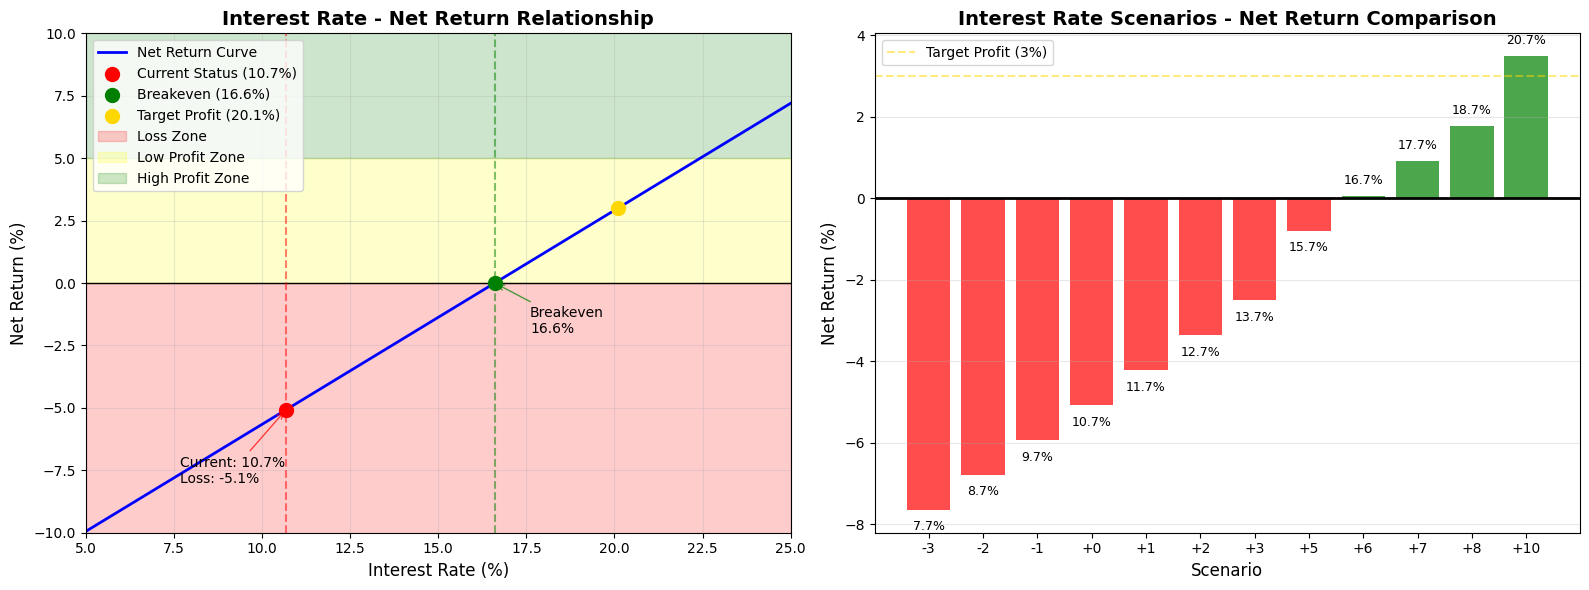

In [ ]:
# ============================================
# GRAFİK ÇİZİMİ
# ============================================

# Veri hazırlığı
# Re-create df_results from the scenario analysis
rate_adjustments = [-3, -2, -1, 0, 1, 2, 3, 5, 6, 7, 8, 10]
results = []
for rate_adjustment in rate_adjustments:
    new_rate = portfolio_avg_rate + rate_adjustment
    new_net_return = new_rate * (1 - portfolio_default_rate/100) - portfolio_default_rate
    # Simplified status for plotting
    if new_net_return < 0:
        status = "❌ LOSING MONEY"
    elif new_net_return < 2:
        status = "✅ Low Profit"
    elif new_net_return < 5:
        status = "✅ Good Profit"
    else:
        status = "💚 High Profit"

    results.append({
        'Faiz': new_rate,
        'Net_Getiri': new_net_return,
        'Durum': status
    })
df_results = pd.DataFrame(results)


# Daha detaylı veri noktaları için
detailed_rates = np.linspace(5, 25, 100)
detailed_returns = detailed_rates * (1 - portfolio_default_rate/100) - portfolio_default_rate

# Grafik oluşturma
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# ---- GRAFİK 1: FAİZ-NET GETİRİ EĞRİSİ ----
# ax1.plot(detailed_rates, detailed_returns, 'b-', linewidth=2, label='Net Getiri Eğrisi')
ax1.plot(detailed_rates, detailed_returns, 'b-', linewidth=2, label='Net Return Curve')


# Kritik noktaları işaretle
ax1.scatter(portfolio_avg_rate,
           portfolio_avg_rate * (1 - portfolio_default_rate/100) - portfolio_default_rate,
           color='red', s=100, zorder=5, label=f'Current Status ({portfolio_avg_rate:.1f}%)')

ax1.scatter(breakeven_rate, 0, color='green', s=100, zorder=5,
           label=f'Breakeven ({breakeven_rate:.1f}%)')

ax1.scatter(required_rate_for_profit, target_profit, color='gold', s=100, zorder=5,
           label=f'Target Profit ({required_rate_for_profit:.1f}%)')

# Bölgeleri renklendir
# ax1.axhspan(-20, 0, alpha=0.2, color='red', label='Zarar Bölgesi')
# ax1.axhspan(0, 5, alpha=0.2, color='yellow', label='Düşük Kar')
# ax1.axhspan(5, 20, alpha=0.2, color='green', label='Yüksek Kar')

ax1.axhspan(-20, 0, alpha=0.2, color='red', label='Loss Zone')
ax1.axhspan(0, 5, alpha=0.2, color='yellow', label='Low Profit Zone')
ax1.axhspan(5, 20, alpha=0.2, color='green', label='High Profit Zone')


# Referans çizgileri
ax1.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax1.axvline(x=portfolio_avg_rate, color='red', linestyle='--', alpha=0.5)
ax1.axvline(x=breakeven_rate, color='green', linestyle='--', alpha=0.5)

# Eksen ve başlık ayarları
# ax1.set_xlabel('Faiz Oranı (%)', fontsize=12)
# ax1.set_ylabel('Net Getiri (%)', fontsize=12)
# ax1.set_title('Faiz Oranı - Net Getiri İlişkisi', fontsize=14, fontweight='bold')

ax1.set_xlabel('Interest Rate (%)', fontsize=12)
ax1.set_ylabel('Net Return (%)', fontsize=12)
ax1.set_title('Interest Rate - Net Return Relationship', fontsize=14, fontweight='bold')

ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper left')
ax1.set_xlim(5, 25)
ax1.set_ylim(-10, 10)

# Mevcut durumu ve hedefi metin olarak göster
# ax1.annotate(f'Mevcut: {portfolio_avg_rate:.1f}%\nZarar: {portfolio_avg_rate * (1 - portfolio_default_rate/100) - portfolio_default_rate:.1f}%',
#             xy=(portfolio_avg_rate, portfolio_avg_rate * (1 - portfolio_default_rate/100) - portfolio_default_rate),
#             xytext=(portfolio_avg_rate-3, -8),
#             arrowprops=dict(arrowstyle='->', color='red', alpha=0.7))

ax1.annotate(f'Current: {portfolio_avg_rate:.1f}%\nLoss: {portfolio_avg_rate * (1 - portfolio_default_rate/100) - portfolio_default_rate:.1f}%',
            xy=(portfolio_avg_rate, portfolio_avg_rate * (1 - portfolio_default_rate/100) - portfolio_default_rate),
            xytext=(portfolio_avg_rate-3, -8),
            arrowprops=dict(arrowstyle='->', color='red', alpha=0.7))


# ax1.annotate(f'Başa Baş\n{breakeven_rate:.1f}%',
#             xy=(breakeven_rate, 0),
#             xytext=(breakeven_rate+1, -2),
#             arrowprops=dict(arrowstyle='->', color='green', alpha=0.7))

ax1.annotate(f'Breakeven\n{breakeven_rate:.1f}%',
            xy=(breakeven_rate, 0),
            xytext=(breakeven_rate+1, -2),
            arrowprops=dict(arrowstyle='->', color='green', alpha=0.7))


# ---- GRAFİK 2: SENARYO ANALİZİ ÇUBUK GRAFİĞİ ----
colors = ['red' if x < 0 else 'green' for x in df_results['Net_Getiri']]
bars = ax2.bar(range(len(df_results)), df_results['Net_Getiri'], color=colors, alpha=0.7)

# Çubukların üzerine faiz oranlarını yaz
for i, (rate, ret) in enumerate(zip(df_results['Faiz'], df_results['Net_Getiri'])):
    ax2.text(i, ret + (0.3 if ret > 0 else -0.5), f'{rate:.1f}%',
            ha='center', fontsize=9)

# Başa baş çizgisi
ax2.axhline(y=0, color='black', linestyle='-', linewidth=2)
# ax2.axhline(y=3, color='gold', linestyle='--', alpha=0.5, label='Hedef Kar (%3)')
ax2.axhline(y=3, color='gold', linestyle='--', alpha=0.5, label='Target Profit (3%)')


# Eksen ve başlık ayarları
# ax2.set_xlabel('Senaryo', fontsize=12)
# ax2.set_ylabel('Net Getiri (%)', fontsize=12)
# ax2.set_title('Faiz Senaryoları - Net Getiri Karşılaştırması', fontsize=14, fontweight='bold')
ax2.set_xlabel('Scenario', fontsize=12)
ax2.set_ylabel('Net Return (%)', fontsize=12)
ax2.set_title('Interest Rate Scenarios - Net Return Comparison', fontsize=14, fontweight='bold')


ax2.grid(True, alpha=0.3, axis='y')
ax2.legend()

# X ekseni etiketleri
labels = [f'+{adj}' if adj >= 0 else f'{adj}' for adj in rate_adjustments]
ax2.set_xticks(range(len(labels)))
ax2.set_xticklabels(labels)

plt.tight_layout()
plt.show()

LGD Loss Given Default %100 olarak kabul edilmiştir.

In [ ]:
df.head()

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status
0,0,37,35000,RENT,0,EDUCATION,B,6000,11.490,0.170,N,14,0
1,1,22,56000,OWN,6,MEDICAL,C,4000,13.350,0.070,N,2,0
2,2,29,28800,OWN,8,PERSONAL,A,6000,8.900,0.210,N,10,0
3,3,30,70000,RENT,14,VENTURE,B,12000,11.110,0.170,N,5,0
4,4,22,60000,RENT,2,MEDICAL,A,6000,6.920,0.100,N,3,0


In [ ]:
# ============================================
# ÖZET ANALİZ
# ============================================

print("\n" + "="*80)
print("📊 ANALİZ ÖZETİ")
print("="*80)

current_loss = portfolio_avg_rate * (1 - portfolio_default_rate/100) - portfolio_default_rate

print(f"""
💼 MEVCUT DURUM:
   • Faiz Oranı: %{portfolio_avg_rate:.2f}
   • Default Oranı: %{portfolio_default_rate:.2f}
   • Net Getiri: %{current_loss:.2f} (ZARAR!)

🎯 BAŞA BAŞ İÇİN:
   • Gereken Faiz: %{breakeven_rate:.2f}
   • Artırılması Gereken: %{breakeven_rate - portfolio_avg_rate:.2f}

💰 %3 KAR İÇİN:
   • Gereken Faiz: %{required_rate_for_profit:.2f}
   • Artırılması Gereken: %{required_rate_for_profit - portfolio_avg_rate:.2f}

📈 TAVSİYE:
   • Kısa Vade: Faizleri minimum %{breakeven_rate:.0f}'ye çıkarın
   • Orta Vade: Default oranını %10'a düşürün
   • Uzun Vade: Faiz %{required_rate_for_profit:.0f} + Default %10 = Sağlıklı portföy
""")

# İlave analiz: Her %1 faiz artışının etkisi
impact_per_point = 1 * (1 - portfolio_default_rate/100)
print(f"💡 Her %1 faiz artışı net getiriyi %{impact_per_point:.2f} artırır")
print(f"💡 Default oranını %1 düşürmek net getiriyi ~%1.16 artırır")
print("="*80)


📊 ANALİZ ÖZETİ

💼 MEVCUT DURUM:
   • Faiz Oranı: %10.68
   • Default Oranı: %14.24
   • Net Getiri: %-5.08 (ZARAR!)

🎯 BAŞA BAŞ İÇİN:
   • Gereken Faiz: %16.60
   • Artırılması Gereken: %5.92

💰 %3 KAR İÇİN:
   • Gereken Faiz: %20.10
   • Artırılması Gereken: %9.42

📈 TAVSİYE:
   • Kısa Vade: Faizleri minimum %17'ye çıkarın
   • Orta Vade: Default oranını %10'a düşürün
   • Uzun Vade: Faiz %20 + Default %10 = Sağlıklı portföy

💡 Her %1 faiz artışı net getiriyi %0.86 artırır
💡 Default oranını %1 düşürmek net getiriyi ~%1.16 artırır


In [ ]:
# ============================================
# BÖLÜM 9: ÖNERİLER
# ============================================

print("\n" + "="*80)
print("📋 ANALİZ SONUCU VE ÖNERİLER")
print("="*80)

if portfolio_net_return < 0:
    print("\n🚨 ACİL AKSIYON GEREKLİ!")
    print(f"• Portföy {abs(portfolio_net_return):.2f}% zarar ediyor")
    print(f"• Faizleri minimum %{(breakeven_rate - portfolio_avg_rate):.2f} artırmalısınız")
    print(f"• Ya da default oranını %{(portfolio_default_rate - 10):.2f} azaltmalısınız")
elif portfolio_net_return < 2:
    print("\n⚠️ DİKKAT: Risk-getiri dengesi zayıf!")
    print(f"• Net getiri sadece %{portfolio_net_return:.2f}")
    print("• Sağlıklı bir portföy için minimum %3-4 net getiri hedefleyin")
else:
    print("\n✅ Portföy sağlıklı görünüyor")
    print(f"• Net getiri %{portfolio_net_return:.2f}")

print("\n🎯 Önerilen Aksiyonlar:")
print("1. Grade F-G segmentini azaltın veya fiyatları artırın")
print("2. Grade A-B-C segmentine odaklanın")
print("3. ML modeli ile risk skorlaması yapın")
print("4. Minimum faiz oranını %{:.1f} yapın".format(max(breakeven_rate + 2, 16)))

# ============================================
# BÖLÜM 10: ÖZET RAPOR
# ============================================

print("\n" + "="*80)
print("YÖNETİCİ ÖZETİ")
print("="*80)

summary = f"""
📊 PORTFÖY DURUMU:
• Toplam Krediler: {len(df):,}
• Toplam Tutar: ${df['loan_amnt'].sum():,.0f}
• NPL Oranı: %{default_rate:.2f}
• Ortalama Faiz: %{portfolio_avg_rate:.2f}
• Net Getiri: %{portfolio_net_return:.2f}

💡 PLATFORM TİPİ:
• {'P2P Lending Platformu' if indicators['P2P_indicators'] > indicators['Bank_indicators'] else 'Geleneksel Banka'}
• Risk Profili: {'Agresif (Subprime odaklı)' if default_rate > 10 else 'Konservatif'}

⚠️ RİSK DEĞERLENDİRMESİ:
• Durum: {'KRİTİK - Zarar ediyor' if portfolio_net_return < 0 else 'Karlı ama düşük marj' if portfolio_net_return < 2 else 'Sağlıklı'}
• Başa baş için gereken min faiz: %{breakeven_rate:.2f}
• Optimal faiz aralığı: %{breakeven_rate + 3:.2f} - %{breakeven_rate + 5:.2f}
"""

print(summary)

print("\n" + "="*80)
print("ANALİZ TAMAMLANDI!")
print("="*80)


📋 ANALİZ SONUCU VE ÖNERİLER

🚨 ACİL AKSIYON GEREKLİ!
• Portföy 5.08% zarar ediyor
• Faizleri minimum %5.92 artırmalısınız
• Ya da default oranını %4.24 azaltmalısınız

🎯 Önerilen Aksiyonlar:
1. Grade F-G segmentini azaltın veya fiyatları artırın
2. Grade A-B-C segmentine odaklanın
3. ML modeli ile risk skorlaması yapın
4. Minimum faiz oranını %18.6 yapın

YÖNETİCİ ÖZETİ

📊 PORTFÖY DURUMU:
• Toplam Krediler: 58,645
• Toplam Tutar: $540,563,602
• NPL Oranı: %14.24
• Ortalama Faiz: %10.68
• Net Getiri: %-5.08

💡 PLATFORM TİPİ:
• P2P Lending Platformu
• Risk Profili: Agresif (Subprime odaklı)

⚠️ RİSK DEĞERLENDİRMESİ:
• Durum: KRİTİK - Zarar ediyor
• Başa baş için gereken min faiz: %16.60
• Optimal faiz aralığı: %19.60 - %21.60


ANALİZ TAMAMLANDI!


In [ ]:
df.isnull().sum()

,0
id,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,0
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,0
loan_percent_income,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58645 entries, 0 to 58644
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   id                          58645 non-null  int64   
 1   person_age                  58645 non-null  int64   
 2   person_income               58645 non-null  int64   
 3   person_home_ownership       58645 non-null  category
 4   person_emp_length           58645 non-null  int64   
 5   loan_intent                 58645 non-null  category
 6   loan_grade                  58645 non-null  category
 7   loan_amnt                   58645 non-null  int64   
 8   loan_int_rate               58645 non-null  float64 
 9   loan_percent_income         58645 non-null  float64 
 10  cb_person_default_on_file   58645 non-null  category
 11  cb_person_cred_hist_length  58645 non-null  int64   
 12  loan_status                 58645 non-null  int64   
dtypes: category(4), 

In [ ]:
#############################
# AYKIRI DEĞER ANALİZİ
#############################

def outlier_thresholds(dataframe, col_name, q1=0.05, q3=0.95):
    quartile1 = dataframe[col_name].quantile(q1)
    quartile3 = dataframe[col_name].quantile(q3)
    interquantile_range = quartile3 - quartile1
    up_limit = quartile3 + 1.5 * interquantile_range
    low_limit = quartile1 - 1.5 * interquantile_range
    return low_limit, up_limit


def check_outlier(dataframe, col_name, q1=0.05, q3=0.95):
    low_limit, up_limit = outlier_thresholds(dataframe, col_name, q1, q3)
    return ((dataframe[col_name] < low_limit) | (dataframe[col_name] > up_limit)).any()



def replace_with_thresholds(dataframe, variable, q1=0.05, q3=0.95):
    low_limit, up_limit = outlier_thresholds(dataframe, variable, q1, q3)
    dataframe.loc[dataframe[variable] < low_limit, variable] = low_limit
    dataframe.loc[dataframe[variable] > up_limit, variable] = up_limit


In [ ]:
df.head()

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status
0,0,37,35000,RENT,0,EDUCATION,B,6000,11.490,0.170,N,14,0
1,1,22,56000,OWN,6,MEDICAL,C,4000,13.350,0.070,N,2,0
2,2,29,28800,OWN,8,PERSONAL,A,6000,8.900,0.210,N,10,0
3,3,30,70000,RENT,14,VENTURE,B,12000,11.110,0.170,N,5,0
4,4,22,60000,RENT,2,MEDICAL,A,6000,6.920,0.100,N,3,0


In [ ]:
for col in num_cols:
    print(col, check_outlier(df, col))


id False
person_age True
person_income True
person_emp_length True
loan_amnt False
cb_person_cred_hist_length False


In [ ]:
def plot_boxplots_with_outliers(df, num_cols, cols_per_row=2, figsize=(14, 16)):
    n = len(num_cols)
    rows = (n + cols_per_row - 1) // cols_per_row

    fig, axes = plt.subplots(rows, cols_per_row, figsize=figsize)
    axes = np.atleast_1d(axes).ravel()

    for i, col in enumerate(num_cols):
        ax = axes[i]
        x = df[col].dropna()

        # Boxplot çiz
        ax.boxplot(x, vert=True, showmeans=True)

        # Alt/üst limitler ve outlier sayısı
        low, up = outlier_thresholds(df, col)
        outliers = ((df[col] < low) | (df[col] > up)).sum()

        # Limit çizgileri
        ax.axhline(low, linestyle="--", color="orange")
        ax.axhline(up, linestyle="--", color="orange")

        # Başlığa outlier sayısını ekle
        ax.set_title(f"{col}\nOutliers: {outliers}", fontsize=12, fontweight="bold")
        ax.set_ylabel("Value")

    # Kullanılmayan subplot'ları kapat
    for j in range(i + 1, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()


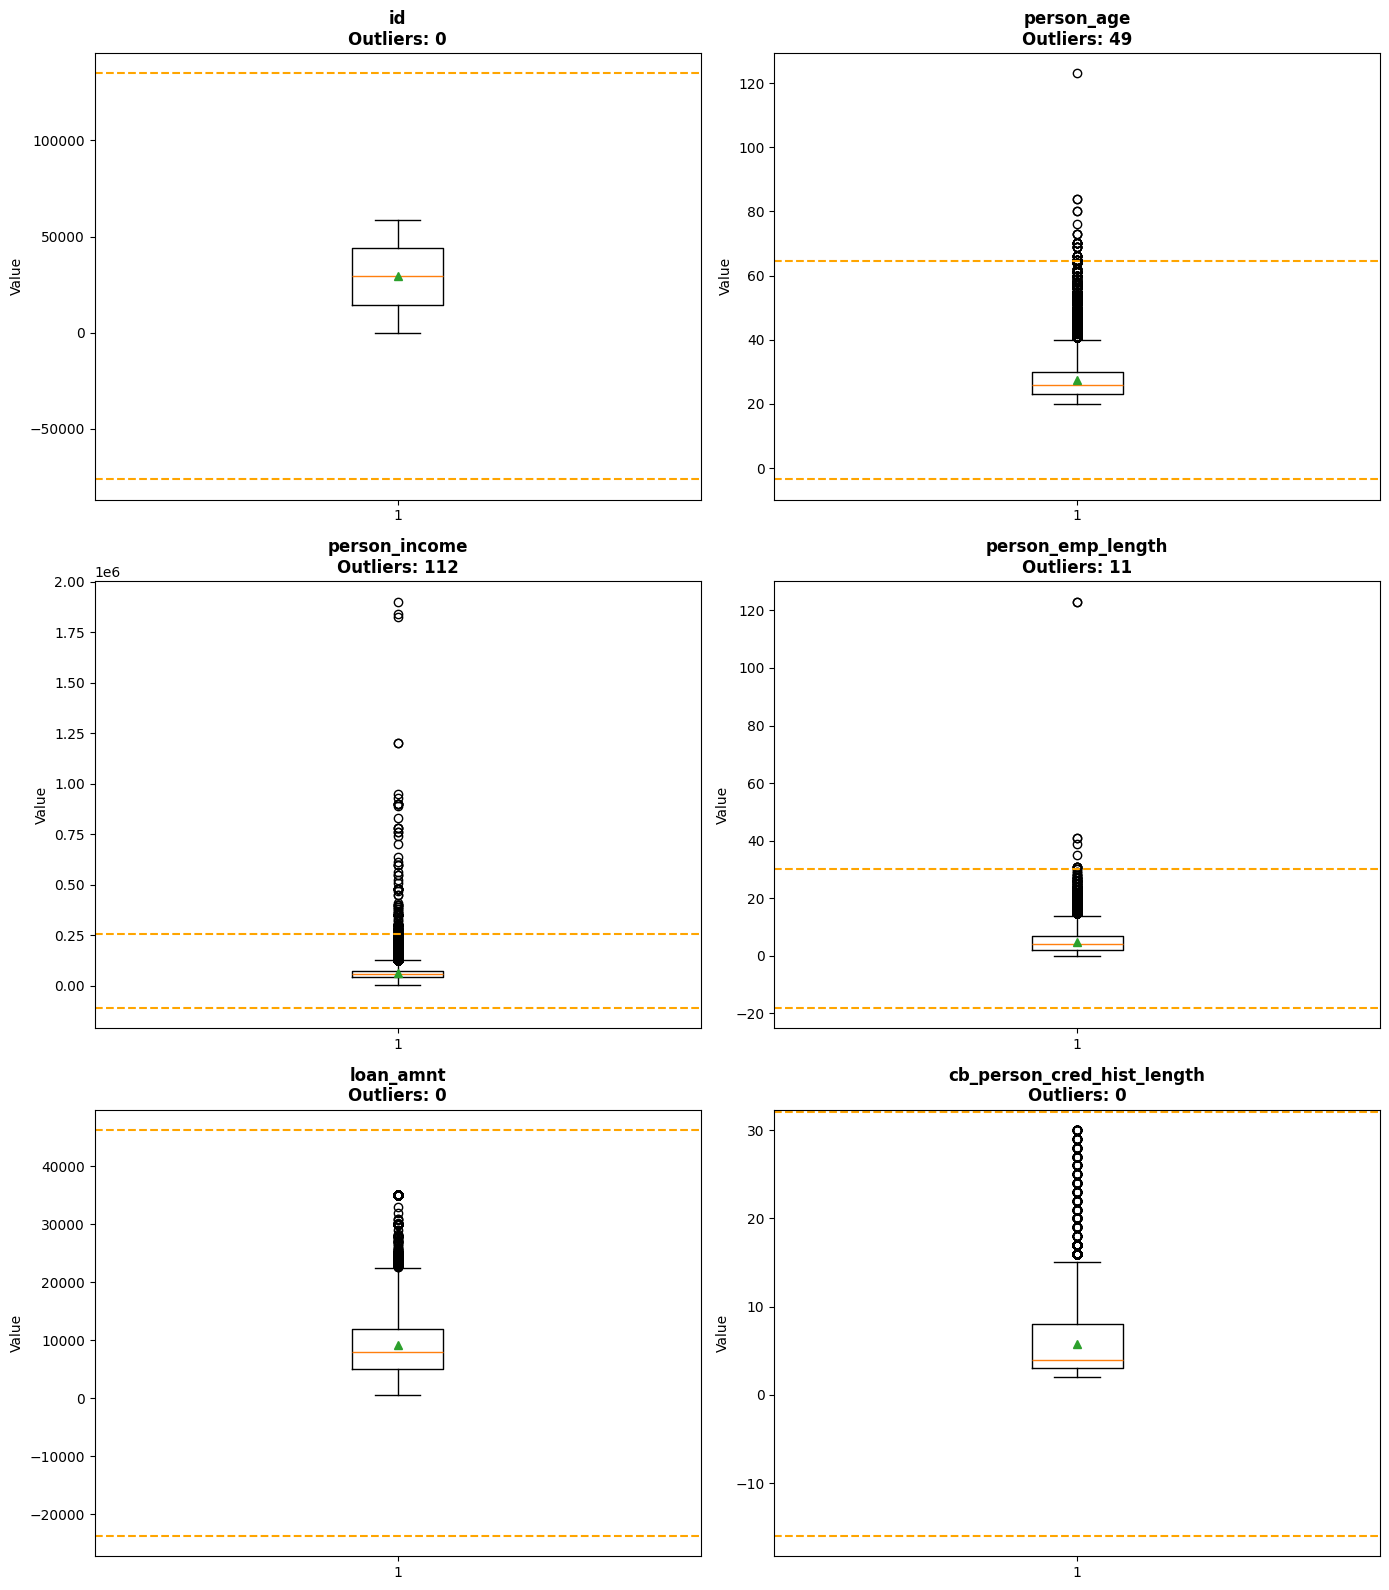

In [ ]:
plot_boxplots_with_outliers(df, num_cols)

In [ ]:
df_age_emp = df[(df["person_age"] - df["person_emp_length"] < 15)]
display(df_age_emp)

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status
699,699,30,76500,MORTGAGE,19,MEDICAL,A,14750,6.620,0.200,N,8,0
746,746,23,100000,MORTGAGE,17,PERSONAL,A,17000,7.490,0.170,N,3,0
2640,2640,29,87600,MORTGAGE,15,MEDICAL,B,4000,11.490,0.040,N,6,1
3072,3072,24,72000,RENT,12,HOMEIMPROVEMENT,B,14000,12.690,0.190,N,2,0
8222,8222,26,64999,MORTGAGE,13,EDUCATION,B,12000,10.990,0.170,N,3,0
12638,12638,32,61000,MORTGAGE,21,VENTURE,B,12000,11.490,0.200,N,6,0
15070,15070,26,97908,MORTGAGE,12,DEBTCONSOLIDATION,D,17500,16.070,0.180,N,2,1
15921,15921,27,70000,RENT,14,VENTURE,E,9000,16.000,0.130,Y,7,0
16378,16378,36,54400,RENT,24,MEDICAL,A,6000,9.630,0.090,N,17,1
16446,16446,26,95000,RENT,12,PERSONAL,C,12000,13.490,0.130,Y,3,0


In [ ]:
df_age70 = df[df["person_age"] > 80]
display(df_age70)

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status
4962,4962,84,108928,MORTGAGE,3,DEBTCONSOLIDATION,A,6000,7.510,0.060,N,25,0
6750,6750,84,94800,MORTGAGE,2,PERSONAL,D,10000,14.090,0.110,N,22,0
47336,47336,123,36000,MORTGAGE,7,PERSONAL,B,6700,10.750,0.180,N,4,0


In [ ]:
df_emp50 = df[df["person_emp_length"] > 50]
display(df_emp50)

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status
41079,41079,28,60350,MORTGAGE,123,MEDICAL,D,25000,15.950,0.350,Y,6,1
49252,49252,21,192000,MORTGAGE,123,VENTURE,B,20000,11.490,0.100,N,2,0


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,58645.000,29322.000,16929.498,0.000,14661.000,29322.000,43983.000,58644.000
person_age,58645.000,27.551,6.033,20.000,23.000,26.000,30.000,123.000
person_income,58645.000,64046.173,37931.107,4200.000,42000.000,58000.000,75600.000,1900000.000
person_emp_length,58645.000,4.701,3.960,0.000,2.000,4.000,7.000,123.000
loan_amnt,58645.000,9217.557,5563.807,500.000,5000.000,8000.000,12000.000,35000.000
loan_int_rate,58645.000,10.678,3.035,5.420,7.880,10.750,12.990,23.220
loan_percent_income,58645.000,0.166,1.588,0.000,0.090,0.140,0.210,384.000
cb_person_cred_hist_length,58645.000,5.814,4.029,2.000,3.000,4.000,8.000,30.000
loan_status,58645.000,0.142,0.349,0.000,0.000,0.000,0.000,1.000


In [ ]:

def replace_with_thresholds(dataframe, variable, q1=0.05, q3=0.95):
    low_limit, up_limit = outlier_thresholds(dataframe, variable, q1, q3)
    dataframe.loc[dataframe[variable] < low_limit, variable] = low_limit
    dataframe.loc[dataframe[variable] > up_limit, variable] = up_limit

In [ ]:
for col in num_cols:
    replace_with_thresholds(df, col)

In [ ]:
for col in num_cols:
    print(col, check_outlier(df, col))

id False
person_age False
person_income False
person_emp_length False
loan_amnt False
cb_person_cred_hist_length False


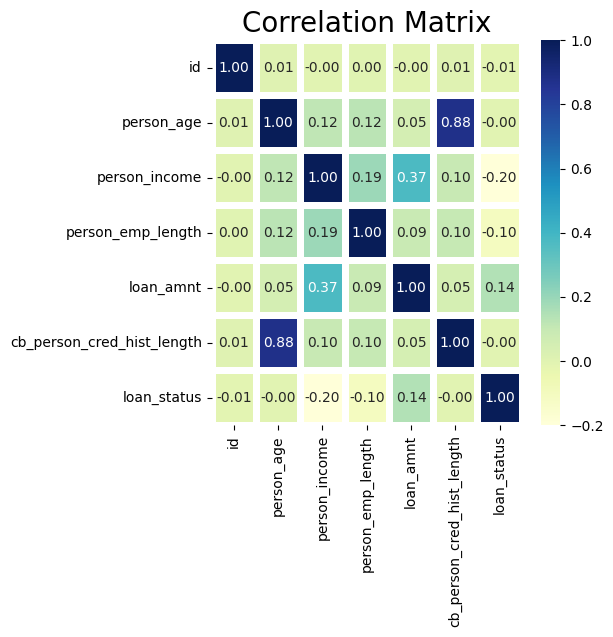

In [ ]:
f, ax = plt.subplots(figsize=(5, 5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", ax=ax, cmap="YlGnBu", linewidths=5)
ax.set_title("Correlation Matrix", fontsize=20)
plt.show()


In [ ]:
def p2p_portfolio_analysis(df):
    """
    P2P lending perspektifiyle analiz
    """
    for grade in ['A', 'B', 'C', 'D', 'E', 'F', 'G']:
        subset = df[df['loan_grade'] == grade]
        avg_rate = subset['loan_int_rate'].mean()
        default_rate = subset['loan_status'].mean()   # 0/1 olarak
        net_return = avg_rate * (1 - default_rate) - default_rate * 100

        # Başa baş faiz oranı
        breakeven_rate = (default_rate * 100) / (1 - default_rate) if default_rate < 1 else float("inf")

        print(f"Grade {grade}:")
        print(f"  Ortalama Faiz: %{avg_rate:.2f}")
        print(f"  Default Oranı: %{default_rate*100:.2f}")
        print(f"  Net Getiri: %{net_return:.2f}")
        print(f"  Başa Baş Faiz: %{breakeven_rate:.2f}")
        print(f"  Karlılık: {'KARLI ✅' if net_return > 0 else 'ZARARLI ❌'}\n")


In [ ]:
df["loan_status"] = pd.to_numeric(df["loan_status"], errors="coerce").fillna(0).astype(int)
num_cols.append("loan_status")


In [ ]:
cat_cols.remove("loan_status")

In [ ]:
cat_cols

['person_home_ownership',
 'loan_intent',
 'loan_grade',
 'cb_person_default_on_file']

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58645 entries, 0 to 58644
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   id                          58645 non-null  float64 
 1   person_age                  58645 non-null  float64 
 2   person_income               58645 non-null  int64   
 3   person_home_ownership       58645 non-null  category
 4   person_emp_length           58645 non-null  int64   
 5   loan_intent                 58645 non-null  category
 6   loan_grade                  58645 non-null  category
 7   loan_amnt                   58645 non-null  int64   
 8   loan_int_rate               58645 non-null  float64 
 9   loan_percent_income         58645 non-null  float64 
 10  cb_person_default_on_file   58645 non-null  category
 11  cb_person_cred_hist_length  58645 non-null  int64   
 12  loan_status                 58645 non-null  int64   
dtypes: category(4), 

In [ ]:
p2p_portfolio_analysis(df)

Grade A:
  Ortalama Faiz: %7.34
  Default Oranı: %4.92
  Net Getiri: %2.06
  Başa Baş Faiz: %5.17
  Karlılık: KARLI ✅

Grade B:
  Ortalama Faiz: %11.03
  Default Oranı: %10.23
  Net Getiri: %-0.32
  Başa Baş Faiz: %11.40
  Karlılık: ZARARLI ❌

Grade C:
  Ortalama Faiz: %13.51
  Default Oranı: %13.54
  Net Getiri: %-1.86
  Başa Baş Faiz: %15.66
  Karlılık: ZARARLI ❌

Grade D:
  Ortalama Faiz: %15.40
  Default Oranı: %59.36
  Net Getiri: %-53.10
  Başa Baş Faiz: %146.04
  Karlılık: ZARARLI ❌

Grade E:
  Ortalama Faiz: %16.93
  Default Oranı: %62.54
  Net Getiri: %-56.19
  Başa Baş Faiz: %166.93
  Karlılık: ZARARLI ❌

Grade F:
  Ortalama Faiz: %18.61
  Default Oranı: %61.07
  Net Getiri: %-53.83
  Başa Baş Faiz: %156.90
  Karlılık: ZARARLI ❌

Grade G:
  Ortalama Faiz: %20.33
  Default Oranı: %81.82
  Net Getiri: %-78.12
  Başa Baş Faiz: %450.00
  Karlılık: ZARARLI ❌



In [ ]:
# Debt-to-Income Ratio (DTI)
df['dti_ratio'] = df['loan_amnt'] / df['person_income']

# Payment-to-Income Ratio
df['payment_to_income'] = (df['loan_amnt'] * df['loan_int_rate'] / 100) / df['person_income']

# Income per Year of Employment
df['income_per_emp_year'] = df['person_income'] / (df['person_emp_length'] + 1)  # Add 1 to avoid division by zero

# Loan Amount to Credit History Ratio
df['loan_to_credit_history'] = df['loan_amnt'] / (df['cb_person_cred_hist_length'] + 1)

# Age to Employment Length Ratio
df['age_emp_ratio'] = df['person_age'] / (df['person_emp_length'] + 1)

# Annual Debt Service
df['annual_debt_service'] = df['loan_amnt'] * df['loan_int_rate'] / 100

In [ ]:
df.head()

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status,dti_ratio,payment_to_income,income_per_emp_year,loan_to_credit_history,age_emp_ratio,annual_debt_service
0,0.000,37.000,35000,RENT,0,EDUCATION,B,6000,11.490,0.170,N,14,0,0.171,0.020,35000.000,400.000,37.000,689.400
1,1.000,22.000,56000,OWN,6,MEDICAL,C,4000,13.350,0.070,N,2,0,0.071,0.010,8000.000,1333.333,3.143,534.000
2,2.000,29.000,28800,OWN,8,PERSONAL,A,6000,8.900,0.210,N,10,0,0.208,0.019,3200.000,545.455,3.222,534.000
3,3.000,30.000,70000,RENT,14,VENTURE,B,12000,11.110,0.170,N,5,0,0.171,0.019,4666.667,2000.000,2.000,1333.200
4,4.000,22.000,60000,RENT,2,MEDICAL,A,6000,6.920,0.100,N,3,0,0.100,0.007,20000.000,1500.000,7.333,415.200


In [ ]:
'''# Risk Score (Custom)
df['risk_score'] = (
    df['loan_grade'].map({'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7}) *
    df['loan_percent_income'] *
    (2 if df['cb_person_default_on_file'] == 'Y' else 1)
)

# Stability Index
df['stability_index'] = (
    df['person_emp_length'] * 0.3 +
    df['cb_person_cred_hist_length'] * 0.3 +
    (df['person_home_ownership'].map({'OWN': 10, 'MORTGAGE': 7, 'RENT': 3, 'OTHER': 1}) * 0.4)
)

# Income-Grade Interaction
df['income_grade_interaction'] = df['person_income'] / df['loan_grade'].map({'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7})'''

In [ ]:
df['stability_index'] = (
    df['person_emp_length'] * 0.3 +
    df['cb_person_cred_hist_length'] * 0.3 +
    df['person_home_ownership'].map({'OWN': 10, 'MORTGAGE': 7, 'RENT': 3, 'OTHER': 1}).astype(float) * 0.4
)

In [ ]:
df.head()

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status,dti_ratio,payment_to_income,income_per_emp_year,loan_to_credit_history,age_emp_ratio,annual_debt_service,stability_index
0,0.000,37.000,35000,RENT,0,EDUCATION,B,6000,11.490,0.170,N,14,0,0.171,0.020,35000.000,400.000,37.000,689.400,5.400
1,1.000,22.000,56000,OWN,6,MEDICAL,C,4000,13.350,0.070,N,2,0,0.071,0.010,8000.000,1333.333,3.143,534.000,6.400
2,2.000,29.000,28800,OWN,8,PERSONAL,A,6000,8.900,0.210,N,10,0,0.208,0.019,3200.000,545.455,3.222,534.000,9.400
3,3.000,30.000,70000,RENT,14,VENTURE,B,12000,11.110,0.170,N,5,0,0.171,0.019,4666.667,2000.000,2.000,1333.200,6.900
4,4.000,22.000,60000,RENT,2,MEDICAL,A,6000,6.920,0.100,N,3,0,0.100,0.007,20000.000,1500.000,7.333,415.200,2.700


In [ ]:
grade_map = {'A':1,'B':2,'C':3,'D':4,'E':5,'F':6,'G':7}
df['income_grade_interaction'] = df['person_income'] / df['loan_grade'].map(grade_map).astype(float)

In [ ]:
df.head()

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status,calc_loan_percent_income,difference,dti_ratio,payment_to_income,income_per_emp_year,loan_to_credit_history,age_emp_ratio,annual_debt_service,stability_index,income_grade_interaction
0,0.000,37.000,35000,RENT,0,EDUCATION,B,6000,11.490,0.170,N,14,0,0.171,-0.001,0.171,0.020,35000.000,400.000,37.000,689.400,5.400,17500.000
1,1.000,22.000,56000,OWN,6,MEDICAL,C,4000,13.350,0.070,N,2,0,0.071,-0.001,0.071,0.010,8000.000,1333.333,3.143,534.000,6.400,18666.667
2,2.000,29.000,28800,OWN,8,PERSONAL,A,6000,8.900,0.210,N,10,0,0.208,0.002,0.208,0.019,3200.000,545.455,3.222,534.000,9.400,28800.000
3,3.000,30.000,70000,RENT,14,VENTURE,B,12000,11.110,0.170,N,5,0,0.171,-0.001,0.171,0.019,4666.667,2000.000,2.000,1333.200,6.900,35000.000
4,4.000,22.000,60000,RENT,2,MEDICAL,A,6000,6.920,0.100,N,3,0,0.100,0.000,0.100,0.007,20000.000,1500.000,7.333,415.200,2.700,60000.000


In [ ]:
# Risk Score (senin kurallarınla)
def calculate_risk_score(row):
    score = 0
    grade_scores = {'A':5,'B':10,'C':15,'D':20,'E':25,'F':30,'G':35}
    score += grade_scores.get(row['loan_grade'], 35)

    if row['cb_person_default_on_file'] == 'Y':
        score += 20

    dti_ratio = row['loan_amnt'] / row['person_income']
    if dti_ratio > 0.5: score += 20
    elif dti_ratio > 0.3: score += 15
    elif dti_ratio > 0.2: score += 10
    elif dti_ratio > 0.1: score += 5

    if row['person_emp_length'] == 0: score += 15
    elif row['person_emp_length'] < 2: score += 10
    elif row['person_emp_length'] < 5: score += 5

    if row['person_age'] < 25: score += 10
    elif row['person_age'] < 30: score += 5

    return score

In [ ]:
df['risk_score'] = df.apply(calculate_risk_score, axis=1)

In [ ]:
df.head()

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status,dti_ratio,payment_to_income,income_per_emp_year,loan_to_credit_history,age_emp_ratio,annual_debt_service,stability_index,income_grade_interaction,risk_score
0,0.000,37.000,35000,RENT,0,EDUCATION,B,6000,11.490,0.170,N,14,0,0.171,0.020,35000.000,400.000,37.000,689.400,5.400,17500.000,30
1,1.000,22.000,56000,OWN,6,MEDICAL,C,4000,13.350,0.070,N,2,0,0.071,0.010,8000.000,1333.333,3.143,534.000,6.400,18666.667,25
2,2.000,29.000,28800,OWN,8,PERSONAL,A,6000,8.900,0.210,N,10,0,0.208,0.019,3200.000,545.455,3.222,534.000,9.400,28800.000,20
3,3.000,30.000,70000,RENT,14,VENTURE,B,12000,11.110,0.170,N,5,0,0.171,0.019,4666.667,2000.000,2.000,1333.200,6.900,35000.000,15
4,4.000,22.000,60000,RENT,2,MEDICAL,A,6000,6.920,0.100,N,3,0,0.100,0.007,20000.000,1500.000,7.333,415.200,2.700,60000.000,20


In [ ]:
# Risk Category
def assign_risk_category(score):
    if score <= 20:
        return 'Very Low Risk'
    elif score <= 35:
        return 'Low Risk'
    elif score <= 50:
        return 'Medium Risk'
    elif score <= 65:
        return 'High Risk'
    else:
        return 'Very High Risk'


In [ ]:
df['risk_category'] = df['risk_score'].apply(assign_risk_category)

In [ ]:
df.head()

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status,dti_ratio,payment_to_income,income_per_emp_year,loan_to_credit_history,age_emp_ratio,annual_debt_service,stability_index,income_grade_interaction,risk_score,risk_category
0,0.000,37.000,35000,RENT,0,EDUCATION,B,6000,11.490,0.170,N,14,0,0.171,0.020,35000.000,400.000,37.000,689.400,5.400,17500.000,30,Low Risk
1,1.000,22.000,56000,OWN,6,MEDICAL,C,4000,13.350,0.070,N,2,0,0.071,0.010,8000.000,1333.333,3.143,534.000,6.400,18666.667,25,Low Risk
2,2.000,29.000,28800,OWN,8,PERSONAL,A,6000,8.900,0.210,N,10,0,0.208,0.019,3200.000,545.455,3.222,534.000,9.400,28800.000,20,Very Low Risk
3,3.000,30.000,70000,RENT,14,VENTURE,B,12000,11.110,0.170,N,5,0,0.171,0.019,4666.667,2000.000,2.000,1333.200,6.900,35000.000,15,Very Low Risk
4,4.000,22.000,60000,RENT,2,MEDICAL,A,6000,6.920,0.100,N,3,0,0.100,0.007,20000.000,1500.000,7.333,415.200,2.700,60000.000,20,Very Low Risk


In [ ]:
df.describe([0.01, 0.05, 0.1, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).T

,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max
id,58645.000,29322.000,16929.498,0.000,586.440,2932.200,5864.400,14661.000,29322.000,43983.000,52779.600,55711.800,58057.560,58644.000
person_age,58645.000,27.546,5.997,20.000,21.000,22.000,22.000,23.000,26.000,30.000,36.000,39.000,49.000,64.500
person_income,58645.000,63607.930,31341.324,4200.000,21600.000,28800.000,31200.000,42000.000,58000.000,75600.000,100000.000,120000.000,175000.000,256800.000
person_emp_length,58645.000,4.697,3.897,0.000,0.000,0.000,0.000,2.000,4.000,7.000,10.000,12.000,17.000,30.000
loan_amnt,58645.000,9217.557,5563.807,500.000,1286.000,2500.000,3000.000,5000.000,8000.000,12000.000,16000.000,20000.000,25000.000,35000.000
loan_int_rate,58645.000,10.678,3.035,5.420,5.420,6.030,6.760,7.880,10.750,12.990,14.720,15.700,17.490,23.220
loan_percent_income,58645.000,0.166,1.588,0.000,0.030,0.040,0.060,0.090,0.140,0.210,0.290,0.330,0.420,384.000
cb_person_cred_hist_length,58645.000,5.814,4.029,2.000,2.000,2.000,2.000,3.000,4.000,8.000,11.000,14.000,17.000,30.000
loan_status,58645.000,0.142,0.349,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000,1.000,1.000
dti_ratio,58645.000,0.160,0.094,0.004,0.025,0.042,0.057,0.089,0.142,0.209,0.292,0.338,0.427,3.125


In [ ]:


# 1. YAŞ GRUPLARI
df['age_group'] = pd.cut(df['person_age'],
                         bins=[20, 23, 26, 30, 36, 45, 65],
                         labels=['very_young', 'young', 'middle_young',
                                'middle', 'mature', 'senior'],
                         include_lowest=True)

# 2. GELİR DİLİMLERİ
df['income_bracket'] = pd.cut(df['person_income'],
                              bins=[0, 42000, 58000, 75600, 100000, 150000, float('inf')],
                              labels=['very_low', 'low', 'medium',
                                     'high', 'very_high', 'ultra_high'],
                              include_lowest=True)

# 3. KREDİ TUTARI
df['loan_size_category'] = pd.cut(df['loan_amnt'],
                                  bins=[0, 5000, 8000, 12000, 20000, float('inf')],
                                  labels=['mini', 'small', 'medium', 'large', 'xlarge'],
                                  include_lowest=True)

# 4. İSTİHDAM STABİLİTESİ
df['employment_stability'] = pd.cut(df['person_emp_length'],
                                   bins=[-1, 0, 2, 4, 7, 10, float('inf')],
                                   labels=['none', 'new', 'early', 'stable',
                                          'established', 'veteran'],
                                   include_lowest=True)

# 5. KREDİ GEÇMİŞİ
df['credit_maturity'] = pd.cut(df['cb_person_cred_hist_length'],
                               bins=[1.9, 3, 4, 8, 14, float('inf')],
                               labels=['very_new', 'new', 'building',
                                      'established', 'mature'],
                               include_lowest=True)

# 6. RİSK SKORU
df['risk_score_category'] = pd.cut(df['risk_score'],
                                   bins=[0, 20, 25, 35, 50, 70, float('inf')],
                                   labels=['very_low', 'low', 'medium',
                                          'high', 'very_high', 'extreme'],
                                   include_lowest=True)

# 7. DTI RATIO
df['dti_category'] = pd.cut(df['dti_ratio'],
                            bins=[0, 0.089, 0.142, 0.209, 0.338, 0.5, float('inf')],
                            labels=['excellent', 'good', 'fair',
                                   'poor', 'risky', 'very_risky'],
                            include_lowest=True)

# 8. PAYMENT TO INCOME
df['payment_burden'] = pd.cut(df['payment_to_income'],
                              bins=[0, 0.008, 0.014, 0.023, 0.042, 0.1, float('inf')],
                              labels=['very_light', 'light', 'moderate',
                                     'heavy', 'very_heavy', 'extreme'],
                              include_lowest=True)

# 9. FAİZ ORANI
df['interest_rate_category'] = pd.cut(df['loan_int_rate'],
                                      bins=[5, 7.88, 10.75, 12.99, 15.7, 20, float('inf')],
                                      labels=['prime', 'near_prime', 'standard',
                                             'subprime', 'high_risk', 'very_high_risk'],
                                      include_lowest=True)

# 10. STABİLİTE İNDEKSİ
df['stability_category'] = pd.cut(df['stability_index'],
                                  bins=[0, 3.6, 4.9, 6.4, 9.1, float('inf')],
                                  labels=['very_unstable', 'unstable', 'moderate',
                                         'stable', 'very_stable'],
                                  include_lowest=True)

In [ ]:
df.head()

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status,dti_ratio,payment_to_income,income_per_emp_year,loan_to_credit_history,age_emp_ratio,annual_debt_service,stability_index,income_grade_interaction,risk_score,risk_category,age_group,income_bracket,loan_size_category,employment_stability,credit_maturity,risk_score_category,dti_category,payment_burden,interest_rate_category,stability_category
0,0.000,37.000,35000,RENT,0,EDUCATION,B,6000,11.490,0.170,N,14,0,0.171,0.020,35000.000,400.000,37.000,689.400,5.400,17500.000,30,Low Risk,mature,very_low,small,none,established,medium,fair,moderate,standard,moderate
1,1.000,22.000,56000,OWN,6,MEDICAL,C,4000,13.350,0.070,N,2,0,0.071,0.010,8000.000,1333.333,3.143,534.000,6.400,18666.667,25,Low Risk,very_young,low,mini,stable,very_new,low,excellent,light,subprime,moderate
2,2.000,29.000,28800,OWN,8,PERSONAL,A,6000,8.900,0.210,N,10,0,0.208,0.019,3200.000,545.455,3.222,534.000,9.400,28800.000,20,Very Low Risk,middle_young,very_low,small,established,established,very_low,fair,moderate,near_prime,very_stable
3,3.000,30.000,70000,RENT,14,VENTURE,B,12000,11.110,0.170,N,5,0,0.171,0.019,4666.667,2000.000,2.000,1333.200,6.900,35000.000,15,Very Low Risk,middle_young,medium,medium,veteran,building,very_low,fair,moderate,standard,stable
4,4.000,22.000,60000,RENT,2,MEDICAL,A,6000,6.920,0.100,N,3,0,0.100,0.007,20000.000,1500.000,7.333,415.200,2.700,60000.000,20,Very Low Risk,very_young,medium,small,new,very_new,very_low,good,very_light,prime,very_unstable


In [ ]:
# Income Percentile by Age Group
df['income_percentile_by_age'] = df.groupby('age_group')['person_income'].rank(pct=True)

# Loan Amount Percentile by Income Bracket
df['loan_amt_percentile_by_income'] = df.groupby('income_bracket')['loan_amnt'].rank(pct=True)

# Interest Rate Deviation from Grade Mean
df['int_rate_deviation'] = df['loan_int_rate'] - df.groupby('loan_grade')['loan_int_rate'].transform('mean')

# Is Above Median DTI for Grade
df['above_median_dti_for_grade'] = (
    df['dti_ratio'] > df.groupby('loan_grade')['dti_ratio'].transform('median')
).astype(int)

In [ ]:
df.head()

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status,dti_ratio,payment_to_income,income_per_emp_year,loan_to_credit_history,age_emp_ratio,annual_debt_service,stability_index,income_grade_interaction,risk_score,risk_category,age_group,income_bracket,loan_size_category,employment_stability,credit_maturity,risk_score_category,dti_category,payment_burden,interest_rate_category,stability_category,income_percentile_by_age,loan_amt_percentile_by_income,int_rate_deviation,above_median_dti_for_grade
0,0.000,37.000,35000,RENT,0,EDUCATION,B,6000,11.490,0.170,N,14,0,0.171,0.020,35000.000,400.000,37.000,689.400,5.400,17500.000,30,Low Risk,mature,very_low,small,none,established,medium,fair,moderate,standard,moderate,0.114,0.515,0.455,1
1,1.000,22.000,56000,OWN,6,MEDICAL,C,4000,13.350,0.070,N,2,0,0.071,0.010,8000.000,1333.333,3.143,534.000,6.400,18666.667,25,Low Risk,very_young,low,mini,stable,very_new,low,excellent,light,subprime,moderate,0.577,0.168,-0.160,0
2,2.000,29.000,28800,OWN,8,PERSONAL,A,6000,8.900,0.210,N,10,0,0.208,0.019,3200.000,545.455,3.222,534.000,9.400,28800.000,20,Very Low Risk,middle_young,very_low,small,established,established,very_low,fair,moderate,near_prime,very_stable,0.035,0.515,1.565,1
3,3.000,30.000,70000,RENT,14,VENTURE,B,12000,11.110,0.170,N,5,0,0.171,0.019,4666.667,2000.000,2.000,1333.200,6.900,35000.000,15,Very Low Risk,middle_young,medium,medium,veteran,building,very_low,fair,moderate,standard,stable,0.633,0.705,0.075,1
4,4.000,22.000,60000,RENT,2,MEDICAL,A,6000,6.920,0.100,N,3,0,0.100,0.007,20000.000,1500.000,7.333,415.200,2.700,60000.000,20,Very Low Risk,very_young,medium,small,new,very_new,very_low,good,very_light,prime,very_unstable,0.640,0.274,-0.415,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58645 entries, 0 to 58644
Data columns (total 37 columns):
 #   Column                         Non-Null Count  Dtype   
---  ------                         --------------  -----   
 0   id                             58645 non-null  float64 
 1   person_age                     58645 non-null  float64 
 2   person_income                  58645 non-null  int64   
 3   person_home_ownership          58645 non-null  category
 4   person_emp_length              58645 non-null  int64   
 5   loan_intent                    58645 non-null  category
 6   loan_grade                     58645 non-null  category
 7   loan_amnt                      58645 non-null  int64   
 8   loan_int_rate                  58645 non-null  float64 
 9   loan_percent_income            58645 non-null  float64 
 10  cb_person_default_on_file      58645 non-null  category
 11  cb_person_cred_hist_length     58645 non-null  int64   
 12  loan_status                    5

In [ ]:
cat_cols, num_cols, cat_but_car, num_but_cat = grab_col_names(df)

Observations: 58645
Variables: 37
cat_cols: 17
num_cols: 20
cat_but_car: 0
num_but_cat: 2


In [ ]:
num_but_cat

['loan_status', 'above_median_dti_for_grade']

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58645 entries, 0 to 58644
Data columns (total 37 columns):
 #   Column                         Non-Null Count  Dtype   
---  ------                         --------------  -----   
 0   id                             58645 non-null  float64 
 1   person_age                     58645 non-null  float64 
 2   person_income                  58645 non-null  int64   
 3   person_home_ownership          58645 non-null  category
 4   person_emp_length              58645 non-null  int64   
 5   loan_intent                    58645 non-null  category
 6   loan_grade                     58645 non-null  category
 7   loan_amnt                      58645 non-null  int64   
 8   loan_int_rate                  58645 non-null  float64 
 9   loan_percent_income            58645 non-null  float64 
 10  cb_person_default_on_file      58645 non-null  category
 11  cb_person_cred_hist_length     58645 non-null  int64   
 12  loan_status                    5

In [ ]:
num_cols.append("loan_status")

In [ ]:
num_cols.append("above_median_dti_for_grade")

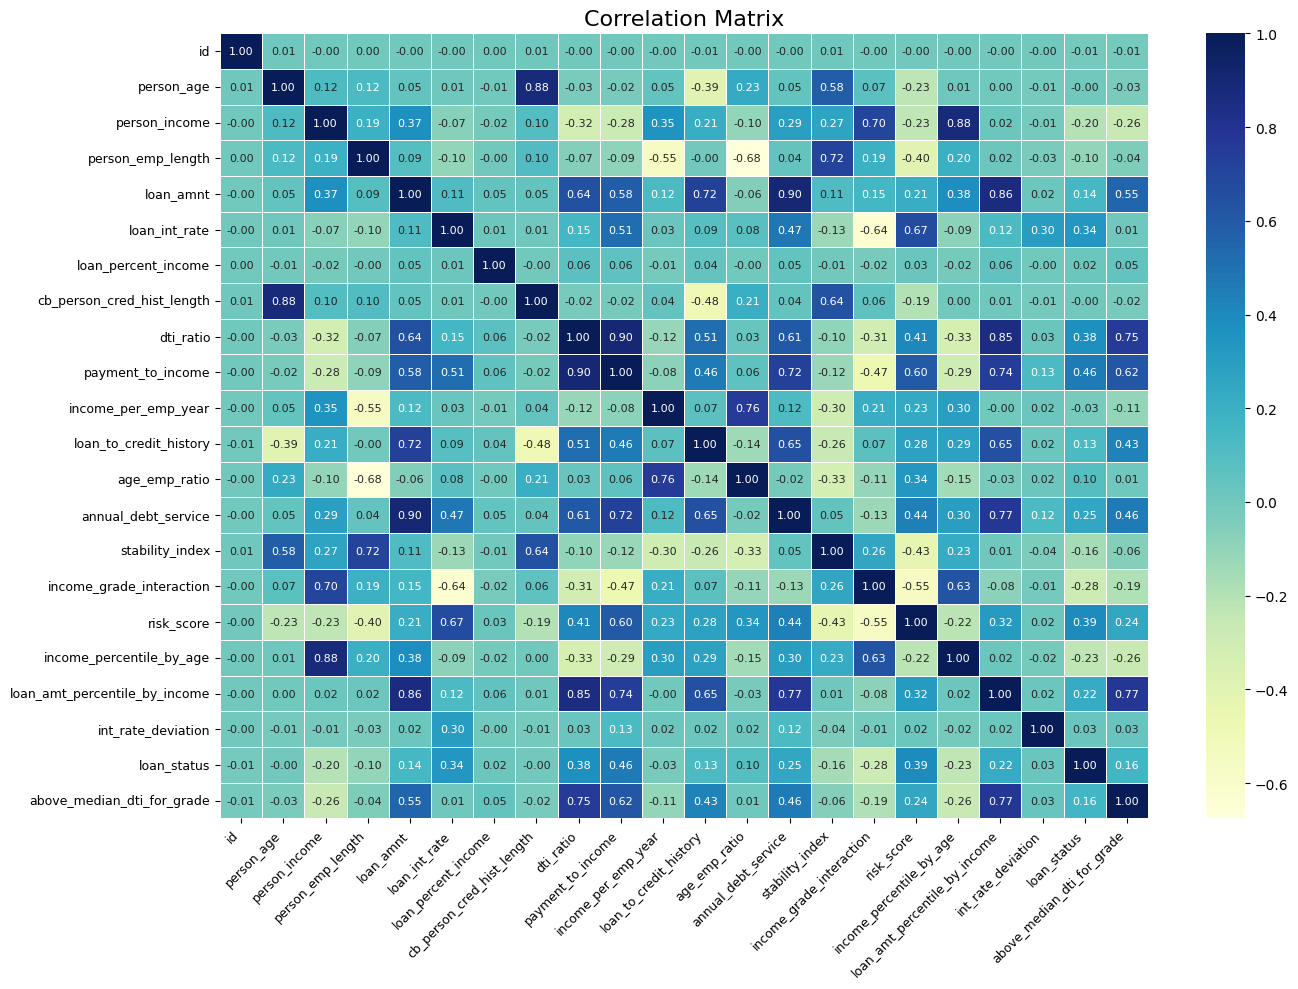

In [ ]:
plt.figure(figsize=(14, 10))  # daha geniş alan
corr = df[num_cols].corr()

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    annot_kws={"size": 8}   # annot yazı boyutu
)

plt.title("Correlation Matrix", fontsize=16)
plt.xticks(rotation=45, ha='right', fontsize=9)  # x ekseni yazılarını döndür
plt.yticks(rotation=0, fontsize=9)              # y ekseni yatay kalsın
plt.tight_layout()
plt.show()


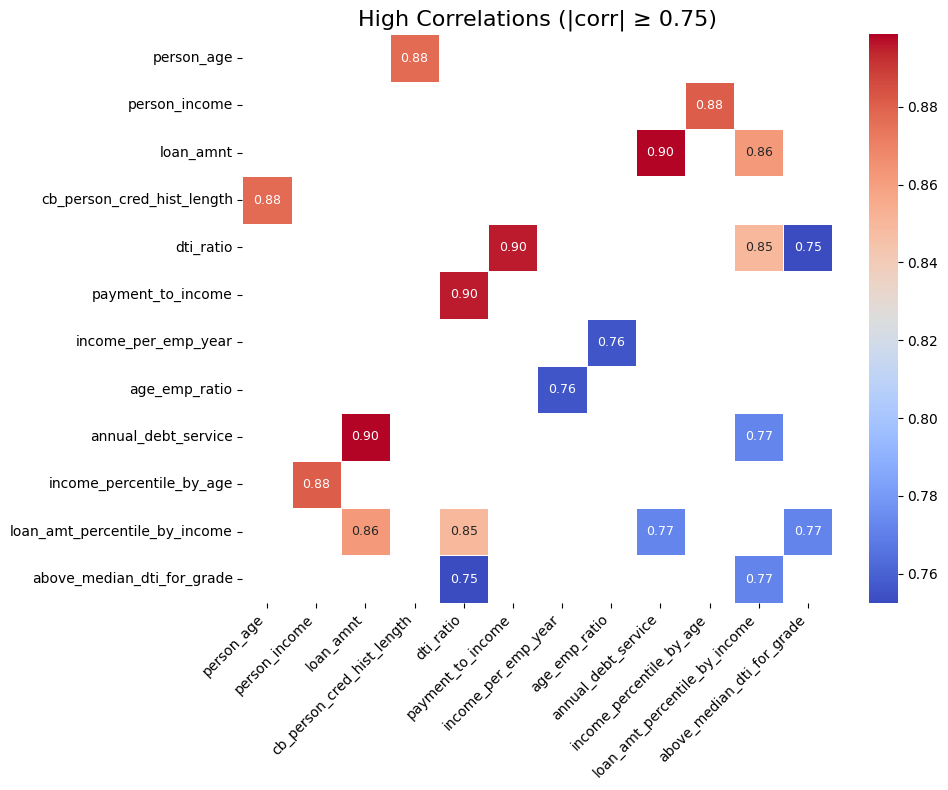

In [ ]:
# Korelasyon matrisi
corr = df[num_cols].corr()

# Eşik belirle
threshold = 0.75

# Sadece eşik üzeri korelasyonları filtrele
mask = (corr.abs() >= threshold) & (corr.abs() < 1.0)
high_corr = corr[mask]

# Sadece dolu kolonlar satırlar
filtered = high_corr.dropna(axis=0, how="all").dropna(axis=1, how="all")

plt.figure(figsize=(10, 8))
sns.heatmap(
    filtered,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    annot_kws={"size": 9}
)
plt.title("High Correlations (|corr| ≥ 0.75)", fontsize=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
# Drop list
features_to_drop = [
    "annual_debt_service",  # loan_amnt ve payment_to_income ile yüksek
    "payment_to_income"     # dti_ratio ile çok yüksek korelasyon
]

# DataFrame'den drop et
dff = df.drop(columns=features_to_drop, errors="ignore")

# num_cols güncelle
num_cols = [col for col in num_cols if col not in features_to_drop]

print(f"Önceki feature sayısı: {df.shape[1]}")
print(f"Yeni feature sayısı: {dff.shape[1]}")
print(f"Atılan feature sayısı: {df.shape[1] - dff.shape[1]}")
print(f"Yeni num_cols uzunluğu: {len(num_cols)}")



Önceki feature sayısı: 37
Yeni feature sayısı: 35
Atılan feature sayısı: 2
Yeni num_cols uzunluğu: 20


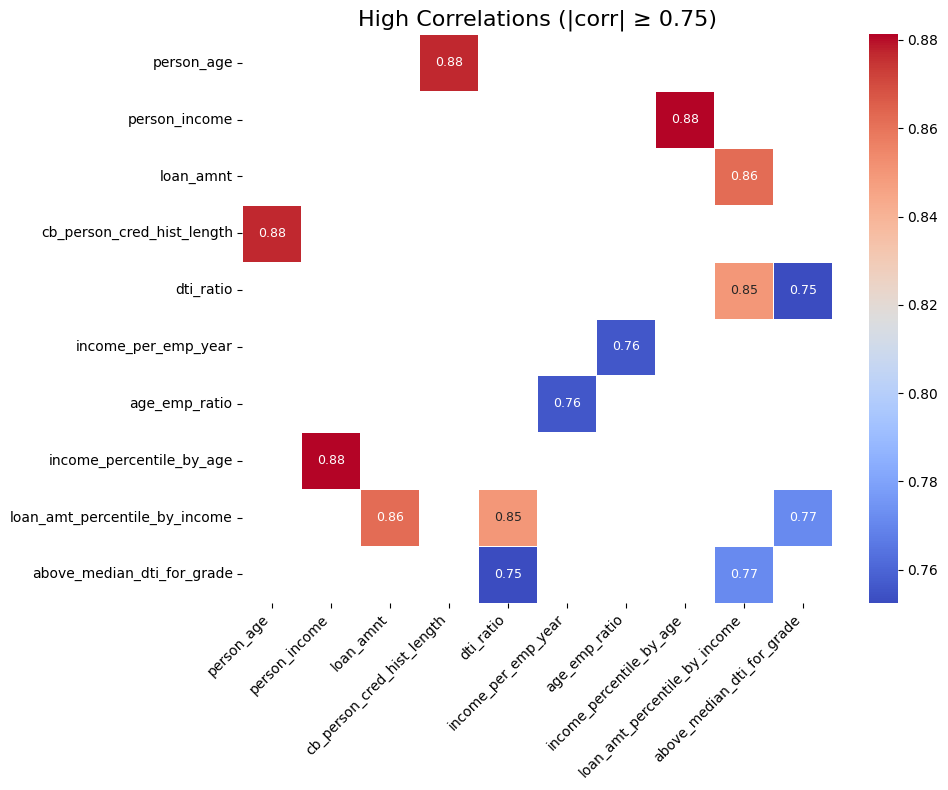

In [ ]:
# Korelasyon matrisi
corr = df[num_cols].corr()

# Eşik belirle
threshold = 0.75

# Sadece eşik üzeri korelasyonları filtrele
mask = (corr.abs() >= threshold) & (corr.abs() < 1.0)
high_corr = corr[mask]

# Sadece dolu kolonlar satırlar
filtered = high_corr.dropna(axis=0, how="all").dropna(axis=1, how="all")

plt.figure(figsize=(10, 8))
sns.heatmap(
    filtered,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    annot_kws={"size": 9}
)
plt.title("High Correlations (|corr| ≥ 0.75)", fontsize=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
dff.head()

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status,dti_ratio,income_per_emp_year,loan_to_credit_history,age_emp_ratio,stability_index,income_grade_interaction,risk_score,risk_category,age_group,income_bracket,loan_size_category,employment_stability,credit_maturity,risk_score_category,dti_category,payment_burden,interest_rate_category,stability_category,income_percentile_by_age,loan_amt_percentile_by_income,int_rate_deviation,above_median_dti_for_grade
0,0.000,37.000,35000,RENT,0,EDUCATION,B,6000,11.490,0.170,N,14,0,0.171,35000.000,400.000,37.000,5.400,17500.000,30,Low Risk,mature,very_low,small,none,established,medium,fair,moderate,standard,moderate,0.114,0.515,0.455,1
1,1.000,22.000,56000,OWN,6,MEDICAL,C,4000,13.350,0.070,N,2,0,0.071,8000.000,1333.333,3.143,6.400,18666.667,25,Low Risk,very_young,low,mini,stable,very_new,low,excellent,light,subprime,moderate,0.577,0.168,-0.160,0
2,2.000,29.000,28800,OWN,8,PERSONAL,A,6000,8.900,0.210,N,10,0,0.208,3200.000,545.455,3.222,9.400,28800.000,20,Very Low Risk,middle_young,very_low,small,established,established,very_low,fair,moderate,near_prime,very_stable,0.035,0.515,1.565,1
3,3.000,30.000,70000,RENT,14,VENTURE,B,12000,11.110,0.170,N,5,0,0.171,4666.667,2000.000,2.000,6.900,35000.000,15,Very Low Risk,middle_young,medium,medium,veteran,building,very_low,fair,moderate,standard,stable,0.633,0.705,0.075,1
4,4.000,22.000,60000,RENT,2,MEDICAL,A,6000,6.920,0.100,N,3,0,0.100,20000.000,1500.000,7.333,2.700,60000.000,20,Very Low Risk,very_young,medium,small,new,very_new,very_low,good,very_light,prime,very_unstable,0.640,0.274,-0.415,0


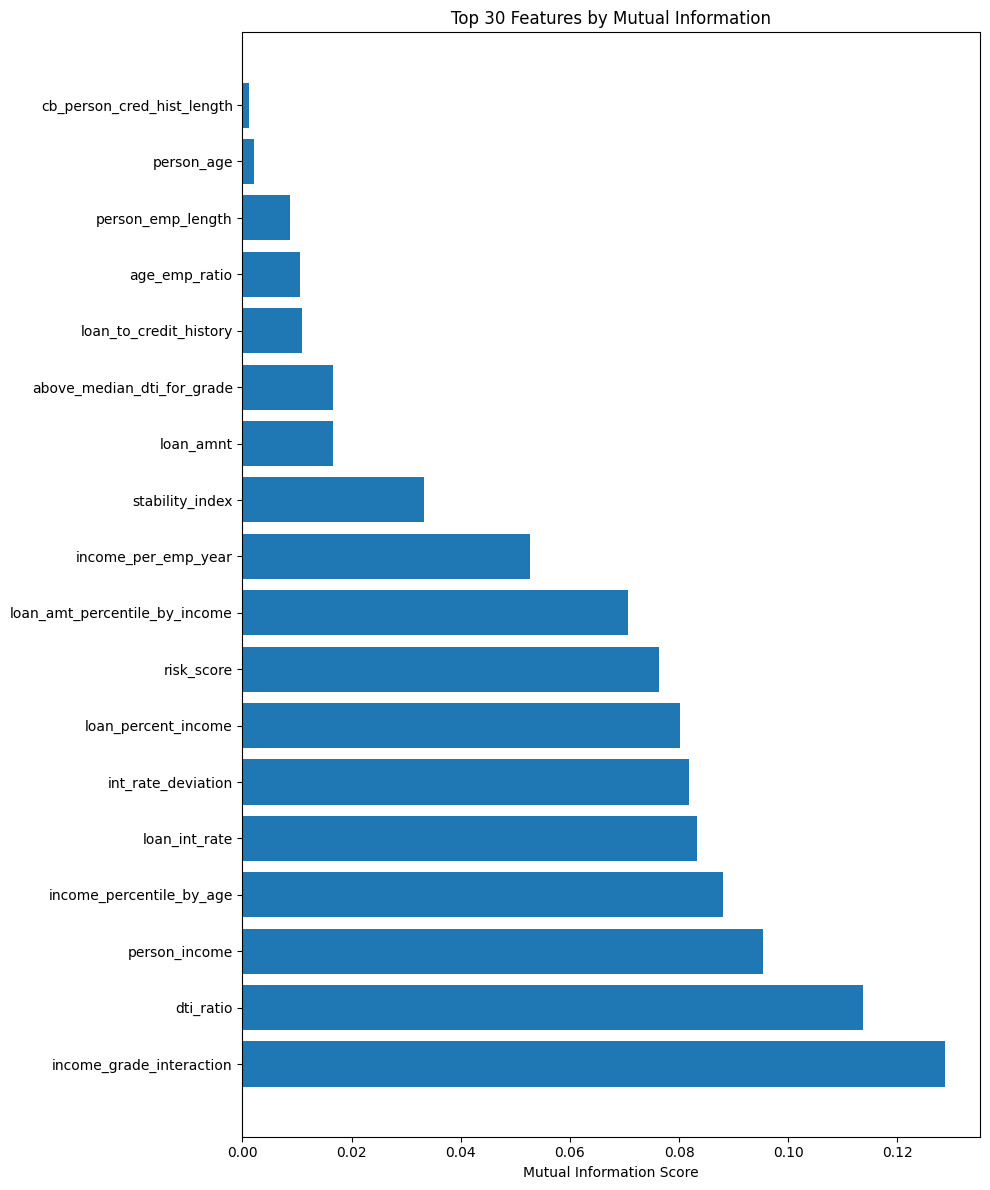


Top 20 Features by Mutual Information:
                          feature  mi_score
12       income_grade_interaction     0.129
7                       dti_ratio     0.114
1                   person_income     0.095
14       income_percentile_by_age     0.088
4                   loan_int_rate     0.083
16             int_rate_deviation     0.082
5             loan_percent_income     0.080
13                     risk_score     0.076
15  loan_amt_percentile_by_income     0.071
8             income_per_emp_year     0.053
11                stability_index     0.033
3                       loan_amnt     0.017
17     above_median_dti_for_grade     0.017
9          loan_to_credit_history     0.011
10                  age_emp_ratio     0.011
2               person_emp_length     0.009
0                      person_age     0.002
6      cb_person_cred_hist_length     0.001

Düşük MI Score'lu Features (<%0.0123):
['loan_to_credit_history', 'age_emp_ratio', 'person_emp_length', 'person_age', 'cb_p

In [ ]:
from sklearn.feature_selection import mutual_info_classif
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Veriyi hazırla
X = dff.select_dtypes(include=[np.number]).drop(columns=['loan_status', 'id'])
y = dff['loan_status']

# Mutual Information hesapla
mi_scores = mutual_info_classif(X, y, random_state=42)

# DataFrame'e çevir ve sırala
mi_df = pd.DataFrame({
    'feature': X.columns,
    'mi_score': mi_scores
}).sort_values('mi_score', ascending=False)

# Görselleştir
plt.figure(figsize=(10, 12))
plt.barh(mi_df['feature'][:30], mi_df['mi_score'][:30])
plt.xlabel('Mutual Information Score')
plt.title('Top 30 Features by Mutual Information')
plt.tight_layout()
plt.show()

print("\nTop 20 Features by Mutual Information:")
print(mi_df.head(20))

# Düşük MI score'lu feature'ları işaretle
low_mi_threshold = mi_df['mi_score'].quantile(0.25)
low_mi_features = mi_df[mi_df['mi_score'] < low_mi_threshold]['feature'].tolist()
print(f"\nDüşük MI Score'lu Features (<%{low_mi_threshold:.4f}):")
print(low_mi_features)

In [ ]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Veriyi ölçeklendir
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# RFE ile feature selection
# İlk olarak kaç feature istediğimizi belirleyelim
n_features_to_select = 20  # En iyi 20 feature'ı seç

# Logistic Regression kullanarak RFE
log_reg = LogisticRegression(max_iter=1000, random_state=42)
rfe = RFE(estimator=log_reg, n_features_to_select=n_features_to_select, step=1)
rfe.fit(X_scaled, y)

# Sonuçları DataFrame'e çevir
rfe_df = pd.DataFrame({
    'feature': X.columns,
    'selected': rfe.support_,
    'ranking': rfe.ranking_
}).sort_values('ranking')

print("\nRFE Tarafından Seçilen Top Features:")
print(rfe_df[rfe_df['selected']==True])

print("\nRFE Tarafından Elenen Features:")
eliminated_features_rfe = rfe_df[rfe_df['selected']==False]['feature'].tolist()
print(eliminated_features_rfe)


RFE Tarafından Seçilen Top Features:
                          feature  selected  ranking
0                      person_age      True        1
1                   person_income      True        1
2               person_emp_length      True        1
3                       loan_amnt      True        1
4                   loan_int_rate      True        1
5             loan_percent_income      True        1
6      cb_person_cred_hist_length      True        1
7                       dti_ratio      True        1
8             income_per_emp_year      True        1
9          loan_to_credit_history      True        1
10                  age_emp_ratio      True        1
11                stability_index      True        1
12       income_grade_interaction      True        1
13                     risk_score      True        1
14       income_percentile_by_age      True        1
15  loan_amt_percentile_by_income      True        1
16             int_rate_deviation      True        1
17     a

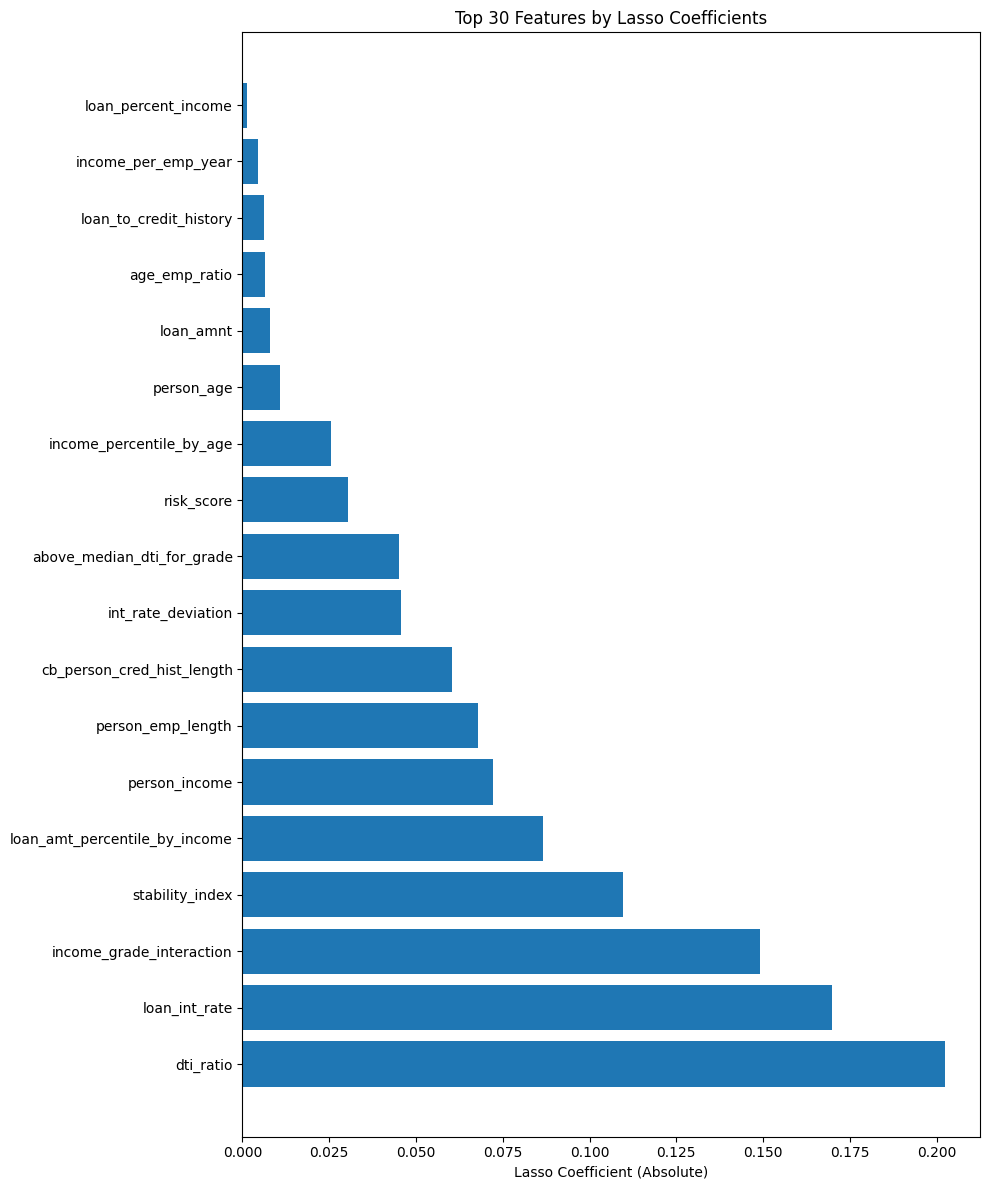


Top 20 Features by Lasso:
                          feature  coefficient
7                       dti_ratio        0.202
4                   loan_int_rate        0.170
12       income_grade_interaction        0.149
11                stability_index        0.110
15  loan_amt_percentile_by_income        0.087
1                   person_income        0.072
2               person_emp_length        0.068
6      cb_person_cred_hist_length        0.060
16             int_rate_deviation        0.046
17     above_median_dti_for_grade        0.045
13                     risk_score        0.030
14       income_percentile_by_age        0.025
0                      person_age        0.011
3                       loan_amnt        0.008
10                  age_emp_ratio        0.007
9          loan_to_credit_history        0.006
8             income_per_emp_year        0.004
5             loan_percent_income        0.001

Lasso tarafından elenen features (coef=0): 0 adet
[]


In [ ]:
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler

# Lasso CV ile optimal alpha bul
lasso_cv = LassoCV(cv=5, random_state=42, max_iter=10000)
lasso_cv.fit(X_scaled, y)

# Coefficient'ları al
lasso_coef = pd.DataFrame({
    'feature': X.columns,
    'coefficient': abs(lasso_cv.coef_)
}).sort_values('coefficient', ascending=False)

# Görselleştir
plt.figure(figsize=(10, 12))
plt.barh(lasso_coef['feature'][:30], lasso_coef['coefficient'][:30])
plt.xlabel('Lasso Coefficient (Absolute)')
plt.title('Top 30 Features by Lasso Coefficients')
plt.tight_layout()
plt.show()

print("\nTop 20 Features by Lasso:")
print(lasso_coef.head(20))

# Sıfır coefficient'lı feature'ları bul
zero_coef_features = lasso_coef[lasso_coef['coefficient'] == 0]['feature'].tolist()
print(f"\nLasso tarafından elenen features (coef=0): {len(zero_coef_features)} adet")
print(zero_coef_features)

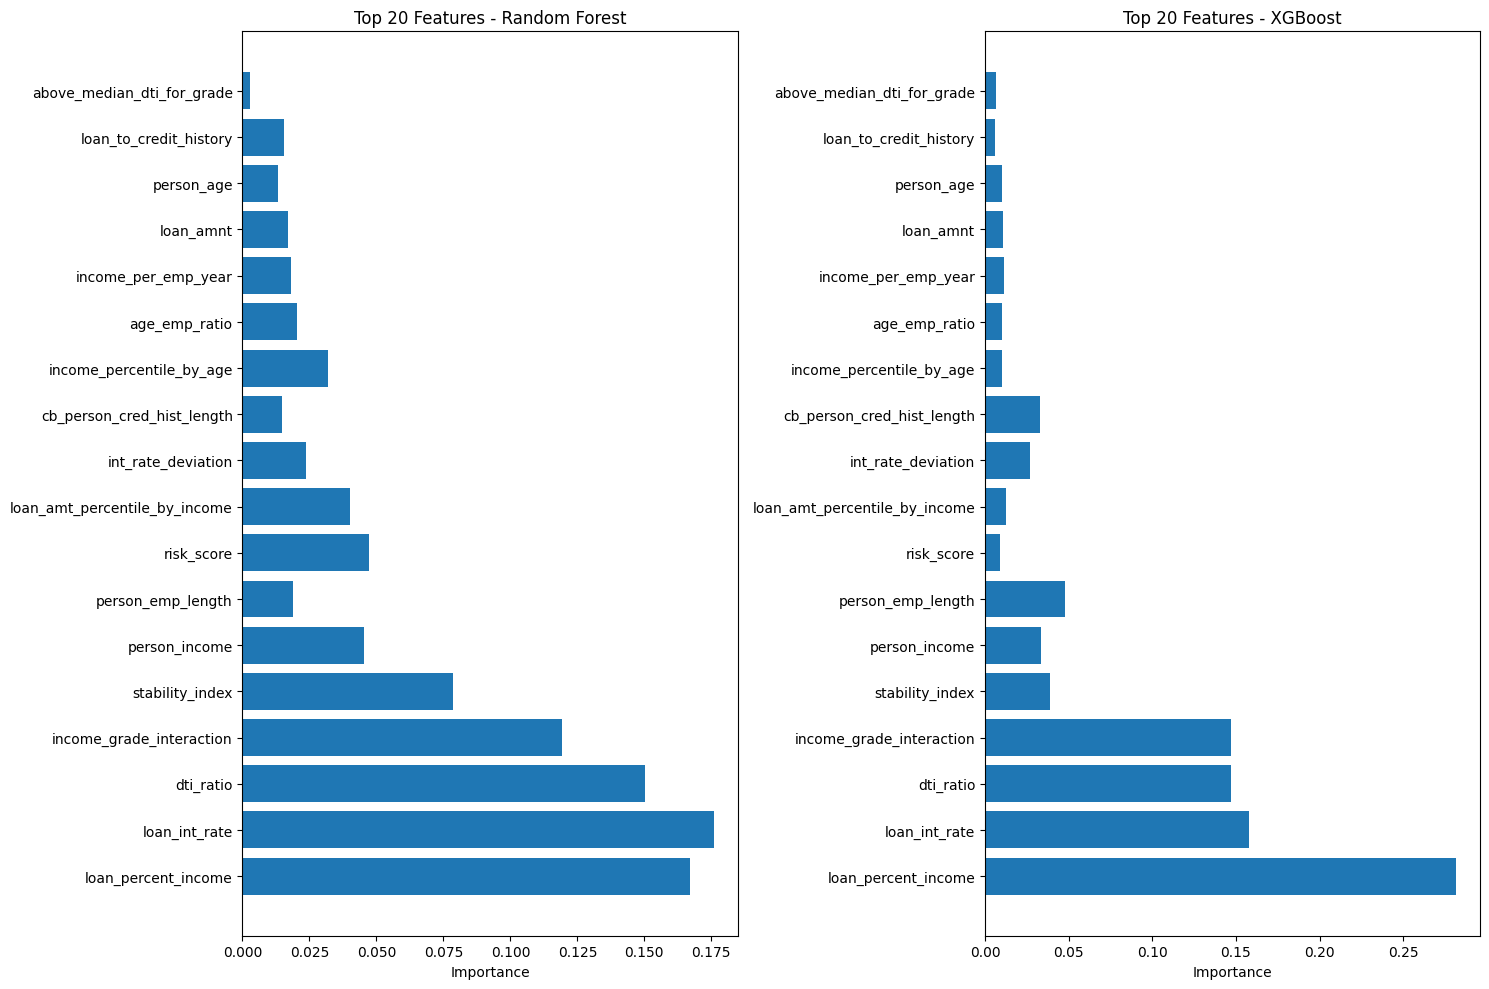


Top 20 Features by Tree-based Models:
                          feature  rf_importance  xgb_importance  avg_importance
5             loan_percent_income          0.167           0.282           0.225
4                   loan_int_rate          0.176           0.158           0.167
7                       dti_ratio          0.150           0.147           0.149
12       income_grade_interaction          0.119           0.147           0.133
11                stability_index          0.079           0.039           0.059
1                   person_income          0.045           0.034           0.039
2               person_emp_length          0.019           0.048           0.033
13                     risk_score          0.047           0.009           0.028
15  loan_amt_percentile_by_income          0.040           0.013           0.026
16             int_rate_deviation          0.024           0.027           0.025
6      cb_person_cred_hist_length          0.015           0.033      

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10)
rf.fit(X, y)

# XGBoost
xgb = XGBClassifier(n_estimators=100, random_state=42, max_depth=5,
                     learning_rate=0.1, eval_metric='logloss')
xgb.fit(X, y)

# Feature importance'ları birleştir
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'rf_importance': rf.feature_importances_,
    'xgb_importance': xgb.feature_importances_,
})

# Ortalama importance
feature_importance['avg_importance'] = (feature_importance['rf_importance'] +
                                        feature_importance['xgb_importance']) / 2
feature_importance = feature_importance.sort_values('avg_importance', ascending=False)

# Görselleştir
fig, axes = plt.subplots(1, 2, figsize=(15, 10))

# Random Forest
axes[0].barh(feature_importance['feature'][:20], feature_importance['rf_importance'][:20])
axes[0].set_xlabel('Importance')
axes[0].set_title('Top 20 Features - Random Forest')

# XGBoost
axes[1].barh(feature_importance['feature'][:20], feature_importance['xgb_importance'][:20])
axes[1].set_xlabel('Importance')
axes[1].set_title('Top 20 Features - XGBoost')

plt.tight_layout()
plt.show()

print("\nTop 20 Features by Tree-based Models:")
print(feature_importance.head(20))

# Düşük importance'lı features
low_importance_threshold = feature_importance['avg_importance'].quantile(0.25)
low_importance_features = feature_importance[
    feature_importance['avg_importance'] < low_importance_threshold
]['feature'].tolist()
print(f"\nDüşük importance features: {len(low_importance_features)} adet")

In [ ]:
# Tüm yöntemlerin sonuçlarını birleştir
feature_selection_summary = pd.DataFrame({
    'feature': X.columns
})

# Her yöntem için score ekle
feature_selection_summary = feature_selection_summary.merge(
    mi_df, on='feature', how='left')
feature_selection_summary = feature_selection_summary.merge(
    rfe_df[['feature', 'selected', 'ranking']], on='feature', how='left')
feature_selection_summary = feature_selection_summary.merge(
    lasso_coef, on='feature', how='left')
feature_selection_summary = feature_selection_summary.merge(
    feature_importance[['feature', 'avg_importance']], on='feature', how='left')

# Normalize et (0-1 arası)
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

feature_selection_summary['mi_score_norm'] = scaler.fit_transform(
    feature_selection_summary[['mi_score']])
feature_selection_summary['lasso_norm'] = scaler.fit_transform(
    feature_selection_summary[['coefficient']])
feature_selection_summary['tree_norm'] = scaler.fit_transform(
    feature_selection_summary[['avg_importance']])
feature_selection_summary['rfe_score'] = 1 - scaler.fit_transform(
    feature_selection_summary[['ranking']])

# Toplam skor hesapla
feature_selection_summary['total_score'] = (
    feature_selection_summary['mi_score_norm'] * 0.25 +
    feature_selection_summary['lasso_norm'] * 0.25 +
    feature_selection_summary['tree_norm'] * 0.25 +
    feature_selection_summary['rfe_score'] * 0.25
)

# Sırala
feature_selection_summary = feature_selection_summary.sort_values('total_score', ascending=False)

print("\n" + "="*60)
print("FEATURE SELECTION ÖZET")
print("="*60)
print("\nTop 25 Features (Tüm yöntemlerin ortalaması):")
print(feature_selection_summary[['feature', 'total_score']].head(25))

# Final öneriler
top_features = feature_selection_summary.head(25)['feature'].tolist()
drop_features = feature_selection_summary.tail(10)['feature'].tolist()

print(f"\n✅ Kesinlikle TUTULACAK Top 25 Feature:")
print(top_features)

print(f"\n❌ Düşünülebilecek DROP edilecek features (en düşük 10):")
print(drop_features)

# 0.88 korelasyonlu çiftler için karar
print("\n" + "="*60)
print("0.88 KORELASYON KARARI")
print("="*60)

high_corr_pairs = [
    ('person_age', 'age_emp_ratio'),
    ('person_income', 'income_percentile_by_age'),
    ('cb_person_cred_hist_length', 'age_emp_ratio')
]

for feat1, feat2 in high_corr_pairs:
    score1 = feature_selection_summary[feature_selection_summary['feature']==feat1]['total_score'].values[0]
    score2 = feature_selection_summary[feature_selection_summary['feature']==feat2]['total_score'].values[0]

    print(f"\n{feat1} (score: {score1:.3f}) vs {feat2} (score: {score2:.3f})")
    if abs(score1 - score2) > 0.1:
        drop_feat = feat1 if score1 < score2 else feat2
        print(f"  → DROP: {drop_feat}")
    else:
        print(f"  → İKİSİNİ DE TUT (farklı bilgi veriyorlar)")


FEATURE SELECTION ÖZET

Top 25 Features (Tüm yöntemlerin ortalaması):
                          feature  total_score
7                       dti_ratio        0.884
12       income_grade_interaction        0.830
4                   loan_int_rate        0.805
5             loan_percent_income        0.655
1                   person_income        0.562
15  loan_amt_percentile_by_income        0.517
11                stability_index        0.509
16             int_rate_deviation        0.486
14       income_percentile_by_age        0.469
13                     risk_score        0.460
2               person_emp_length        0.380
8             income_per_emp_year        0.366
6      cb_person_cred_hist_length        0.345
17     above_median_dti_for_grade        0.335
3                       loan_amnt        0.299
10                  age_emp_ratio        0.287
9          loan_to_credit_history        0.282
0                      person_age        0.271

✅ Kesinlikle TUTULACAK Top 25 Featu

In [ ]:
# Final feature seti ile model performansını test et
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier

# Orijinal vs Seçilmiş features
X_original = X
X_selected = X[top_features]

# Cross validation
rf = RandomForestClassifier(n_estimators=100, random_state=42)

scores_original = cross_val_score(rf, X_original, y, cv=5, scoring='roc_auc')
scores_selected = cross_val_score(rf, X_selected, y, cv=5, scoring='roc_auc')

print("\n" + "="*60)
print("PERFORMANS KARŞILAŞTIRMA")
print("="*60)
print(f"Orijinal Features ({X_original.shape[1]} features):")
print(f"  AUC: {scores_original.mean():.4f} (+/- {scores_original.std():.4f})")
print(f"\nSeçilmiş Features ({X_selected.shape[1]} features):")
print(f"  AUC: {scores_selected.mean():.4f} (+/- {scores_selected.std():.4f})")
print(f"\nİyileşme: {(scores_selected.mean() - scores_original.mean())*100:.2f}%")


PERFORMANS KARŞILAŞTIRMA
Orijinal Features (18 features):
  AUC: 0.9244 (+/- 0.0029)

Seçilmiş Features (18 features):
  AUC: 0.9240 (+/- 0.0023)

İyileşme: -0.04%


In [ ]:
dff.head()

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status,dti_ratio,income_per_emp_year,loan_to_credit_history,age_emp_ratio,stability_index,income_grade_interaction,risk_score,risk_category,age_group,income_bracket,loan_size_category,employment_stability,credit_maturity,risk_score_category,dti_category,payment_burden,interest_rate_category,stability_category,income_percentile_by_age,loan_amt_percentile_by_income,int_rate_deviation,above_median_dti_for_grade
0,0.000,37.000,35000,RENT,0,EDUCATION,B,6000,11.490,0.170,N,14,0,0.171,35000.000,400.000,37.000,5.400,17500.000,30,Low Risk,mature,very_low,small,none,established,medium,fair,moderate,standard,moderate,0.114,0.515,0.455,1
1,1.000,22.000,56000,OWN,6,MEDICAL,C,4000,13.350,0.070,N,2,0,0.071,8000.000,1333.333,3.143,6.400,18666.667,25,Low Risk,very_young,low,mini,stable,very_new,low,excellent,light,subprime,moderate,0.577,0.168,-0.160,0
2,2.000,29.000,28800,OWN,8,PERSONAL,A,6000,8.900,0.210,N,10,0,0.208,3200.000,545.455,3.222,9.400,28800.000,20,Very Low Risk,middle_young,very_low,small,established,established,very_low,fair,moderate,near_prime,very_stable,0.035,0.515,1.565,1
3,3.000,30.000,70000,RENT,14,VENTURE,B,12000,11.110,0.170,N,5,0,0.171,4666.667,2000.000,2.000,6.900,35000.000,15,Very Low Risk,middle_young,medium,medium,veteran,building,very_low,fair,moderate,standard,stable,0.633,0.705,0.075,1
4,4.000,22.000,60000,RENT,2,MEDICAL,A,6000,6.920,0.100,N,3,0,0.100,20000.000,1500.000,7.333,2.700,60000.000,20,Very Low Risk,very_young,medium,small,new,very_new,very_low,good,very_light,prime,very_unstable,0.640,0.274,-0.415,0


In [ ]:
dff.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58645 entries, 0 to 58644
Data columns (total 35 columns):
 #   Column                         Non-Null Count  Dtype   
---  ------                         --------------  -----   
 0   id                             58645 non-null  float64 
 1   person_age                     58645 non-null  float64 
 2   person_income                  58645 non-null  int64   
 3   person_home_ownership          58645 non-null  category
 4   person_emp_length              58645 non-null  int64   
 5   loan_intent                    58645 non-null  category
 6   loan_grade                     58645 non-null  category
 7   loan_amnt                      58645 non-null  int64   
 8   loan_int_rate                  58645 non-null  float64 
 9   loan_percent_income            58645 non-null  float64 
 10  cb_person_default_on_file      58645 non-null  category
 11  cb_person_cred_hist_length     58645 non-null  int64   
 12  loan_status                    5

In [ ]:
dff["risk_category"] = dff["risk_category"].astype("category")


In [ ]:
dff.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58645 entries, 0 to 58644
Data columns (total 35 columns):
 #   Column                         Non-Null Count  Dtype   
---  ------                         --------------  -----   
 0   id                             58645 non-null  float64 
 1   person_age                     58645 non-null  float64 
 2   person_income                  58645 non-null  int64   
 3   person_home_ownership          58645 non-null  category
 4   person_emp_length              58645 non-null  int64   
 5   loan_intent                    58645 non-null  category
 6   loan_grade                     58645 non-null  category
 7   loan_amnt                      58645 non-null  int64   
 8   loan_int_rate                  58645 non-null  float64 
 9   loan_percent_income            58645 non-null  float64 
 10  cb_person_default_on_file      58645 non-null  category
 11  cb_person_cred_hist_length     58645 non-null  int64   
 12  loan_status                    5

In [ ]:
print(dff["risk_category"].dtypes)
print(dff["risk_category"].value_counts())

category
risk_category
Very Low Risk     23119
Low Risk          22237
Medium Risk        8473
High Risk          4177
Very High Risk      639
Name: count, dtype: int64


In [ ]:
num_cols

['id',
 'person_age',
 'person_income',
 'person_emp_length',
 'loan_amnt',
 'loan_int_rate',
 'loan_percent_income',
 'cb_person_cred_hist_length',
 'dti_ratio',
 'income_per_emp_year',
 'loan_to_credit_history',
 'age_emp_ratio',
 'stability_index',
 'income_grade_interaction',
 'risk_score',
 'income_percentile_by_age',
 'loan_amt_percentile_by_income',
 'int_rate_deviation',
 'loan_status',
 'above_median_dti_for_grade']

In [ ]:
# 1) Sadece 'category' tipindeki sütunları encode et
cats_to_encode = dff.select_dtypes(include=["category"]).columns.tolist()
print("Encode edilecek kategorikler:", cats_to_encode)

Encode edilecek kategorikler: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file', 'risk_category', 'age_group', 'income_bracket', 'loan_size_category', 'employment_stability', 'credit_maturity', 'risk_score_category', 'dti_category', 'payment_burden', 'interest_rate_category', 'stability_category']


In [ ]:
dataframe = pd.get_dummies(dff, columns=cats_to_encode, drop_first=True)

In [ ]:
print(dataframe.select_dtypes(include=["object", "category"]).columns.tolist())
print(dataframe.dtypes.value_counts())

[]
bool       66
float64    13
int64       7
Name: count, dtype: int64


In [ ]:
dataframe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58645 entries, 0 to 58644
Data columns (total 86 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   id                                     58645 non-null  float64
 1   person_age                             58645 non-null  float64
 2   person_income                          58645 non-null  int64  
 3   person_emp_length                      58645 non-null  int64  
 4   loan_amnt                              58645 non-null  int64  
 5   loan_int_rate                          58645 non-null  float64
 6   loan_percent_income                    58645 non-null  float64
 7   cb_person_cred_hist_length             58645 non-null  int64  
 8   loan_status                            58645 non-null  int64  
 9   dti_ratio                              58645 non-null  float64
 10  income_per_emp_year                    58645 non-null  float64
 11  lo

In [ ]:
from sklearn.model_selection import train_test_split

y = dataframe["loan_status"]
X = dataframe.drop(["loan_status", "id"], axis=1)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=17
)

In [ ]:
print("X shape:", X.shape)
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

X shape: (58645, 84)
Train shape: (41051, 84)
Test shape: (17594, 84)


In [ ]:
!pip install catboost

from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, classification_report


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, precision_recall_curve, auc,
    precision_recall_fscore_support
)

# ---------------- A) ROC/PR + hedef recall'da değerlendirme (return YOK) ----------------
def evaluate_with_threshold_and_curves(model, X_test, y_test,
                                       target_recall=0.80,
                                       model_name="Model",
                                       positive_class=1):
    proba = model.predict_proba(X_test)[:, positive_class]

    # ROC & PR
    roc_auc = roc_auc_score(y_test, proba)
    fpr, tpr, _ = roc_curve(y_test, proba)
    prec, rec, thr = precision_recall_curve(y_test, proba)
    pr_auc = auc(rec, prec)

    # hedef recall ≥ target içinde precision'u maks eden threshold
    prec_thr, rec_thr = prec[:-1], rec[:-1]     # thr ile hizala
    ok = np.where(rec_thr >= target_recall)[0]
    if len(ok) == 0:
        idx = int(np.argmax(rec_thr))           # ulaşılamıyorsa max recall
    else:
        idx = int(ok[np.argmax(prec_thr[ok])])
    chosen_thr = float(thr[idx])

    y_pred = (proba >= chosen_thr).astype(int)
    cm = confusion_matrix(y_test, y_pred)

    print(f"\n=== {model_name} | Target Recall Evaluation ===")
    print(f"Target recall : {target_recall:.2f}")
    print(f"Chosen thr    : {chosen_thr:.4f}")
    print(f"Precision@thr : {prec_thr[idx]:.3f}")
    print(f"Recall@thr    : {rec_thr[idx]:.3f}")
    print(f"ROC AUC       : {roc_auc:.4f}")
    print(f"PR  AUC       : {pr_auc:.4f}\n")
    print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
    print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
    print(f"Precision: {precision_score(y_test, y_pred):.4f}")
    print(f"F1       : {f1_score(y_test, y_pred):.4f}\n")
    print("Confusion matrix @chosen thr:\n", cm)
    print("\nClassification report:\n", classification_report(y_test, y_pred, digits=4))

    # ROC & PR grafikleri
    plt.figure(figsize=(12,5))
    plt.subplot(1,2,1)
    plt.plot(fpr, tpr, label=f"AUC={roc_auc:.3f}")
    plt.plot([0,1],[0,1],"k--",lw=1)
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve - {model_name}"); plt.legend()

    plt.subplot(1,2,2)
    plt.plot(rec, prec, label=f"AUC={pr_auc:.3f}")
    plt.xlabel("Recall"); plt.ylabel("Precision")
    plt.title(f"Precision-Recall Curve - {model_name}"); plt.legend()
    plt.tight_layout(); plt.show()


# ------------- B) Precision / Recall / F1 vs threshold grafiği (return YOK) -------------
def threshold_tuning_plot(model, X_test, y_test,
                          thresholds=None,
                          choose_by="recall>=target",  # "recall>=target" | "max_f1"
                          target_recall=0.80,
                          model_name="Model",
                          positive_class=1):
    proba = model.predict_proba(X_test)[:, positive_class]

    if thresholds is None:
        p, r, thr = precision_recall_curve(y_test, proba)
        lo = max(0.01, np.quantile(thr, 0.05)) if len(thr) else 0.01
        hi = min(0.99, np.quantile(thr, 0.95)) if len(thr) else 0.99
        thresholds = np.linspace(lo, hi, 100)

    P, R, F1 = [], [], []
    for t in thresholds:
        y_hat = (proba >= t).astype(int)
        P.append(precision_score(y_test, y_hat, zero_division=0))
        R.append(recall_score(y_test, y_hat))
        F1.append(f1_score(y_test, y_hat))
    P, R, F1 = np.array(P), np.array(R), np.array(F1)

    if choose_by == "max_f1":
        idx = int(np.nanargmax(F1))
    else:
        ok = np.where(R >= target_recall)[0]
        idx = int(np.argmax(R)) if len(ok)==0 else int(ok[np.argmax(P[ok])])
    chosen_thr = float(thresholds[idx])

    plt.figure(figsize=(8,5))
    plt.plot(thresholds, P, label="Precision")
    plt.plot(thresholds, R, label="Recall")
    plt.plot(thresholds, F1, label="F1")
    plt.axvline(chosen_thr, color="k", linestyle="--", alpha=0.7,
                label=f"chosen thr={chosen_thr:.2f}")
    rule = "max F1" if choose_by=="max_f1" else f"target recall≥{target_recall:.2f}"
    plt.title(f"Threshold Tuning ({model_name}, {rule})")
    plt.xlabel("Threshold"); plt.ylabel("Score"); plt.legend()
    plt.tight_layout(); plt.show()

    y_best = (proba >= chosen_thr).astype(int)
    print("Confusion matrix @chosen thr:\n", confusion_matrix(y_test, y_best))


# --------- C) Hedef recall'ın etrafındaki eşi̇kleri tablo halinde göster (return YOK) ---------
def thresholds_around_target_recall(model, X_test, y_test,
                                    target_recall=0.80,
                                    window=0.03,            # ± recall penceresi
                                    step=0.005,             # threshold tarama adımı
                                    start=0.05, stop=0.95,
                                    positive_class=1):
    """
    Recall'ı target_recall ± window aralığında kalan threshold'lar için
    metrikleri tablo olarak yazdırır (return yok).
    """
    proba = model.predict_proba(X_test)[:, positive_class]
    ths = np.round(np.arange(start, stop + 1e-9, step), 4)

    rows = []
    for t in ths:
        y_hat = (proba >= t).astype(int)
        prec, rec, f1, _ = precision_recall_fscore_support(
            y_test, y_hat, average="binary", zero_division=0
        )
        if abs(rec - target_recall) <= window:
            acc = accuracy_score(y_test, y_hat)
            tn, fp, fn, tp = confusion_matrix(y_test, y_hat).ravel()
            rows.append({
                "threshold": t, "precision": prec, "recall": rec, "f1": f1,
                "accuracy": acc, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                "recall_gap": abs(rec - target_recall)
            })

    if not rows:
        print("⚠️ Belirlenen pencerede (±{:.2f}) recall'a yakın threshold bulunamadı.".format(window))
        return

    df_near = pd.DataFrame(rows).sort_values(
        ["recall_gap", "precision"], ascending=[True, False]
    )
    print(f"\nThreshold candidates around target recall={target_recall:.2f} (±{window:.2f})")
    print(df_near.head(20).to_string(index=False))


# ------------------- D) Hepsini tek akışta çalıştır (return YOK) -------------------
def full_threshold_workflow(model, X_test, y_test,
                            model_name="Model",
                            target_recall=0.80,
                            around_window=0.03):
    evaluate_with_threshold_and_curves(
        model, X_test, y_test, target_recall=target_recall, model_name=model_name
    )
    threshold_tuning_plot(
        model, X_test, y_test,
        choose_by="recall>=target",
        target_recall=target_recall,
        model_name=model_name
    )
    thresholds_around_target_recall(
        model, X_test, y_test,
        target_recall=target_recall,
        window=around_window
    )


In [ ]:
catboost_model = CatBoostClassifier(verbose=False, random_state=17).fit(X_train, y_train)

# Tahmin yap
y_pred = catboost_model.predict(X_test)

# Değerlendirme metrikleri
print(f"Accuracy : {round(accuracy_score(y_test, y_pred), 4)}")
print(f"Recall   : {round(recall_score(y_test, y_pred), 4)}")
print(f"Precision: {round(precision_score(y_test, y_pred), 4)}")
print(f"F1       : {round(f1_score(y_test, y_pred), 4)}")

# Detaylı rapor
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Accuracy : 0.9517
Recall   : 0.7309
Precision: 0.9123
F1       : 0.8116

Classification Report:

              precision    recall  f1-score   support

           0       0.96      0.99      0.97     15089
           1       0.91      0.73      0.81      2505

    accuracy                           0.95     17594
   macro avg       0.93      0.86      0.89     17594
weighted avg       0.95      0.95      0.95     17594



In [ ]:
from sklearn.model_selection import GridSearchCV
from catboost import CatBoostClassifier

# Model
cat = CatBoostClassifier(verbose=0, random_state=17)

# Parametre grid (küçük bir aralık deneme)
param_grid = {
    "depth": [4, 6, 8],
    "learning_rate": [0.01, 0.05, 0.1],
    "l2_leaf_reg": [1, 3, 5],
    "iterations": [300, 500]
}

# GridSearch
grid = GridSearchCV(
    estimator=cat,
    param_grid=param_grid,
    scoring="recall",   # recall'a optimize et
    cv=3,
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best recall:", grid.best_score_)

# En iyi modeli al
cat_best = grid.best_estimator_

# Test performansı
y_pred = cat_best.predict(X_test)
print("\n=== Test Sonuçları ===")
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("F1       :", f1_score(y_test, y_pred))


Best params: {'depth': 8, 'iterations': 500, 'l2_leaf_reg': 5, 'learning_rate': 0.1}
Best recall: 0.7266044750304567

=== Test Sonuçları ===
Accuracy : 0.9508355121063999
Recall   : 0.7253493013972055
Precision: 0.9112337011033099
F1       : 0.8077350522338297


In [ ]:
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, classification_report

# En iyi parametrelerle model
best_params = {
    "depth": 8,
    "iterations": 500,
    "l2_leaf_reg": 5,
    "learning_rate": 0.1,
    "random_state": 17,
    "verbose": False
}

catboost_best = CatBoostClassifier(**best_params).fit(X_train, y_train)

# Tahmin
y_pred = catboost_best.predict(X_test)

# Değerlendirme metrikleri
print("=== CatBoost (Best Params) Results ===")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"F1       : {f1_score(y_test, y_pred):.4f}")

# Detaylı rapor
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, digits=4))


=== CatBoost (Best Params) Results ===
Accuracy : 0.9508
Recall   : 0.7253
Precision: 0.9112
F1       : 0.8077

Classification Report:

              precision    recall  f1-score   support

           0     0.9559    0.9883    0.9718     15089
           1     0.9112    0.7253    0.8077      2505

    accuracy                         0.9508     17594
   macro avg     0.9336    0.8568    0.8898     17594
weighted avg     0.9495    0.9508    0.9485     17594



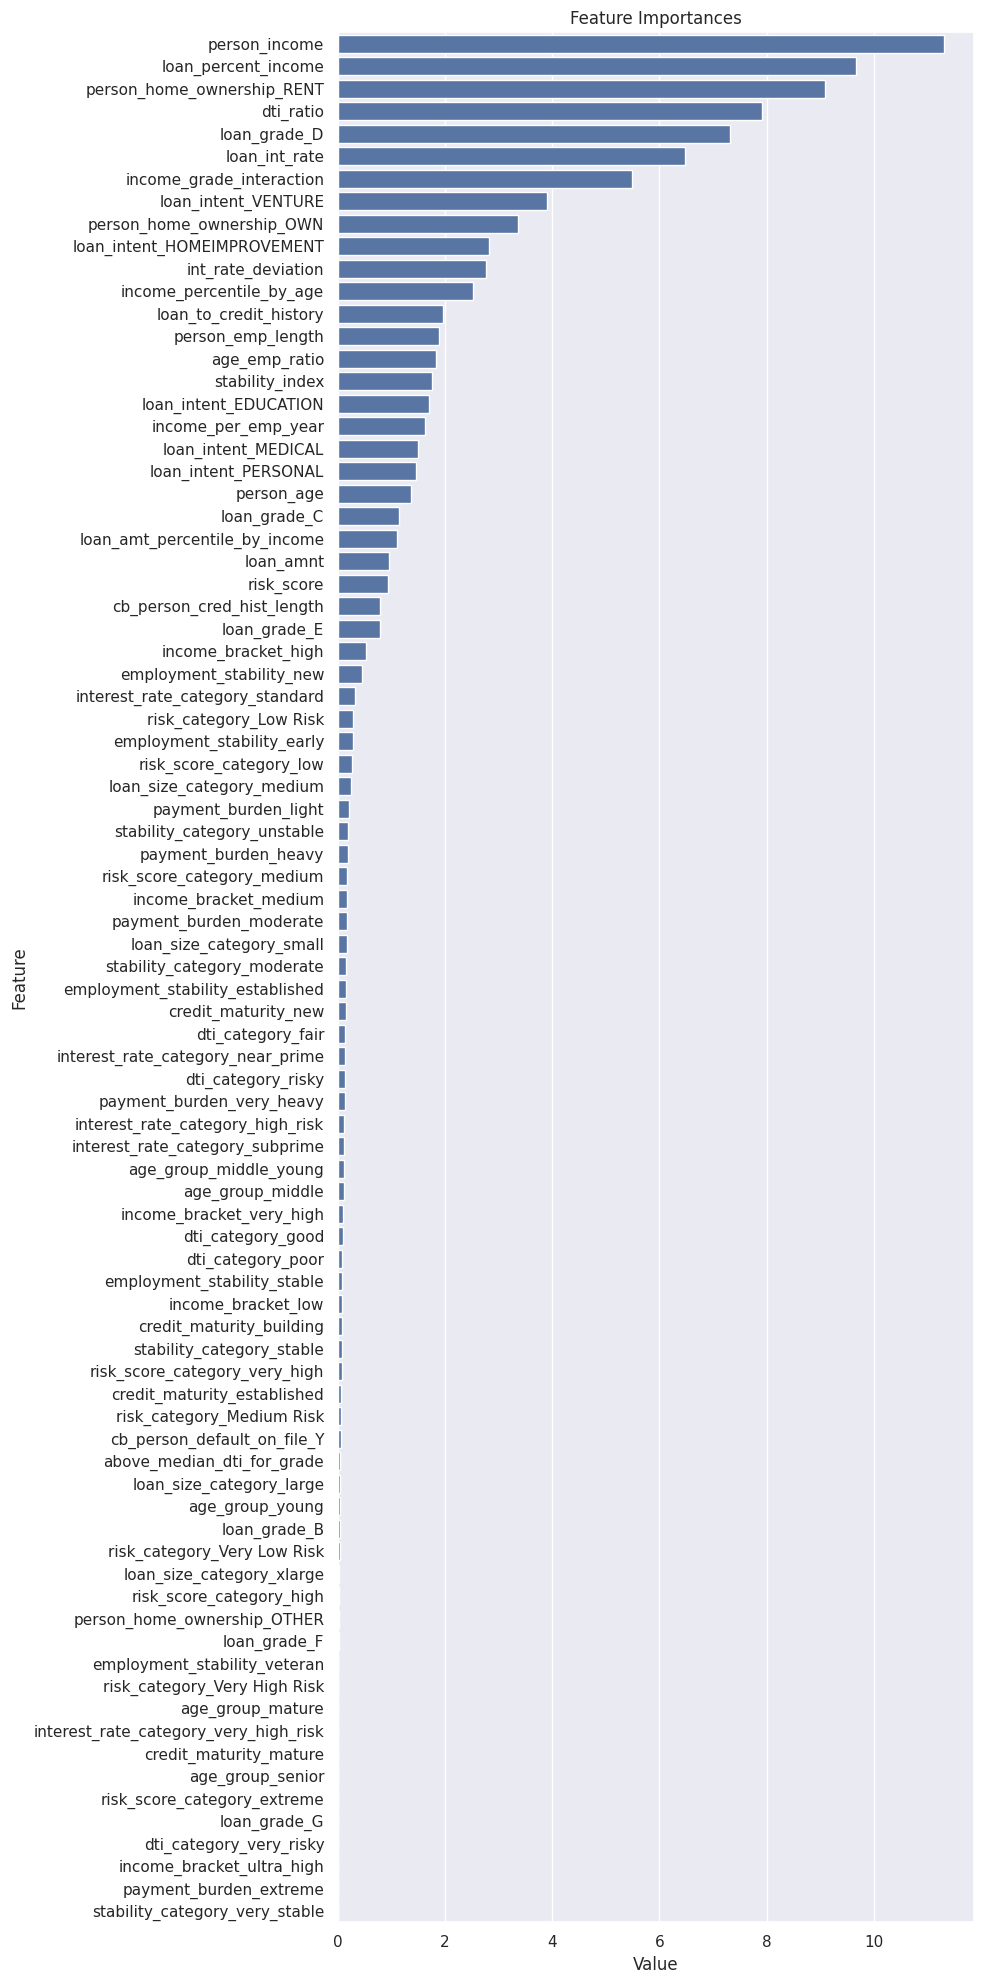

In [ ]:
def plot_importance(model, features, num=None):
    if num is None:
        num = len(features.columns)

    feature_imp = pd.DataFrame({
        'Value': model.feature_importances_,
        'Feature': features.columns
    })

    plt.figure(figsize=(10, 20))
    sns.set(font_scale=1)
    sns.barplot(x="Value", y="Feature",
                data=feature_imp.sort_values(by="Value", ascending=False)[0:num])
    plt.title('Feature Importances')
    plt.tight_layout()
    plt.show()

# Kullanım
plot_importance(catboost_model, X)


=== CatBoost | Target Recall Evaluation ===
Target recall : 0.80
Chosen thr    : 0.2131
Precision@thr : 0.784
Recall@thr    : 0.800
ROC AUC       : 0.9534
PR  AUC       : 0.8697

Accuracy : 0.9401
Recall   : 0.8004
Precision: 0.7835
F1       : 0.7919

Confusion matrix @chosen thr:
 [[14535   554]
 [  500  2005]]

Classification report:
               precision    recall  f1-score   support

           0     0.9667    0.9633    0.9650     15089
           1     0.7835    0.8004    0.7919      2505

    accuracy                         0.9401     17594
   macro avg     0.8751    0.8818    0.8784     17594
weighted avg     0.9407    0.9401    0.9404     17594



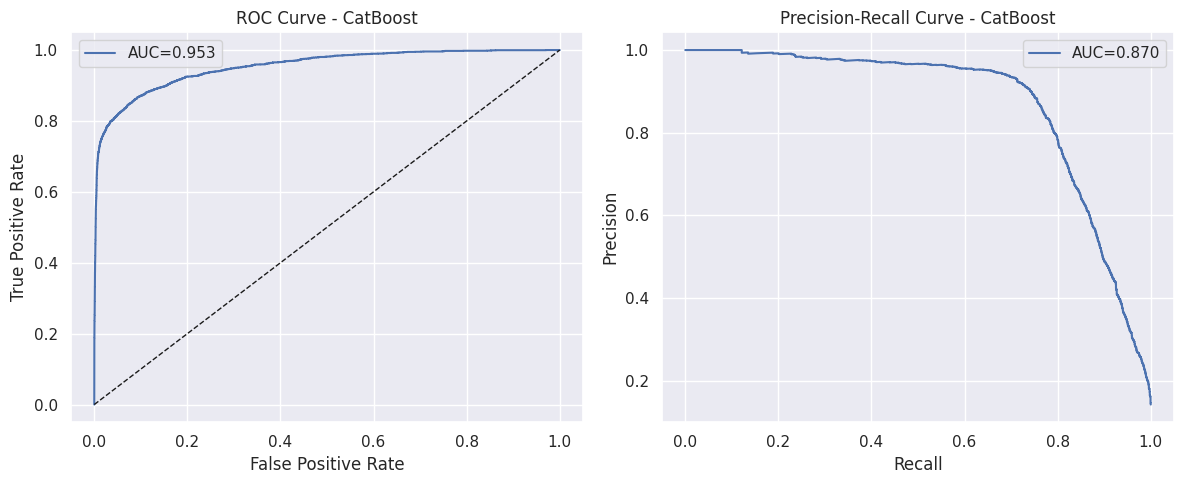

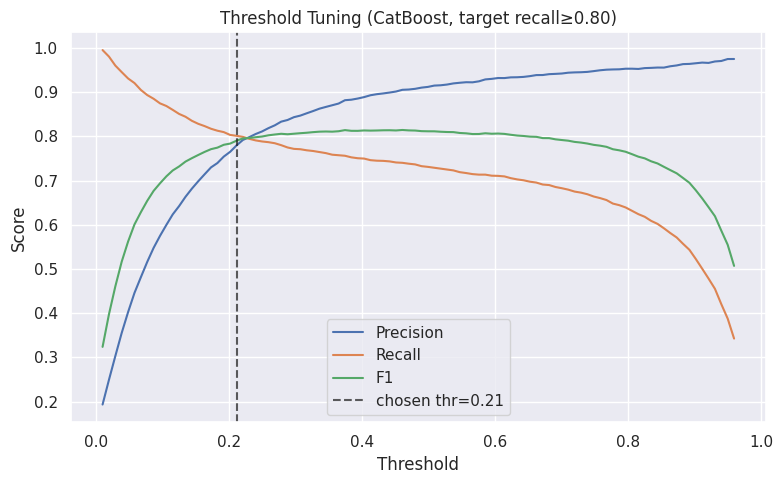

Confusion matrix @chosen thr:
 [[14521   568]
 [  498  2007]]

Threshold candidates around target recall=0.80 (±0.03)
 threshold  precision  recall    f1  accuracy   TP  FP  FN    TN  recall_gap
     0.215      0.784   0.799 0.792     0.940 2002 550 503 14539       0.001
     0.210      0.777   0.801 0.789     0.939 2007 577 498 14512       0.001
     0.220      0.792   0.799 0.795     0.941 2001 527 504 14562       0.001
     0.205      0.770   0.802 0.786     0.938 2009 601 496 14488       0.002
     0.225      0.796   0.797 0.797     0.942 1996 510 509 14579       0.003
     0.200      0.763   0.805 0.784     0.937 2017 626 488 14463       0.005
     0.230      0.798   0.794 0.796     0.942 1990 504 515 14585       0.006
     0.235      0.800   0.792 0.796     0.942 1985 495 520 14594       0.008
     0.195      0.758   0.808 0.782     0.936 2025 646 480 14443       0.008
     0.240      0.805   0.791 0.798     0.943 1981 479 524 14610       0.009
     0.190      0.752   0.810 0.780

In [ ]:
# CatBoost için
full_threshold_workflow(catboost_model, X_test, y_test,
                        model_name="CatBoost",
                        target_recall=0.80, around_window=0.03)


In [ ]:
from sklearn.metrics import precision_recall_fscore_support
import numpy as np
import matplotlib.pyplot as plt

def threshold_tuning_for_class(y_true, y_proba, target_class=1, target_recall=0.80):
    thresholds = np.linspace(0.0, 1.0, 100)
    precisions, recalls, f1s = [], [], []

    for thr in thresholds:
        y_hat = (y_proba >= thr).astype(int)
        prec, rec, f1, _ = precision_recall_fscore_support(
            y_true, y_hat, average="binary", zero_division=0, pos_label=target_class
        )
        precisions.append(prec)
        recalls.append(rec)
        f1s.append(f1)

    # Grafik
    plt.figure(figsize=(8,6))
    plt.plot(thresholds, precisions, label="Precision")
    plt.plot(thresholds, recalls, label="Recall")
    plt.plot(thresholds, f1s, label="F1")
    plt.axhline(target_recall, color="red", linestyle="--", label=f"Target Recall={target_recall}")
    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.title(f"Threshold Tuning (class={target_class})")
    plt.legend()
    plt.show()



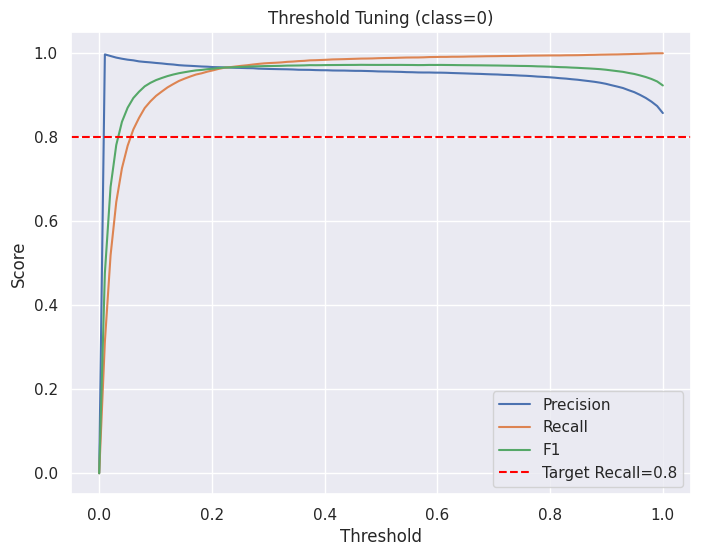

In [ ]:
# Proba al (pozitif sınıf=1 için, ama 0 sınıfına göre metrik hesaplayacağız)
proba = catboost_model.predict_proba(X_test)[:, 1]

# class=0 için metrik eğrileri
threshold_tuning_for_class(y_test, proba, target_class=0, target_recall=0.80)


In [ ]:
from imblearn.over_sampling import SMOTE
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, classification_report

# 1) Sadece TRAIN üzerinde SMOTE
sm = SMOTE(random_state=17, k_neighbors=5)
X_train_sm, y_train_sm = sm.fit_resample(X_train, y_train)

# 2) CatBoost’u SMOTE’lu train ile eğit
catboost_sm = CatBoostClassifier(verbose=False, random_state=17)
catboost_sm.fit(X_train_sm, y_train_sm)
# SMOTE sonrası boyut
print("Original X_train shape :", X_train.shape)
print("SMOTE    X_train shape :", X_train_sm.shape)

# Sınıf dağılımları
print("\nOriginal y_train distribution:\n", y_train.value_counts())
print("\nSMOTE y_train distribution:\n", y_train_sm.value_counts())

# 3) Test’te değerlendirme (test set’e SMOTE yok!)
y_pred = catboost_sm.predict(X_test)
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"F1       : {f1_score(y_test, y_pred):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Original X_train shape : (41051, 84)
SMOTE    X_train shape : (70412, 84)

Original y_train distribution:
 loan_status
0    35206
1     5845
Name: count, dtype: int64

SMOTE y_train distribution:
 loan_status
0    35206
1    35206
Name: count, dtype: int64
Accuracy : 0.9508
Recall   : 0.7301
Precision: 0.9059
F1       : 0.8086

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.99      0.97     15089
           1       0.91      0.73      0.81      2505

    accuracy                           0.95     17594
   macro avg       0.93      0.86      0.89     17594
weighted avg       0.95      0.95      0.95     17594




=== catboost_sm | Target Recall Evaluation ===
Target recall : 0.80
Chosen thr    : 0.2131
Precision@thr : 0.784
Recall@thr    : 0.800
ROC AUC       : 0.9534
PR  AUC       : 0.8697

Accuracy : 0.9401
Recall   : 0.8004
Precision: 0.7835
F1       : 0.7919

Confusion matrix @chosen thr:
 [[14535   554]
 [  500  2005]]

Classification report:
               precision    recall  f1-score   support

           0     0.9667    0.9633    0.9650     15089
           1     0.7835    0.8004    0.7919      2505

    accuracy                         0.9401     17594
   macro avg     0.8751    0.8818    0.8784     17594
weighted avg     0.9407    0.9401    0.9404     17594



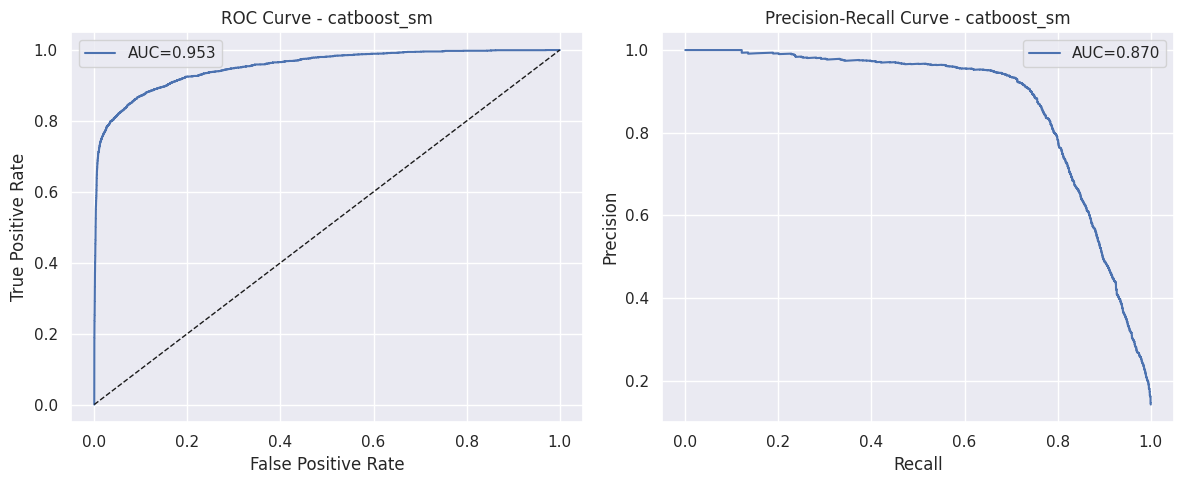

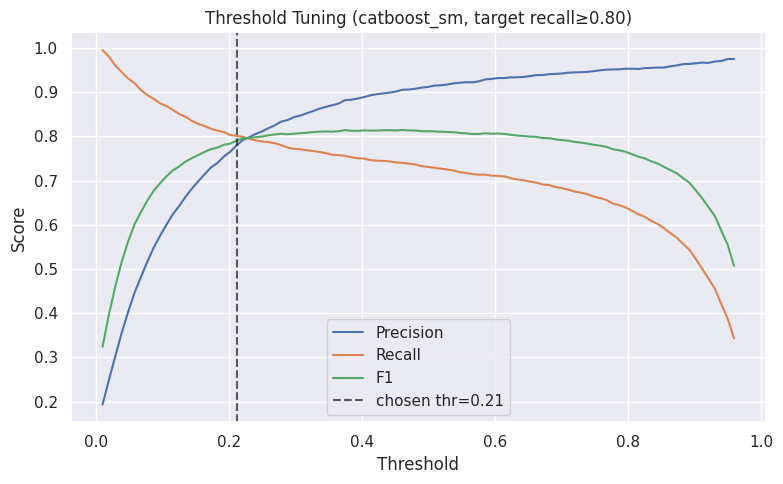

Confusion matrix @chosen thr:
 [[14521   568]
 [  498  2007]]

Threshold candidates around target recall=0.80 (±0.03)
 threshold  precision  recall    f1  accuracy   TP  FP  FN    TN  recall_gap
     0.213      0.783   0.800 0.792     0.940 2004 554 501 14535       0.000
     0.213      0.784   0.800 0.792     0.940 2005 554 500 14535       0.000
     0.214      0.783   0.800 0.791     0.940 2003 554 502 14535       0.000
     0.213      0.783   0.800 0.792     0.940 2005 555 500 14534       0.000
     0.213      0.783   0.800 0.792     0.940 2005 556 500 14533       0.000
     0.213      0.783   0.800 0.791     0.940 2005 557 500 14532       0.000
     0.213      0.782   0.800 0.791     0.940 2005 558 500 14531       0.000
     0.212      0.782   0.800 0.791     0.940 2005 559 500 14530       0.000
     0.212      0.782   0.800 0.791     0.940 2005 560 500 14529       0.000
     0.212      0.782   0.801 0.791     0.940 2006 560 499 14529       0.001
     0.212      0.781   0.801 0.791

In [ ]:
full_threshold_workflow(catboost_model, X_test, y_test,
                        model_name="catboost_sm",
                        target_recall=0.80, around_window=0.03)

In [ ]:
# sınıf dağılımına göre ağırlık verelim
from collections import Counter
cnt = Counter(y_train)
w = cnt[0] / cnt[1]

catboost_w = CatBoostClassifier(
    depth=8, iterations=500, l2_leaf_reg=5, learning_rate=0.1,
    class_weights=[1.0, w],  # pozitif sınıfa ağırlık
    verbose=False, random_state=17
)
catboost_w.fit(X_train, y_train)


In [ ]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, classification_report, confusion_matrix

# Tahmin yap
y_pred_w = catboost_w.predict(X_test)

# Değerlendirme metrikleri
print("=== CatBoost (Class Weights) Results ===")
print(f"Accuracy : {round(accuracy_score(y_test, y_pred_w), 4)}")
print(f"Recall   : {round(recall_score(y_test, y_pred_w), 4)}")
print(f"Precision: {round(precision_score(y_test, y_pred_w), 4)}")
print(f"F1       : {round(f1_score(y_test, y_pred_w), 4)}")

# Confusion matrix
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_w))

# Detaylı rapor
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_w, digits=4))


=== CatBoost (Class Weights) Results ===
Accuracy : 0.937
Recall   : 0.7932
Precision: 0.7708
F1       : 0.7818

Confusion matrix:
[[14498   591]
 [  518  1987]]

Classification Report:

              precision    recall  f1-score   support

           0     0.9655    0.9608    0.9632     15089
           1     0.7708    0.7932    0.7818      2505

    accuracy                         0.9370     17594
   macro avg     0.8681    0.8770    0.8725     17594
weighted avg     0.9378    0.9370    0.9373     17594



In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, classification_report

# Modeli oluştur ve eğit
rf_model = RandomForestClassifier(
    n_estimators=200,      # ağaç sayısı
    max_depth=None,        # ağaç derinliği (None = sınırsız)
    random_state=17,
    n_jobs=-1              # paralel çalıştırma
).fit(X_train, y_train)

# Tahmin yap
y_pred_rf = rf_model.predict(X_test)

# Değerlendirme metrikleri
print("=== Random Forest Results ===")
print(f"Accuracy : {round(accuracy_score(y_test, y_pred_rf), 4)}")
print(f"Recall   : {round(recall_score(y_test, y_pred_rf), 4)}")
print(f"Precision: {round(precision_score(y_test, y_pred_rf), 4)}")
print(f"F1       : {round(f1_score(y_test, y_pred_rf), 4)}")

# Detaylı rapor
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_rf))


=== Random Forest Results ===
Accuracy : 0.9441
Recall   : 0.679
Precision: 0.9043
F1       : 0.7756

Classification Report:

              precision    recall  f1-score   support

           0       0.95      0.99      0.97     15089
           1       0.90      0.68      0.78      2505

    accuracy                           0.94     17594
   macro avg       0.93      0.83      0.87     17594
weighted avg       0.94      0.94      0.94     17594




=== RandomForest | Target Recall Evaluation ===
Target recall : 0.80
Chosen thr    : 0.2000
Precision@thr : 0.625
Recall@thr    : 0.801
ROC AUC       : 0.9321
PR  AUC       : 0.8289

Accuracy : 0.9033
Recall   : 0.8012
Precision: 0.6250
F1       : 0.7022

Confusion matrix @chosen thr:
 [[13885  1204]
 [  498  2007]]

Classification report:
               precision    recall  f1-score   support

           0     0.9654    0.9202    0.9423     15089
           1     0.6250    0.8012    0.7022      2505

    accuracy                         0.9033     17594
   macro avg     0.7952    0.8607    0.8222     17594
weighted avg     0.9169    0.9033    0.9081     17594



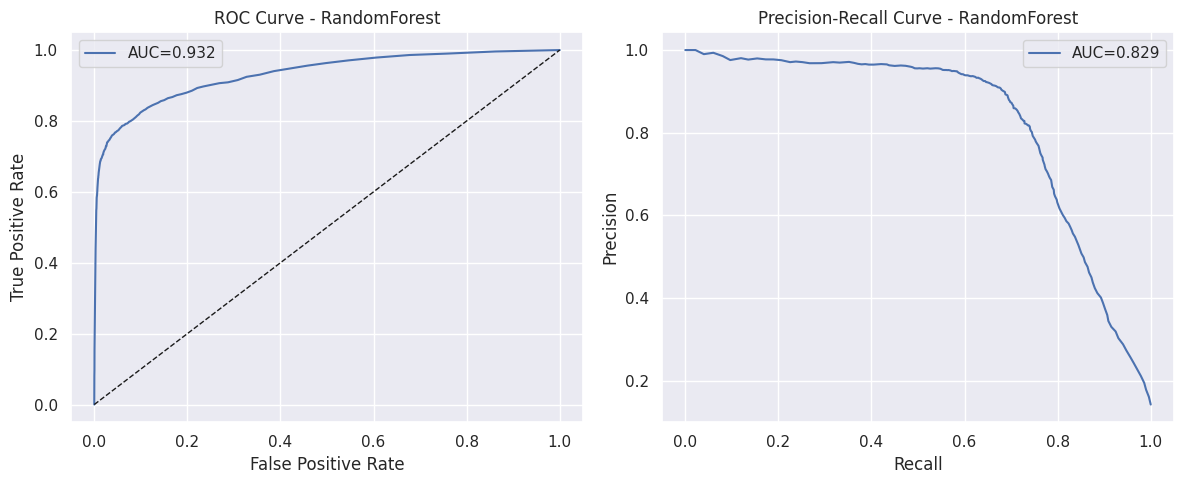

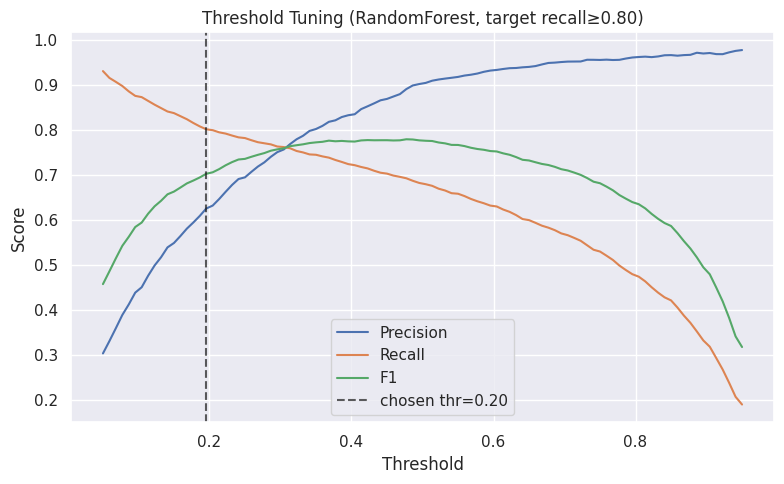

Confusion matrix @chosen thr:
 [[13885  1204]
 [  498  2007]]

Threshold candidates around target recall=0.80 (±0.03)
 threshold  precision  recall    f1  accuracy   TP   FP  FN    TN  recall_gap
     0.205      0.632   0.799 0.706     0.905 2002 1168 503 13921       0.001
     0.200      0.625   0.801 0.702     0.903 2007 1204 498 13885       0.001
     0.210      0.638   0.798 0.709     0.907 1999 1134 506 13955       0.002
     0.195      0.617   0.804 0.698     0.901 2014 1252 491 13837       0.004
     0.215      0.646   0.794 0.713     0.909 1990 1090 515 13999       0.006
     0.190      0.609   0.808 0.694     0.899 2023 1301 482 13788       0.008
     0.220      0.653   0.792 0.716     0.910 1985 1057 520 14032       0.008
     0.225      0.662   0.792 0.721     0.913 1983 1012 522 14077       0.008
     0.185      0.601   0.811 0.690     0.896 2032 1350 473 13739       0.011
     0.230      0.669   0.788 0.724     0.914 1975  978 530 14111       0.012
     0.235      0.677   

In [ ]:
full_threshold_workflow(rf_model, X_test, y_test,
                        model_name="RandomForest",
                        target_recall=0.80, around_window=0.03)

Accuracy : 0.9108
Recall   : 0.7054
Precision: 0.6801
F1       : 0.6925

Classification Report:

              precision    recall  f1-score   support

           0       0.95      0.94      0.95     15089
           1       0.68      0.71      0.69      2505

    accuracy                           0.91     17594
   macro avg       0.82      0.83      0.82     17594
weighted avg       0.91      0.91      0.91     17594



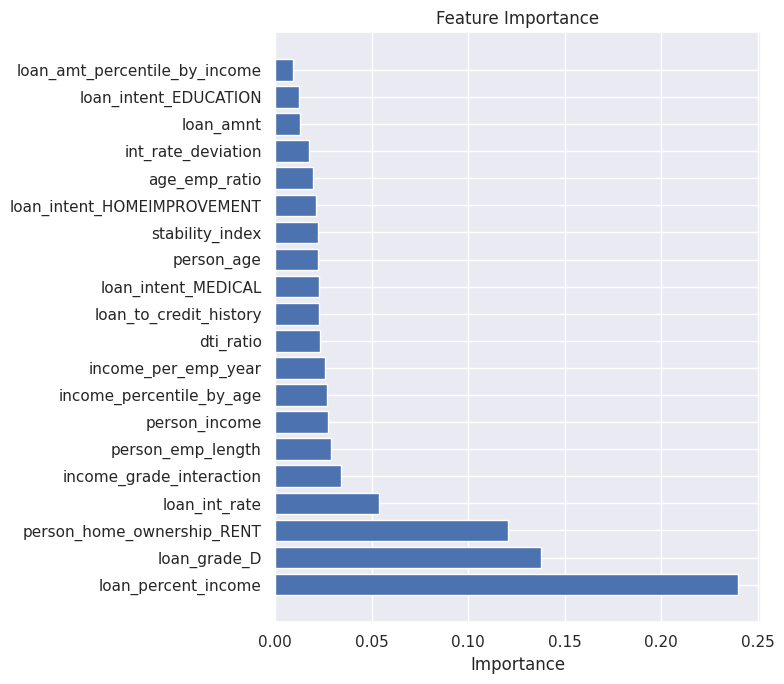

In [ ]:
cart_model = DecisionTreeClassifier(random_state=17).fit(X_train, y_train)
y_pred = cart_model.predict(X_test)

print(f"Accuracy : {round(accuracy_score(y_test, y_pred), 4)}")
print(f"Recall   : {round(recall_score(y_test, y_pred), 4)}")
print(f"Precision: {round(precision_score(y_test, y_pred), 4)}")
print(f"F1       : {round(f1_score(y_test, y_pred), 4)}")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

plot_importance(cart_model, X)